# Воспроизведение оптимизатора из научной статьи

## Adan против AdamW

## Цель работы

Воспроизвести алгоритм оптимизации Adan,
предложенный в научной публикации
Xie X. et al., и провести его сравнительное
исследование с базовым оптимизатором AdamW.

Проверить, проявляются ли заявленные авторами
преимущества Adan по скорости сходимости,
качеству обучения и устойчивости
на небольшой полносвязной нейронной сети
в задаче бинарной классификации.

## Научная публикация

Xie X., Zhou P., Li H., Lin Z., Yan S.
Adan: Adaptive Nesterov Momentum Algorithm
for Faster Optimizing Deep Models.
arXiv:2208.06677, 2022.

Для исследования используется редакция v5
от 29 ноября 2024 года.

- [Страница научной публикации](https://arxiv.org/abs/2208.06677)
- [Полный текст, версия v5](https://arxiv.org/pdf/2208.06677v5)
- [Официальный репозиторий авторов](https://github.com/sail-sg/Adan)

Основой математической реализации являются:

- раздел 3.1 — базовые адаптивные алгоритмы;
- раздел 3.2 — математическая структура Adan;
- Algorithm 1 — правила обновления параметров;
- раздел 4 — теоретический анализ сходимости;
- раздел 5 — экспериментальные результаты;
- приложение B.4 — особенности реализации;
- приложение B.5 — исследование компонентов
  и настроек алгоритма.

## Основная идея исследуемого метода

Adan (Adaptive Nesterov Momentum Algorithm)
представляет собой адаптивный метод
оптимизации первого порядка.

В отличие от AdamW, он использует не только
текущий градиент и накопленные статистики,
но и разность последовательных стохастических
градиентов.

Основная модификация заключается
в использовании оценки импульса Нестерова
(Nesterov Momentum Estimation, NME)
для построения адаптивного направления
обновления параметров.

При этом дополнительное вычисление градиента
в экстраполированной точке не требуется.

В публикации исследуются преимущества Adan
при обучении различных архитектур глубоких
нейронных сетей, включая ResNet, ConvNext,
ViT и другие модели.

В настоящей работе проверяется проявление
данных преимуществ в существенно меньшем
вычислительном эксперименте.

## Постановка задачи

Исходные признаки генерируются независимо
из равномерного распределения:

$$
X\in\mathbb{R}^{600\times3},
\qquad x_{ij}\sim U(-1,1).
$$

Истинная вероятность принадлежности
к положительному классу:

$$
p_i=\sigma\left(
1.3x_{i1}
+0.9\sin(\pi x_{i2})
-0.6x_{i3}^2
\right).
$$

Сигмоидальная функция:

$$
\sigma(u)=\frac{1}{1+e^{-u}}.
$$

Целевая переменная генерируется согласно
распределению Бернулли:

$$
y_i\sim\operatorname{Bernoulli}(p_i),
\qquad y_i\in\{0,1\}.
$$

Сначала генерируется матрица признаков,
затем бинарная целевая переменная.

Для воспроизводимости используется
numpy.random.default_rng(931).

## Параметры эксперимента

| Параметр | Значение |
|---|---|
| Тип задачи | Бинарная классификация |
| Количество наблюдений | 600 |
| Количество признаков | 3 |
| Распределение признаков | $U(-1,1)$ |
| Seed генерации данных | 931 |
| Random state разбиения | 1031 |
| Seed инициализации сети | 1, 2, 3, 4, 5 |
| Архитектура сети | 3 → 8 → 1 |
| Количество обучаемых параметров | 41 |
| Активация скрытого слоя | Tanh |
| Активация выходного слоя | Sigmoid |
| Инициализация весов | Xavier Uniform |
| Инициализация смещений | Нулевая |
| Функция потерь | Binary Cross-Entropy |
| Размер мини-батча | 32 |
| Шагов обновления за запуск | 200 |
| Повторений каждого метода | 5 |
| Количество оптимизаторов | 2 |
| Количество основных запусков | 10 |
| Общее количество шагов | 2000 |
| Вычислительная точность | float64 |
| Вычислительное устройство | CPU |

## Исследуемые оптимизаторы

| Метод | Роль | Основная характеристика |
|---|---|---|
| AdamW | Базовый метод (baseline) | Адаптивные оценки первого и второго моментов градиента |
| Adan | Исследуемый метод | Адаптивные оценки градиента и разности последовательных градиентов |

Оба оптимизатора относятся к методам
первого порядка.

Явное вычисление матрицы Гессе,
матрицы Gauss–Newton и их факторизаций
не используется.

## Гиперпараметры оптимизаторов

**AdamW**

$$
\eta=0.005,
$$

$$
\beta_1=0.9,\qquad
\beta_2=0.99,
$$

$$
\varepsilon=10^{-8},
\qquad \lambda=0.
$$

Начальные состояния первого и второго
моментов равны нулю.

Используется коррекция смещения
накопленных моментов.

**Adan**

$$
\eta=0.005,
$$

$$
\beta_1=0.9,\qquad
\beta_2=0.92,\qquad
\beta_3=0.99,
$$

$$
\varepsilon=10^{-8},
\qquad \lambda=0.
$$

Начальные состояния трёх накопленных
моментов равны нулю.

Используется коррекция смещения
всех трёх моментов.

На первом шаге разность градиентов
принимается равной нулю.

## Согласование обозначений со статьёй

В научной публикации и авторском коде
используются различные обозначения
коэффициентов экспоненциального усреднения.

Обозначим коэффициенты статьи через
$\beta_j^{paper}$, а коэффициенты
программной реализации через $\beta_j$.

Между ними выполняется соотношение:

$$
\beta_j^{paper}=1-\beta_j.
$$

| Коэффициент | Программная реализация | Обозначение статьи |
|---|---:|---:|
| $\beta_1$ | 0.90 | 0.10 |
| $\beta_2$ | 0.92 | 0.08 |
| $\beta_3$ | 0.99 | 0.01 |

В дальнейшем используются обозначения
программной реализации.

Гиперпараметры, указанные в задании,
имеют приоритет над значениями
по умолчанию из научной публикации.

## Особенности реализации Adan

Воспроизводится практическая версия алгоритма
с коррекцией смещения моментов, описанная
в приложении B.4 научной публикации
и реализованная в официальном коде авторов.

Используются следующие настройки:

| Настройка | Значение |
|---|---|
| Коррекция смещения моментов | Включена |
| Начальные моменты | Нулевые |
| Разность градиентов на первом шаге | Нулевая |
| Проксимальная форма weight decay | Используется |
| Weight decay | 0 |
| Gradient clipping | Отключён |
| Restart strategy | Отключена |
| Learning rate scheduler | Не используется |
| Warmup | Не используется |
| Fused-операции | Не используются |
| Foreach-операции | Не используются |

Стратегия перезапуска отключена
в соответствии с основными экспериментами
авторов научной публикации.

Поскольку $\lambda=0$, проксимальное
обновление не приводит к дополнительному
уменьшению весов.

Для весовых матриц и смещений применяется
одна и та же конвенция регуляризации.

Оба оптимизатора реализуются самостоятельно.
Авторский код и библиотечные реализации
используются для контрольной проверки
правил обновления.

## Разделение выборки

| Выборка | Доля | Количество наблюдений | Назначение |
|---|---:|---:|---|
| Train | 70% | 420 | Обучение сети |
| Validation | 15% | 90 | Выбор лучшей итерации |
| Test | 15% | 90 | Итоговая независимая оценка |

Сначала выделяется тестовая выборка
размером 15% исходных данных.

Затем из оставшихся наблюдений выделяется
валидационная выборка в доле 15/85.

Для обоих разбиений используется
random_state = 1031.

Разбиения выполняются со стратификацией
по бинарной целевой переменной.

## Организация обучения с мини-батчами

В отличие от оптимизации по полному градиенту,
обновление параметров выполняется
с использованием стохастического градиента
мини-батча.

Размер мини-батча:

$$
B=32.
$$

В начале каждой эпохи индексы обучающих
наблюдений переставляются детерминированным
генератором случайных чисел,
инициализированным seed текущего повтора.

Поскольку обучающая выборка содержит
420 наблюдений, одна полная эпоха включает:

$$
420=13\cdot32+4.
$$

Таким образом, одна эпоха содержит
13 полных мини-батчей по 32 наблюдения
и один заключительный мини-батч
из четырёх наблюдений.

Оставшиеся наблюдения не отбрасываются.

После завершения эпохи выполняется
новая перестановка обучающих индексов.

Состояния оптимизаторов при переходе
к следующей эпохе не сбрасываются.

Для каждого seed заранее формируется
единая последовательность из 200 мини-батчей.

AdamW и Adan внутри одного повторения
используют одинаковые:

- начальные параметры нейронной сети;
- обучающие, валидационные и тестовые данные;
- последовательности мини-батчей;
- функции потерь;
- вычислительную точность;
- бюджеты обновлений параметров.

## Выбор гиперпараметров

Основной эксперимент проводится
с заданной скоростью обучения:

$$
\eta_0=0.005.
$$

Дополнительный подбор скорости обучения
в основном эксперименте не выполняется.

Это позволяет непосредственно сравнить
оптимизаторы при настройках,
установленных в задании.

Итоговое состояние каждой модели выбирается
по минимальной валидационной функции потерь:

$$
t^*=
\arg\min_{t\in\{0,\ldots,200\}}
L_{\mathrm{val}}(\theta_t).
$$

Тестовая выборка не используется
для выбора оптимизатора, гиперпараметров
или лучшей итерации.

## Критерии сравнительной оценки

**Качество оптимизации**

- Потери на текущем мини-батче.
- Полные обучающие потери.
- Валидационные потери.
- Минимальный validation loss.
- Итерация достижения минимальных
  валидационных потерь.
- Норма полного обучающего градиента.
- Норма стохастического градиента.
- Норма обновления параметров.

**Скорость достижения качества**

До проведения эксперимента устанавливается
единый контрольный уровень:

$$
L_{\mathrm{val}}\leq0.60.
$$

Определяется первая итерация достижения
данного уровня, если он достигнут.

Дополнительно сравниваются накопленные
вычислительные затраты и время.

Контрольный уровень после получения
результатов не изменяется.

**Качество классификации**

- Binary Cross-Entropy.
- Accuracy.
- F1-macro.
- ROC-AUC.

**Устойчивость**

- Разброс результатов между пятью
  начальными инициализациями.
- Разброс градиентов и обновлений параметров.
- Количество отклонённых обновлений.
- Наличие нечисловых значений.

**Вычислительные затраты**

- Количество вычислений функции потерь.
- Количество основных обратных проходов.
- Количество диагностических обратных проходов.
- Количество обработанных наблюдений.
- Количество вычислений разности градиентов.
- Количество операций с матрицами кривизны.
- Время оптимизации.
- Полное время с диагностикой.
- Пиковая дополнительная память.
- Размер постоянного состояния оптимизатора.

Диагностическое вычисление полного градиента
выполняется отдельно от вычисления
стохастического градиента мини-батча.

Полный градиент не используется
для обновления параметров оптимизатора.

## Исследовательские вопросы

1. Обеспечивает ли Adan более быстрое
   уменьшение функции потерь при одинаковом
   бюджете обновлений параметров?

2. Позволяет ли учёт разности последовательных
   градиентов улучшить качество оптимизации?

3. Насколько отличаются вычислительные
   затраты Adan и AdamW?

4. Как исследуемые методы различаются
   по устойчивости к начальной инициализации
   и последовательности мини-батчей?

5. Проявляется ли преимущество Adan
   по итоговому тестовому качеству?

6. Насколько результаты небольшого
   синтетического эксперимента согласуются
   с результатами научной публикации?

## Правила интерпретации результатов

Преимущество Adan не предполагается заранее.

Отсутствие преимущества или ухудшение
отдельных показателей рассматривается
как допустимый результат исследования.

Итоги представляются в формате среднего
значения и выборочного стандартного
отклонения по пяти повторениям.

При интерпретации учитываются различия
между настоящим экспериментом
и экспериментами авторов публикации:

- архитектура нейронной сети;
- количество обучаемых параметров;
- размер и характер данных;
- размер мини-батча;
- бюджет обучения;
- вычислительная среда;
- отсутствие дополнительной регуляризации.

Исследование представляет собой воспроизведение
алгоритма оптимизации и проверку его свойств
в новых экспериментальных условиях,
а не точное повторение экспериментов статьи.

## Математическая модель нейронной сети

Используется полносвязная нейронная сеть
с одним скрытым слоем:

$$
3\rightarrow8\rightarrow1.
$$

Входной вектор наблюдения:

$$
x_i=(x_{i1},x_{i2},x_{i3})^T
\in\mathbb{R}^3.
$$

Прямой проход нейронной сети:

$$
a_i=W_1x_i+b_1,
$$

$$
h_i=\tanh(a_i),
$$

$$
z_i=W_2h_i+b_2,
$$

$$
\hat p_i=\sigma(z_i).
$$

### Размерность параметров

| Параметр | Размерность | Количество элементов |
|---|---|---:|
| $W_1$ | $8\times3$ | 24 |
| $b_1$ | $8$ | 8 |
| $W_2$ | $1\times8$ | 8 |
| $b_2$ | $1$ | 1 |
| Всего | | 41 |

Все обучаемые параметры объединяются
в единый вектор:

$$
\theta=
\begin{pmatrix}
\operatorname{vec}(W_1)\\
b_1\\
\operatorname{vec}(W_2)\\
b_2
\end{pmatrix}
\in\mathbb{R}^{41}.
$$

Для начальных весовых матриц используется
инициализация Xavier Uniform:

$$
W_{ij}\sim U\left(
-\sqrt{\frac{6}{n_{in}+n_{out}}},
\sqrt{\frac{6}{n_{in}+n_{out}}}
\right).
$$

Для первого слоя:

$$
W_{1,ij}\sim U\left(
-\sqrt{\frac{6}{11}},
\sqrt{\frac{6}{11}}
\right).
$$

Для второго слоя:

$$
W_{2,ij}\sim U\left(
-\sqrt{\frac{6}{9}},
\sqrt{\frac{6}{9}}
\right).
$$

Начальные смещения:

$$
b_1=0_8,\qquad b_2=0.
$$

## Функция потерь и стохастический градиент

Индивидуальная бинарная кросс-энтропия:

$$
\ell_i(\theta)=
-y_i\ln\hat p_i
-(1-y_i)\ln(1-\hat p_i).
$$

Полная обучающая функция потерь:

$$
L_{\mathrm{train}}(\theta)=
\frac{1}{420}
\sum_{i\in I_{\mathrm{train}}}
\ell_i(\theta).
$$

На шаге $t$ используется мини-батч
с множеством индексов $\mathcal{B}_t$.

Функция потерь мини-батча:

$$
L_{\mathcal{B}_t}(\theta)=
\frac{1}{|\mathcal{B}_t|}
\sum_{i\in\mathcal{B}_t}
\ell_i(\theta).
$$

Стохастический градиент:

$$
g_t=
\nabla_\theta
L_{\mathcal{B}_t}(\theta_{t-1}).
$$

Оба оптимизатора используют данный градиент
для обновления параметров.

Для диагностики дополнительно вычисляется
полный обучающий градиент:

$$
g_t^{\mathrm{full}}=
\nabla_\theta L_{\mathrm{train}}(\theta_t).
$$

Его евклидова норма:

$$
\|g_t^{\mathrm{full}}\|_2=
\sqrt{
\sum_{j=1}^{41}
\left(
\frac{\partial L_{\mathrm{train}}}
{\partial\theta_j}
\right)^2
}.
$$

Полный градиент используется исключительно
для анализа траектории оптимизации.

Он не передаётся оптимизатору
и не изменяет его внутреннее состояние.

Для численной устойчивости бинарная
кросс-энтропия вычисляется через логиты
с помощью BCEWithLogitsLoss.

## Базовый оптимизатор AdamW

AdamW использует экспоненциальные скользящие
средние градиента и его квадрата.

Начальные состояния:

$$
m_0=0,\qquad v_0=0.
$$

На шаге $t=1,\ldots,200$ вычисляются
следующие величины.

**Первый момент градиента**

$$
m_t=\beta_1m_{t-1}
+(1-\beta_1)g_t.
$$

**Второй момент градиента**

$$
v_t=\beta_2v_{t-1}
+(1-\beta_2)g_t^2.
$$

Возведение в квадрат выполняется покомпонентно.

**Коррекция смещения**

Нулевые начальные состояния приводят
к смещению накопленных моментов
в начале обучения.

Для его компенсации используются:

$$
\hat m_t=
\frac{m_t}{1-\beta_1^t},
$$

$$
\hat v_t=
\frac{v_t}{1-\beta_2^t}.
$$

**Обновление параметров**

$$
\theta_t=
(1-\eta\lambda)\theta_{t-1}
-
\eta
\frac{\hat m_t}
{\sqrt{\hat v_t}+\varepsilon}.
$$

Согласно условиям задания:

$$
\eta=0.005,
\qquad \beta_1=0.9,
\qquad \beta_2=0.99,
$$

$$
\varepsilon=10^{-8},
\qquad\lambda=0.
$$

Поэтому фактическое правило обновления:

$$
\theta_t=
\theta_{t-1}
-
0.005
\frac{\hat m_t}
{\sqrt{\hat v_t}+10^{-8}}.
$$

При отключённом weight decay
AdamW математически совпадает с Adam
при одинаковых остальных настройках.

## Теоретическая основа Adan

### Мотивация авторов

В разделе 3.1 научной публикации
рассматривается связь адаптивных методов
с методом тяжёлого шара
и ускорением Нестерова.

Adam накапливает скользящее среднее
предыдущих градиентов.

Классическое ускорение Нестерова
использует градиент, вычисленный
в экстраполированной точке.

Это позволяет учитывать информацию
о предполагаемом дальнейшем направлении
движения параметров.

Однако явное формирование экстраполированной
точки усложняет реализацию алгоритма
в системах глубокого обучения.

В частности, возникает необходимость
в дополнительной работе с параметрами
и их промежуточными состояниями.

Авторы Adan предлагают эквивалентное
при условиях, указанных в Lemma 1,
преобразование ускоренного метода.

Оно позволяет вычислять градиент
в текущей точке и учитывать изменение
последовательных градиентов.

### Nesterov Momentum Estimation

В обозначениях научной публикации
оценка скорректированного градиента
имеет вид:

$$
g'_k=
g_k+(1-\beta_1^{paper})(g_k-g_{k-1}).
$$

Здесь:

- $g_k$ — текущий стохастический градиент;
- $g_{k-1}$ — предыдущий градиент;
- $g_k-g_{k-1}$ — изменение градиента;
- $\beta_1^{paper}$ — коэффициент статьи.

В разделе 3.2 авторы разделяют накопление
самих градиентов и их разностей,
вводя отдельные коэффициенты усреднения.

Окончательное правило Adan использует
три накопленные статистики:

- первый момент градиента;
- первый момент разности градиентов;
- второй момент скорректированного градиента.

Таким образом, основное отличие Adan
от AdamW состоит в изменении структуры
накопленных моментов и направления
адаптивного обновления.

## Математические правила Adan из статьи

В Algorithm 1 научной публикации
используются следующие рекуррентные формулы:

$$
m_k=
(1-\beta_1^{paper})m_{k-1}
+\beta_1^{paper}g_k,
$$

$$
v_k=
(1-\beta_2^{paper})v_{k-1}
+\beta_2^{paper}(g_k-g_{k-1}),
$$

$$
n_k=
(1-\beta_3^{paper})n_{k-1}
+\beta_3^{paper}
\left[
g_k+
(1-\beta_2^{paper})(g_k-g_{k-1})
\right]^2.
$$

Адаптивное направление формируется
с использованием выражения:

$$
m_k+(1-\beta_2^{paper})v_k.
$$

Проксимальная форма обновления параметров:

$$
\theta_{k+1}=
\frac{
\theta_k-
\eta
\frac{
m_k+(1-\beta_2^{paper})v_k
}{
\sqrt{n_k}+\varepsilon
}
}{
1+\lambda_k\eta
}.
$$

Данные формулы соответствуют Algorithm 1
и разделу 3.2 публикации.

В теоретическом описании Algorithm 1
коррекция смещения моментов явно не записана.

В приложении B.4 авторы указывают,
что в практических экспериментах
используют de-bias strategy.

Кроме того, начальные состояния
теоретического алгоритма отличаются
от нулевых состояний практической реализации.

В настоящем эксперименте используются
нулевые моменты, заданные условием работы,
и коррекция смещения, соответствующая
практической реализации Adan.

## Правила Adan, используемые в программе

Далее применяются обозначения коэффициентов,
принятые в авторском программном коде:

$$
\beta_j=1-\beta_j^{paper}.
$$

Параметры исследования:

$$
\beta_1=0.9,\qquad
\beta_2=0.92,\qquad
\beta_3=0.99.
$$

### 1. Инициализация состояния

$$
m_0=0,\qquad
v_0=0,\qquad
n_0=0.
$$

Дополнительно сохраняется предыдущий
стохастический градиент.

На первой итерации в качестве предыдущего
градиента принимается текущий градиент:

$$
g_0=g_1.
$$

Данное соглашение не требует
дополнительного обратного прохода.

Следовательно:

$$
\Delta g_1=g_1-g_0=0.
$$

### 2. Разность последовательных градиентов

$$
\Delta g_t=g_t-g_{t-1}.
$$

Разность учитывает изменение градиента
между последовательными шагами.

### 3. Первый момент градиента

$$
m_t=
\beta_1m_{t-1}
+(1-\beta_1)g_t.
$$

При заданных коэффициентах:

$$
m_t=0.9m_{t-1}+0.1g_t.
$$

### 4. Первый момент разности градиентов

$$
v_t=
\beta_2v_{t-1}
+(1-\beta_2)\Delta g_t.
$$

При заданных коэффициентах:

$$
v_t=
0.92v_{t-1}+0.08\Delta g_t.
$$

Данная накопленная статистика отсутствует
в базовом оптимизаторе AdamW.

### 5. Скорректированный градиент

$$
q_t=g_t+\beta_2\Delta g_t.
$$

В рассматриваемом эксперименте:

$$
q_t=g_t+0.92(g_t-g_{t-1}).
$$

Скорректированный градиент используется
для построения второго момента.

### 6. Второй момент скорректированного градиента

$$
n_t=
\beta_3n_{t-1}
+(1-\beta_3)q_t^2.
$$

При заданных коэффициентах:

$$
n_t=
0.99n_{t-1}
+0.01
\left[
g_t+0.92\Delta g_t
\right]^2.
$$

Все операции возведения в квадрат
выполняются покомпонентно.

### 7. Коррекция смещения моментов

В практической реализации используются
следующие скорректированные оценки:

$$
\hat m_t=
\frac{m_t}{1-\beta_1^t},
$$

$$
\hat v_t=
\frac{v_t}{1-\beta_2^t},
$$

$$
\hat n_t=
\frac{n_t}{1-\beta_3^t}.
$$

### 8. Формирование направления обновления

Скорректированный числитель:

$$
u_t=\hat m_t+\beta_2\hat v_t.
$$

Адаптивный знаменатель:

$$
r_t=\sqrt{\hat n_t}+\varepsilon.
$$

Итоговое направление спуска в смысле
правила обновления оптимизатора:

$$
d_t=
-\frac{
\hat m_t+\beta_2\hat v_t
}{
\sqrt{\hat n_t}+\varepsilon
}.
$$

В отличие от детерминированных методов
с поиском шага, данное направление
не обязано удовлетворять условию
$g_t^Td_t<0$ на каждой итерации.

### 9. Обновление параметров

Полная проксимальная форма Adan:

$$
\theta_t=
\frac{
\theta_{t-1}
-
\eta
\frac{
\hat m_t+\beta_2\hat v_t
}{
\sqrt{\hat n_t}+\varepsilon
}
}{
1+\eta\lambda
}.
$$

Согласно условию задания:

$$
\eta=0.005,
\qquad\varepsilon=10^{-8},
\qquad\lambda=0.
$$

Поэтому непосредственно в данном
эксперименте применяется правило:

$$
\boxed{
\theta_t=
\theta_{t-1}
-
0.005
\frac{
\hat m_t+0.92\hat v_t
}{
\sqrt{\hat n_t}+10^{-8}
}
}
$$

### 10. Сохранение состояния

После обновления параметров
текущий градиент сохраняется
для следующей итерации.

Состояние оптимизатора содержит:

$$
\mathcal{S}_t=
\{m_t,v_t,n_t,g_t,t\}.
$$

При переходе между эпохами
данное состояние не сбрасывается.

## Анализ ключевой модификации Adan

В отличие от AdamW, второй момент Adan
строится на основе квадрата выражения:

$$
q_t=g_t+\beta_2\Delta g_t.
$$

Раскроем покомпонентный квадрат:

$$
q_t^2=
g_t^2+
2\beta_2g_t\Delta g_t+
\beta_2^2(\Delta g_t)^2.
$$

Таким образом, вторая накопленная
статистика Adan учитывает:

- квадрат текущего градиента;
- взаимодействие текущего градиента
  с его изменением;
- квадрат изменения градиента.

Это отличается от AdamW, где второй момент
формируется только на основе $g_t^2$.

Разность градиентов влияет одновременно
на числитель и знаменатель
адаптивного обновления Adan.

Поэтому её использование не означает
обязательного увеличения длины шага.

В зависимости от накопленных статистик
обновление может увеличиваться,
уменьшаться или изменять направление.

## Особенности разности стохастических градиентов

При вычислении полного детерминированного
градиента справедливо локальное приближение:

$$
\nabla L(\theta_{t-1})
-
\nabla L(\theta_{t-2})
\approx
\nabla^2L(\theta_{t-2})
(\theta_{t-1}-\theta_{t-2}).
$$

Однако в исследуемом эксперименте
используются разные мини-батчи.

Поэтому фактическая разность имеет вид:

$$
\Delta g_t=
\nabla L_{\mathcal{B}_t}(\theta_{t-1})
-
\nabla L_{\mathcal{B}_{t-1}}(\theta_{t-2}).
$$

Она содержит информацию как об изменении
параметров сети, так и об изменении
состава мини-батчей.

Представим стохастический градиент
через полный градиент и ошибку оценки:

$$
g_t=
\nabla L_{\mathrm{train}}(\theta_{t-1})
+\xi_t.
$$

Тогда:

$$
\begin{aligned}
\Delta g_t={}&
\nabla L_{\mathrm{train}}(\theta_{t-1})
-
\nabla L_{\mathrm{train}}(\theta_{t-2})\\
&+\xi_t-\xi_{t-1}.
\end{aligned}
$$

Следовательно, разность стохастических
градиентов нельзя отождествлять
с точной информацией о кривизне.

Adan остаётся методом первого порядка.

Он не вычисляет:

- матрицу Гессе;
- якобиан отдельных выходов сети
  в явном матричном виде;
- матрицу Gauss–Newton;
- произведение Гессе на вектор;
- матричные факторизации.

## Анализ первого шага

При нулевых начальных моментах
и $\Delta g_1=0$ для Adan получаем:

$$
m_1=(1-\beta_1)g_1,
$$

$$
v_1=0,
$$

$$
n_1=(1-\beta_3)g_1^2.
$$

После коррекции смещения:

$$
\hat m_1=g_1,
\qquad
\hat v_1=0,
\qquad
\hat n_1=g_1^2.
$$

Следовательно:

$$
\theta_1^{Adan}
=
\theta_0-
\eta\frac{g_1}{|g_1|+\varepsilon}.
$$

Для AdamW при нулевых моментах
и отключённом weight decay:

$$
\theta_1^{AdamW}
=
\theta_0-
\eta\frac{g_1}{|g_1|+\varepsilon}.
$$

Таким образом, при одинаковых начальных
параметрах, первом мини-батче,
скорости обучения и $\varepsilon$
первый шаг обоих методов совпадает
в точной арифметике:

$$
\theta_1^{Adan}
=
\theta_1^{AdamW}.
$$

Различия между оптимизаторами
могут проявляться начиная со второго шага.

Данное свойство используется
для контрольной проверки реализации.

## Сравнение математической структуры

| Характеристика | AdamW | Adan |
|---|---|---|
| Порядок метода | Первый | Первый |
| Стохастический градиент | Да | Да |
| Первый момент градиента | Да | Да |
| Разность последовательных градиентов | Нет | Да |
| Момент разности градиентов | Нет | Да |
| Второй момент | Исходный градиент | Скорректированный градиент |
| Коррекция смещения | Два момента | Три момента |
| Предыдущий градиент в состоянии | Нет | Да |
| Основные обратные проходы на шаг | 1 | 1 |
| Вычисление Гессе | Нет | Нет |
| Факторизация матриц | Нет | Нет |
| Дополнительная регуляризация | Нет | Нет |
| Автоматические перезапуски | Нет | Нет |

## Теоретические вычислительные затраты

Пусть $P$ — количество обучаемых параметров.

В рассматриваемой нейронной сети:

$$
P=41.
$$

Оба оптимизатора используют покомпонентные
векторные операции.

Дополнительная вычислительная сложность
обновления AdamW:

$$
T_{\mathrm{AdamW}}=O(P).
$$

Дополнительная вычислительная сложность
обновления Adan:

$$
T_{\mathrm{Adan}}=O(P).
$$

Данные оценки не включают стоимость
прямого и обратного проходов нейронной сети.

Несмотря на одинаковый асимптотический
порядок сложности, Adan выполняет больше
векторных операций на каждой итерации.

### Постоянное числовое состояние

При использовании float64
один числовой элемент занимает 8 байт.

AdamW хранит два вектора моментов:

$$
M_{\mathrm{AdamW}}
=
2\cdot41\cdot8
=656\text{ байт}.
$$

Adan хранит три накопленных момента
и предыдущий градиент:

$$
M_{\mathrm{Adan}}
=
4\cdot41\cdot8
=1312\text{ байт}.
$$

| Структура | AdamW | Adan |
|---|---:|---:|
| Первый момент градиента | 41 | 41 |
| Момент разности градиентов | 0 | 41 |
| Второй момент | 41 | 41 |
| Предыдущий градиент | 0 | 41 |
| Всего числовых элементов | 82 | 164 |
| Объём, байт | 656 | 1312 |

Таким образом, постоянное числовое состояние
Adan занимает в два раза больше памяти,
чем состояние AdamW.

В расчёт не включаются счётчик итераций,
параметры сети, временные тензоры,
служебные структуры и история эксперимента.

Пиковая дополнительная память
измеряется отдельно.

## Учёт обратных проходов

На каждой итерации для обновления параметров
необходимо одно вычисление градиента
текущего мини-батча.

За 200 итераций при отсутствии ошибок
и отклонённых обновлений каждый метод
выполняет:

$$
N_{\mathrm{backward}}^{opt}=200.
$$

Для диагностики сохраняются полный
обучающий градиент и его норма
в начальной точке и после каждого шага:

$$
N_{\mathrm{backward}}^{diag}=201.
$$

Общее количество обратных проходов
с учётом диагностики:

$$
N_{\mathrm{backward}}^{total}
=
200+201=401.
$$

Вычисления разности градиентов Adan
не требуют дополнительных обратных проходов.

При сравнении времени отдельно измеряется
работа оптимизаторов без диагностических
вычислений и сохранения полной истории.

## Теоретические результаты публикации

В разделе 4 авторы анализируют
сходимость Adan на невыпуклых
стохастических задачах.

При выполнении условий гладкости
и ограниченности стохастических градиентов
теоретическая сложность нахождения
приближённой стационарной точки составляет:

$$
O(\epsilon^{-4}).
$$

При дополнительных предположениях
о липшицевой непрерывности Гессе,
соответствующих настройках алгоритма
и применении стратегии перезапуска
получена оценка:

$$
O(\epsilon^{-3.5}).
$$

Здесь $\epsilon$ обозначает требуемую
точность приближения к стационарной точке,
а не численный стабилизатор
$\varepsilon=10^{-8}$ в знаменателе
адаптивного обновления.

Теоретические оценки получены
при определённых предположениях
и правилах выбора гиперпараметров.

Поэтому они не гарантируют,
что Adan превзойдёт AdamW
в каждом конечном эксперименте.

В рассматриваемой практической работе
стратегия перезапуска не используется.

Следовательно, эксперимент не является
прямой проверкой теоретической оценки
$O(\epsilon^{-3.5})$.

## Проверяемые положения научной публикации

В разделе 5 и на рисунке 1 публикации
авторы демонстрируют более быстрое
уменьшение функции потерь Adan
по сравнению с рядом базовых оптимизаторов.

В частности, исследуется обучение
ResNet-50 и ViT-S на ImageNet.

В настоящей работе проверяются
следующие эмпирические положения:

1. Adan может быстрее уменьшать
   обучающую функцию потерь
   при одинаковом числе обратных проходов.

2. Учёт разности градиентов может улучшать
   адаптивное обновление параметров.

3. Дополнительные векторные операции Adan
   могут компенсироваться сокращением
   времени достижения заданного качества.

4. Преимущество по скорости оптимизации
   может сопровождаться улучшением
   качества на независимых данных.

5. Дополнительная память Adan
   должна учитываться при сравнении
   вычислительной эффективности.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from time import perf_counter

import gc
import json
import tempfile
import tracemalloc

from pathlib import Path
from torch.profiler import profile, ProfilerActivity


# =============================================
# Вычислительная среда
# =============================================

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)

device = torch.device("cpu")


# =============================================
# Параметры генерации данных
# =============================================

n = 600
n_features = 3

seed = 931
split_seed = seed + 100


# =============================================
# Архитектура нейронной сети
# =============================================

input_size = 3
hidden_size = 8
output_size = 1

n_parameters = (
    input_size * hidden_size
    + hidden_size
    + hidden_size * output_size
    + output_size
)

assert n_parameters == 41


# =============================================
# Параметры сравнительного эксперимента
# =============================================

iterations = 200

batch_size = 32

network_seeds = [1, 2, 3, 4, 5]

n_repeats = len(network_seeds)

methods = [
    "AdamW",
    "Adan"
]

quality_threshold = 0.60

classification_threshold = 0.5


# =============================================
# Настройки оптимизаторов
# =============================================

config = {
    "AdamW": {
        "eta": 0.005,
        "beta1": 0.9,
        "beta2": 0.99,
        "eps": 1e-8,
        "weight_decay": 0.0
    },

    "Adan": {
        "eta": 0.005,
        "beta1": 0.9,
        "beta2": 0.92,
        "beta3": 0.99,
        "eps": 1e-8,
        "weight_decay": 0.0,
        "restart": False,
        "max_grad_norm": 0.0,
        "no_prox": False
    }
}


# =============================================
# Генерация синтетических данных
# =============================================

rng = np.random.default_rng(seed)

# Независимые равномерно распределённые признаки
X = rng.uniform(
    -1.0,
    1.0,
    size=(n, n_features)
)

# Истинные логиты
true_logits = (
    1.3 * X[:, 0]
    + 0.9 * np.sin(np.pi * X[:, 1])
    - 0.6 * X[:, 2] ** 2
)

# Истинные вероятности положительного класса
p_true = expit(true_logits)

# Генерация бинарных меток по распределению Бернулли
y = rng.binomial(
    n=1,
    p=p_true
).astype(np.float64)


# =============================================
# Стратифицированное разделение выборки
# =============================================

indices = np.arange(n)

# Первое разбиение:
# 85% — Train + Validation
# 15% — Test
train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=split_seed,
    shuffle=True,
    stratify=y
)

# Второе разбиение:
# 15/85 оставшейся выборки — Validation
n_val = int(round(0.15 * n))

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=n_val,
    random_state=split_seed,
    shuffle=True,
    stratify=y[train_val_idx]
)


# =============================================
# Преобразование данных в тензоры PyTorch
# =============================================

def make_tensors(idx):

    X_tensor = torch.tensor(
        X[idx],
        dtype=torch.float64,
        device=device
    )

    y_tensor = torch.tensor(
        y[idx],
        dtype=torch.float64,
        device=device
    ).reshape(-1, 1)

    return X_tensor, y_tensor


X_train, y_train = make_tensors(train_idx)

X_val, y_val = make_tensors(val_idx)

X_test, y_test = make_tensors(test_idx)


# =============================================
# Проверки исходных данных
# =============================================

assert X.shape == (600, 3)

assert y.shape == (600,)

assert X.dtype == np.float64
assert y.dtype == np.float64

assert np.isfinite(X).all()
assert np.isfinite(y).all()

assert np.all(
    (X >= -1.0) & (X <= 1.0)
)

assert np.all(
    (p_true > 0) & (p_true < 1)
)

assert set(np.unique(y)) == {0.0, 1.0}


# =============================================
# Проверки разделения выборки
# =============================================

assert len(train_idx) == 420

assert len(val_idx) == 90

assert len(test_idx) == 90

# Отсутствие пересечений
assert len(
    np.intersect1d(train_idx, val_idx)
) == 0

assert len(
    np.intersect1d(train_idx, test_idx)
) == 0

assert len(
    np.intersect1d(val_idx, test_idx)
) == 0

# Все исходные наблюдения включены в разбиение
assert np.array_equal(
    np.sort(
        np.concatenate([
            train_idx,
            val_idx,
            test_idx
        ])
    ),
    indices
)

# Наличие обоих классов в каждой выборке
for idx in [
    train_idx,
    val_idx,
    test_idx
]:

    assert set(np.unique(y[idx])) == {
        0.0, 1.0
    }


# =============================================
# Проверки тензоров
# =============================================

assert X_train.shape == (420, 3)
assert y_train.shape == (420, 1)

assert X_val.shape == (90, 3)
assert y_val.shape == (90, 1)

assert X_test.shape == (90, 3)
assert y_test.shape == (90, 1)

for tensor in [
    X_train, y_train,
    X_val, y_val,
    X_test, y_test
]:

    assert tensor.dtype == torch.float64

    assert torch.isfinite(tensor).all()

    assert tensor.device == device


# =============================================
# Проверка воспроизводимости генерации
# =============================================

rng_check = np.random.default_rng(seed)

X_check = rng_check.uniform(
    -1.0,
    1.0,
    size=(n, n_features)
)

p_check = expit(
    1.3 * X_check[:, 0]
    + 0.9 * np.sin(np.pi * X_check[:, 1])
    - 0.6 * X_check[:, 2] ** 2
)

y_check = rng_check.binomial(
    n=1,
    p=p_check
).astype(np.float64)

assert np.array_equal(X, X_check)

assert np.array_equal(p_true, p_check)

assert np.array_equal(y, y_check)


# =============================================
# Проверка воспроизводимости разбиения
# =============================================

train_val_check, test_check = train_test_split(
    indices,
    test_size=0.15,
    random_state=split_seed,
    shuffle=True,
    stratify=y
)

train_check, val_check = train_test_split(
    train_val_check,
    test_size=n_val,
    random_state=split_seed,
    shuffle=True,
    stratify=y[train_val_check]
)

assert np.array_equal(train_idx, train_check)
assert np.array_equal(val_idx, val_check)
assert np.array_equal(test_idx, test_check)


# =============================================
# Таблица исходных наблюдений
# =============================================

data = pd.DataFrame({
    "x1": X[:, 0],
    "x2": X[:, 1],
    "x3": X[:, 2],
    "true_logit": true_logits,
    "p_true": p_true,
    "y": y.astype(int)
})

data["split"] = ""

data.loc[train_idx, "split"] = "Train"

data.loc[val_idx, "split"] = "Validation"

data.loc[test_idx, "split"] = "Test"

print("Первые 10 обучающих наблюдений:")

display(
    data.loc[train_idx].head(10).round(6)
)


# =============================================
# Характеристики выборок
# =============================================

split_records = []

for name, idx in [
    ("Все данные", indices),
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:

    class_0 = int(np.sum(y[idx] == 0))

    class_1 = int(np.sum(y[idx] == 1))

    split_records.append({
        "Выборка": name,

        "Количество наблюдений": len(idx),

        "Доля выборки": len(idx) / n,

        "Класс 0": class_0,

        "Класс 1": class_1,

        "Доля класса 0": class_0 / len(idx),

        "Доля класса 1": class_1 / len(idx)
    })


split_summary = pd.DataFrame(split_records)

print("\nХарактеристики выборок:")

display(
    split_summary.style
    .hide(axis="index")
    .format({
        "Доля выборки": "{:.2%}",
        "Доля класса 0": "{:.2%}",
        "Доля класса 1": "{:.2%}"
    })
)


# =============================================
# Описательная статистика обучающих данных
# =============================================

print("\nОписательная статистика Train:")

display(
    data.loc[
        train_idx,
        ["x1", "x2", "x3", "true_logit", "p_true"]
    ]
    .describe()
    .T
    .round(6)
)


# =============================================
# Организация мини-батчей
# =============================================

n_train = len(train_idx)

full_batches_per_epoch = n_train // batch_size

last_batch_size = n_train % batch_size

batches_per_epoch = (
    full_batches_per_epoch
    + int(last_batch_size > 0)
)

completed_epochs = iterations // batches_per_epoch

remaining_steps = iterations % batches_per_epoch

print("\nОрганизация обучения:")

print("Размер мини-батча:", batch_size)

print(
    "Полных мини-батчей за эпоху:",
    full_batches_per_epoch
)

print(
    "Размер последнего мини-батча:",
    last_batch_size
)

print(
    "Всего мини-батчей за эпоху:",
    batches_per_epoch
)

print(
    "Полностью завершённых эпох:",
    completed_epochs
)

print(
    "Шагов в следующей эпохе:",
    remaining_steps
)


# =============================================
# Теоретические характеристики задачи
# =============================================

p_train_true = p_true[train_idx]

expected_bayes_accuracy = np.mean(
    np.maximum(
        p_train_true,
        1 - p_train_true
    )
)

expected_bayes_loss = -np.mean(
    p_train_true * np.log(p_train_true)
    + (1 - p_train_true)
    * np.log(1 - p_train_true)
)

print("\nТеоретические ориентиры на обучающих X:")

print(
    "Ожидаемая байесовская accuracy:",
    f"{expected_bayes_accuracy:.4%}"
)

print(
    "Минимальная ожидаемая BCE:",
    f"{expected_bayes_loss:.8f}"
)

print(
    "BCE при постоянной вероятности 0.5:",
    f"{np.log(2):.8f}"
)


# =============================================
# Итоговые настройки эксперимента
# =============================================

print("\nРазмерности тензоров:")

print("X_train:", tuple(X_train.shape))
print("y_train:", tuple(y_train.shape))

print("X_val:", tuple(X_val.shape))
print("y_val:", tuple(y_val.shape))

print("X_test:", tuple(X_test.shape))
print("y_test:", tuple(y_test.shape))

print("\nПараметры эксперимента:")

print("Seed генерации данных:", seed)

print("Seed разбиения:", split_seed)

print("Seed инициализации сети:", network_seeds)

print("Количество параметров сети:", n_parameters)

print("Количество методов:", len(methods))

print("Количество повторений:", n_repeats)

print("Шагов за один запуск:", iterations)

print(
    "Количество основных запусков:",
    len(methods) * n_repeats
)

print(
    "Общее количество шагов:",
    len(methods) * n_repeats * iterations
)

print(
    "Контрольный уровень validation loss:",
    quality_threshold
)

print("\nВычислительная среда:")

print("Версия NumPy:", np.__version__)

print("Версия PyTorch:", torch.__version__)

print("Тип данных:", X_train.dtype)

print("Устройство:", device)

print("Количество потоков:", torch.get_num_threads())

print("\nВсе проверки данных и воспроизводимости пройдены.")

Первые 10 обучающих наблюдений:


,x1,x2,x3,true_logit,p_true,y,split
187,0.240826,-0.055108,0.010909,0.157966,0.539410,0,Train
31,-0.784109,-0.885904,0.685421,-1.616958,0.165625,0,Train
554,0.319522,0.984620,-0.761826,0.110621,0.527627,1,Train
476,-0.943125,-0.711871,0.391794,-2.026050,0.116495,0,Train
340,0.474953,0.835299,-0.235799,1.029255,0.736771,1,Train
132,0.948626,-0.738812,-0.561264,0.385837,0.595280,1,Train
43,-0.857374,-0.613402,-0.375905,-2.042855,0.114776,0,Train
112,-0.589357,-0.360496,0.825877,-1.990348,0.120220,0,Train
263,0.540521,-0.274145,0.918777,-0.486606,0.380693,1,Train
396,0.146254,0.071243,-0.440217,0.273614,0.567980,0,Train



Характеристики выборок:


Выборка,Количество наблюдений,Доля выборки,Класс 0,Класс 1,Доля класса 0,Доля класса 1
Все данные,600,100.00%,329,271,54.83%,45.17%
Train,420,70.00%,231,189,55.00%,45.00%
Validation,90,15.00%,49,41,54.44%,45.56%
Test,90,15.00%,49,41,54.44%,45.56%



Описательная статистика Train:


,count,mean,std,min,25%,50%,75%,max
x1,420.0,-0.003640,0.572666,-0.999757,-0.499039,-0.013365,0.452608,0.996170
x2,420.0,-0.028324,0.581946,-0.991182,-0.532655,-0.057974,0.454328,0.996909
x3,420.0,-0.004509,0.592021,-0.997323,-0.530992,-0.005148,0.506245,0.997151
true_logit,420.0,-0.270730,0.945787,-2.394497,-0.960474,-0.235753,0.396451,1.907969
p_true,420.0,0.444012,0.201959,0.083593,0.276784,0.441334,0.597832,0.870791



Организация обучения:
Размер мини-батча: 32
Полных мини-батчей за эпоху: 13
Размер последнего мини-батча: 4
Всего мини-батчей за эпоху: 14
Полностью завершённых эпох: 14
Шагов в следующей эпохе: 4

Теоретические ориентиры на обучающих X:
Ожидаемая байесовская accuracy: 67.6106%
Минимальная ожидаемая BCE: 0.59902868
BCE при постоянной вероятности 0.5: 0.69314718

Размерности тензоров:
X_train: (420, 3)
y_train: (420, 1)
X_val: (90, 3)
y_val: (90, 1)
X_test: (90, 3)
y_test: (90, 1)

Параметры эксперимента:
Seed генерации данных: 931
Seed разбиения: 1031
Seed инициализации сети: [1, 2, 3, 4, 5]
Количество параметров сети: 41
Количество методов: 2
Количество повторений: 5
Шагов за один запуск: 200
Количество основных запусков: 10
Общее количество шагов: 2000
Контрольный уровень validation loss: 0.6

Вычислительная среда:
Версия NumPy: 2.5.5
Версия PyTorch: 2.15.0+cpu
Тип данных: torch.float64
Устройство: cpu
Количество потоков: 1

Все проверки данных и воспроизводимости пройдены.


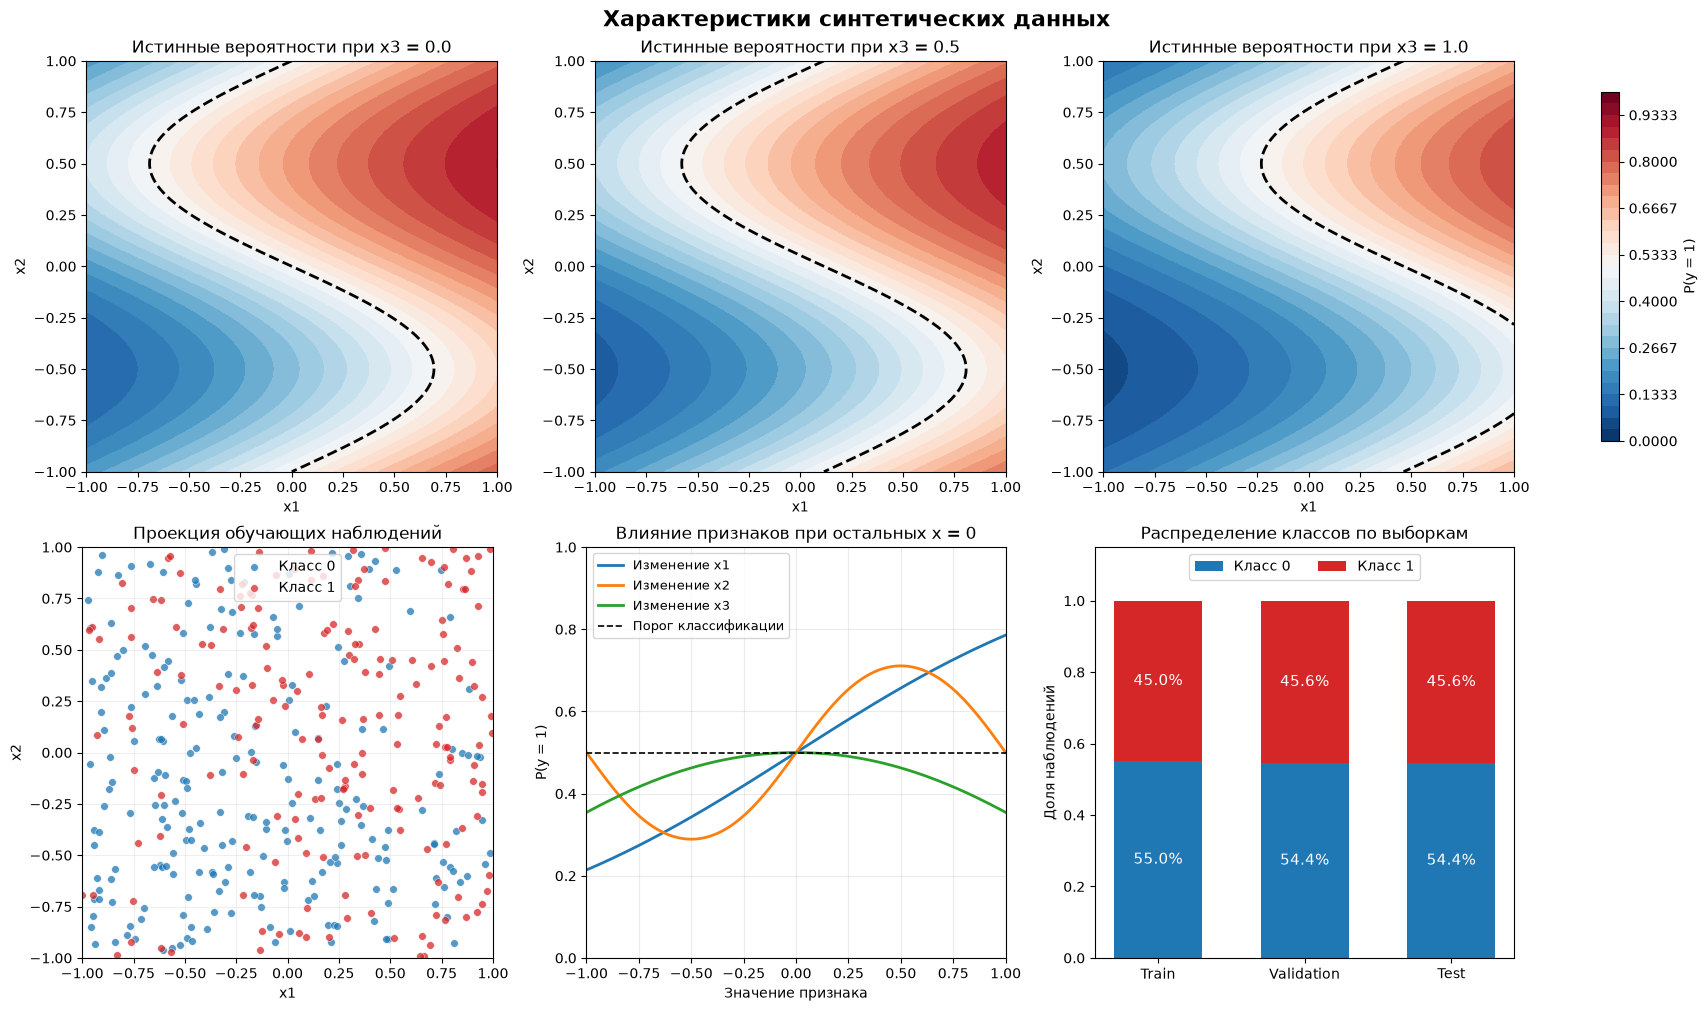

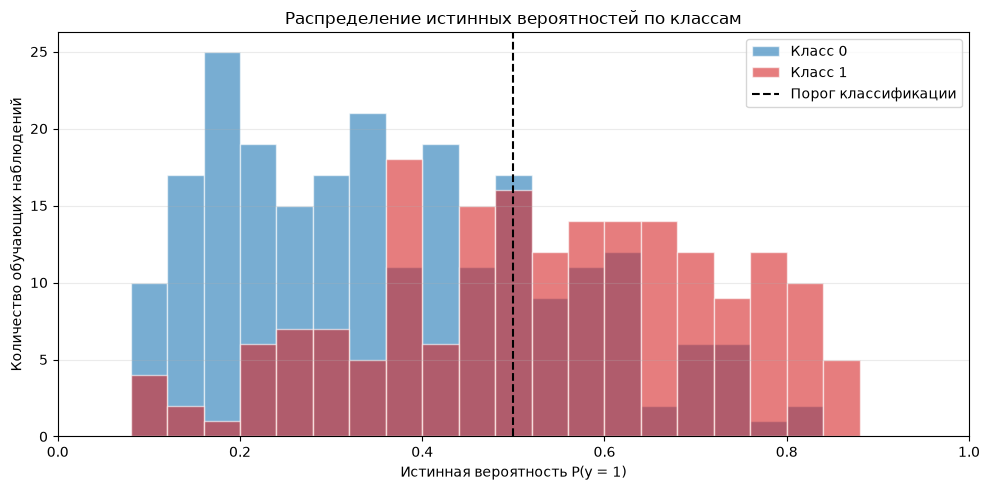

Характеристики сечений истинной зависимости:


Фиксированное x3,Минимальная вероятность,Максимальная вероятность,Средняя вероятность,Доля области класса 1
0.000000,0.099753,0.900247,0.500000,50.00%
0.500000,0.087068,0.885945,0.469206,44.26%
1.000000,0.057326,0.832014,0.378796,28.09%



Погрешность симметрии по x3: 0.00000000e+00
Ожидаемая байесовская accuracy: 67.6106%
Минимальная ожидаемая BCE: 0.59902868

Визуализация исходной зависимости завершена.


In [2]:
# =============================================
# Истинная функция вероятностей
# =============================================

def true_probability_function(x1, x2, x3):

    logits = (
        1.3 * x1
        + 0.9 * np.sin(np.pi * x2)
        - 0.6 * x3 ** 2
    )

    return expit(logits)


# Проверка соответствия генератору данных
assert np.allclose(
    true_probability_function(
        X[:, 0],
        X[:, 1],
        X[:, 2]
    ),
    p_true,
    atol=1e-12,
    rtol=1e-12
)


# =============================================
# Координатная сетка
# =============================================

grid = np.linspace(-1.0, 1.0, 200)

X1_grid, X2_grid = np.meshgrid(
    grid,
    grid
)

x3_fixed_values = [0.0, 0.5, 1.0]

true_probability_slices = {}

for x3_fixed in x3_fixed_values:

    true_probability_slices[x3_fixed] = (
        true_probability_function(
            X1_grid,
            X2_grid,
            x3_fixed
        )
    )


# =============================================
# Визуализация исходной зависимости
# =============================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10),
    constrained_layout=True
)

probability_levels = np.linspace(
    0, 1, 31
)

class_colors = {
    0: "#1f77b4",
    1: "#d62728"
}


# =============================================
# 1–3. Сечения функции вероятностей
# =============================================

for ax, x3_fixed in zip(
    axes[0],
    x3_fixed_values
):

    probability_surface = (
        true_probability_slices[x3_fixed]
    )

    contour = ax.contourf(
        X1_grid,
        X2_grid,
        probability_surface,
        levels=probability_levels,
        cmap="RdBu_r"
    )

    # Теоретическая граница классификации
    ax.contour(
        X1_grid,
        X2_grid,
        probability_surface,
        levels=[0.5],
        colors="black",
        linestyles="--",
        linewidths=2
    )

    ax.set_title(
        f"Истинные вероятности при x3 = {x3_fixed}"
    )

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)

    ax.set_aspect("equal")


fig.colorbar(
    contour,
    ax=list(axes[0]),
    label="P(y = 1)",
    shrink=0.85
)


# =============================================
# 4. Проекция обучающих наблюдений
# =============================================

for class_id in [0, 1]:

    idx = train_idx[
        y[train_idx] == class_id
    ]

    axes[1, 0].scatter(
        X[idx, 0],
        X[idx, 1],
        color=class_colors[class_id],
        edgecolor="white",
        linewidth=0.4,
        s=30,
        alpha=0.75,
        label=f"Класс {class_id}"
    )

axes[1, 0].set_title(
    "Проекция обучающих наблюдений"
)

axes[1, 0].set_xlabel("x1")
axes[1, 0].set_ylabel("x2")

axes[1, 0].set_xlim(-1, 1)
axes[1, 0].set_ylim(-1, 1)

axes[1, 0].set_aspect("equal")

axes[1, 0].legend()

axes[1, 0].grid(alpha=0.2)


# =============================================
# 5. Влияние отдельных признаков
# =============================================

# Изменение x1 при x2 = x3 = 0
p_x1 = true_probability_function(
    grid,
    0,
    0
)

# Изменение x2 при x1 = x3 = 0
p_x2 = true_probability_function(
    0,
    grid,
    0
)

# Изменение x3 при x1 = x2 = 0
p_x3 = true_probability_function(
    0,
    0,
    grid
)

axes[1, 1].plot(
    grid,
    p_x1,
    linewidth=2,
    label="Изменение x1"
)

axes[1, 1].plot(
    grid,
    p_x2,
    linewidth=2,
    label="Изменение x2"
)

axes[1, 1].plot(
    grid,
    p_x3,
    linewidth=2,
    label="Изменение x3"
)

axes[1, 1].axhline(
    0.5,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Порог классификации"
)

axes[1, 1].set_title(
    "Влияние признаков при остальных x = 0"
)

axes[1, 1].set_xlabel(
    "Значение признака"
)

axes[1, 1].set_ylabel("P(y = 1)")

axes[1, 1].set_xlim(-1, 1)
axes[1, 1].set_ylim(0, 1)

axes[1, 1].grid(alpha=0.25)

axes[1, 1].legend(fontsize=9)


# =============================================
# 6. Распределение классов по выборкам
# =============================================

split_names = [
    "Train",
    "Validation",
    "Test"
]

class_0_shares = [
    np.mean(y[idx] == 0)
    for idx in [
        train_idx,
        val_idx,
        test_idx
    ]
]

class_1_shares = [
    np.mean(y[idx] == 1)
    for idx in [
        train_idx,
        val_idx,
        test_idx
    ]
]

bars_0 = axes[1, 2].bar(
    split_names,
    class_0_shares,
    color=class_colors[0],
    width=0.6,
    label="Класс 0"
)

bars_1 = axes[1, 2].bar(
    split_names,
    class_1_shares,
    bottom=class_0_shares,
    color=class_colors[1],
    width=0.6,
    label="Класс 1"
)

axes[1, 2].bar_label(
    bars_0,
    labels=[
        f"{value:.1%}"
        for value in class_0_shares
    ],
    label_type="center",
    color="white",
    fontsize=11
)

axes[1, 2].bar_label(
    bars_1,
    labels=[
        f"{value:.1%}"
        for value in class_1_shares
    ],
    label_type="center",
    color="white",
    fontsize=11
)

axes[1, 2].set_title(
    "Распределение классов по выборкам"
)

axes[1, 2].set_ylabel(
    "Доля наблюдений"
)

axes[1, 2].set_ylim(0, 1.15)

axes[1, 2].legend(
    loc="upper center",
    ncol=2
)

fig.suptitle(
    "Характеристики синтетических данных",
    fontsize=16,
    fontweight="bold"
)

plt.show()


# =============================================
# Распределение истинных вероятностей
# =============================================

fig, ax = plt.subplots(
    figsize=(10, 5)
)

bins = np.linspace(0, 1, 26)

for class_id in [0, 1]:

    idx = train_idx[
        y[train_idx] == class_id
    ]

    ax.hist(
        p_true[idx],
        bins=bins,
        color=class_colors[class_id],
        alpha=0.60,
        edgecolor="white",
        label=f"Класс {class_id}"
    )

ax.axvline(
    0.5,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Порог классификации"
)

ax.set_title(
    "Распределение истинных вероятностей по классам"
)

ax.set_xlabel(
    "Истинная вероятность P(y = 1)"
)

ax.set_ylabel(
    "Количество обучающих наблюдений"
)

ax.set_xlim(0, 1)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

plt.tight_layout()
plt.show()


# =============================================
# Проверка симметрии по третьему признаку
# =============================================

symmetry_error = np.max(
    np.abs(
        true_probability_function(
            X[:, 0],
            X[:, 1],
            X[:, 2]
        )
        -
        true_probability_function(
            X[:, 0],
            X[:, 1],
            -X[:, 2]
        )
    )
)

assert symmetry_error < 1e-12


# =============================================
# Характеристики сечений
# =============================================

slice_records = []

for x3_fixed in x3_fixed_values:

    surface = true_probability_slices[
        x3_fixed
    ]

    slice_records.append({
        "Фиксированное x3": x3_fixed,

        "Минимальная вероятность": surface.min(),

        "Максимальная вероятность": surface.max(),

        "Средняя вероятность": surface.mean(),

        "Доля области класса 1": (
            np.mean(surface >= 0.5)
        )
    })

slice_df = pd.DataFrame(
    slice_records
)

print("Характеристики сечений истинной зависимости:")

display(
    slice_df.style
    .hide(axis="index")
    .format({
        "Минимальная вероятность": "{:.6f}",
        "Максимальная вероятность": "{:.6f}",
        "Средняя вероятность": "{:.6f}",
        "Доля области класса 1": "{:.2%}"
    })
)

print(
    "\nПогрешность симметрии по x3:",
    f"{symmetry_error:.8e}"
)

print(
    "Ожидаемая байесовская accuracy:",
    f"{expected_bayes_accuracy:.4%}"
)

print(
    "Минимальная ожидаемая BCE:",
    f"{expected_bayes_loss:.8f}"
)

print(
    "\nВизуализация исходной зависимости завершена."
)

Архитектура нейронной сети:
ClassificationNetwork(
  (fc1): Linear(in_features=3, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=1, bias=True)
)

Количество параметров: 41

Границы Xavier Uniform:
W1: [-0.73854895, 0.73854895]
W2: [-0.81649658, 0.81649658]

Характеристики начальных состояний:


Seed,Количество параметров,Норма параметров,Train loss,Validation loss,Train accuracy,Минимальная вероятность,Максимальная вероятность
1,41,1.99389420,0.70979245,0.70273417,40.48%,0.44199344,0.55592373
2,41,2.17339882,0.67250649,0.70880055,61.19%,0.27303721,0.72006805
3,41,2.28156393,0.65912624,0.67087760,59.52%,0.31513859,0.69198132
4,41,2.34806218,0.82448771,0.79983389,33.33%,0.25709959,0.74032145
5,41,2.32671773,0.70548209,0.69428257,45.95%,0.39896573,0.60366953



Начальные векторы параметров:


,Seed 1,Seed 2,Seed 3,Seed 4,Seed 5
theta_1,-0.37923356,-0.71324696,-0.16303757,0.41389145,0.02012544
theta_2,-0.22260411,0.35019262,-0.15588021,0.21473146,0.36834560
theta_3,-0.08261061,0.18429515,0.13530222,0.05696281,0.43013445
theta_4,-0.13755801,0.01650416,-0.23375993,-0.47389265,0.05127460
theta_5,-0.31618981,0.16858883,-0.18692445,-0.46128356,0.01800462
theta_6,0.44843688,-0.06145722,0.21557225,-0.30401123,-0.66768081
theta_7,-0.26326928,-0.15772849,0.12280422,0.05307101,-0.68099689
theta_8,-0.20102914,0.61647236,-0.29846387,-0.57711585,0.03561495
theta_9,-0.29762068,-0.34848898,-0.64102453,0.52936355,-0.52746420
theta_10,0.24155110,0.05657700,0.26643433,0.71843027,0.30897789



Характеристики последовательностей мини-батчей:


Seed,Всего мини-батчей,Полных мини-батчей,Неполных мини-батчей,Завершённых эпох,Начатых эпох,Обработано наблюдений
1,200,186,14,14,15,6008
2,200,186,14,14,15,6008
3,200,186,14,14,15,6008
4,200,186,14,14,15,6008
5,200,186,14,14,15,6008



Первые 16 мини-батчей при seed = 1:


Шаг,Эпоха,Номер батча,Размер батча,Первые 5 исходных индексов,Доля класса 1
1,1,1,32,"[490, 534, 155, 136, 52]",37.50%
2,1,2,32,"[201, 521, 570, 456, 22]",43.75%
3,1,3,32,"[60, 85, 416, 304, 167]",53.12%
4,1,4,32,"[561, 443, 206, 301, 135]",59.38%
5,1,5,32,"[385, 571, 73, 145, 406]",53.12%
6,1,6,32,"[45, 408, 562, 112, 340]",50.00%
7,1,7,32,"[438, 367, 109, 596, 235]",53.12%
8,1,8,32,"[319, 309, 284, 11, 2]",43.75%
9,1,9,32,"[334, 260, 25, 591, 329]",40.62%
10,1,10,32,"[594, 465, 50, 90, 41]",37.50%


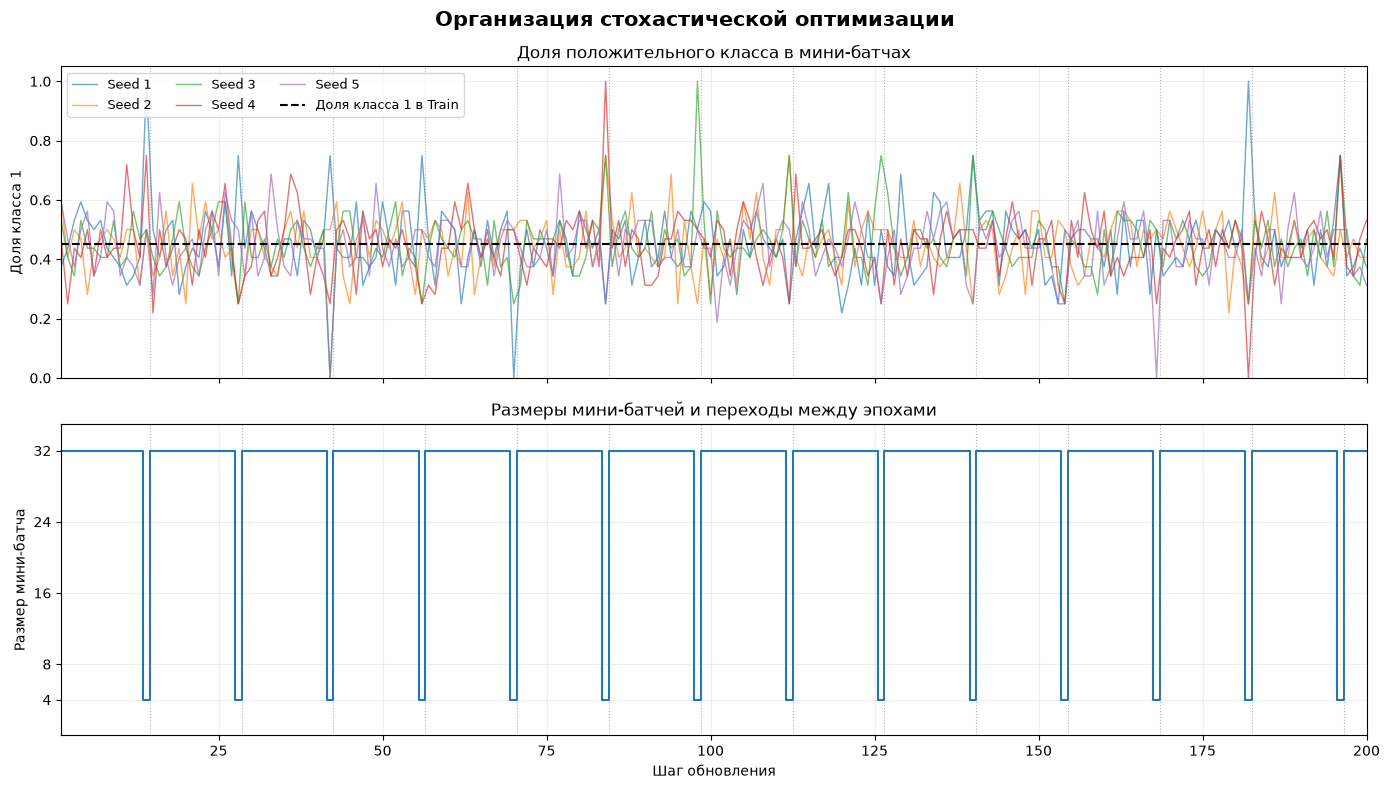


Количество начальных состояний: 5
Количество последовательностей: 5
Мини-батчей в каждой последовательности: 200
Обработано наблюдений за один запуск: 6008
Размер полного мини-батча: 32
Размер неполного мини-батча: 4

Все проверки архитектуры пройдены.
Все проверки мини-батчей пройдены.
Начальные состояния воспроизводимы.
Последовательности мини-батчей воспроизводимы.
Пересечения с Validation и Test отсутствуют.
Данные для парного сравнения подготовлены.


In [3]:
# =============================================
# Архитектура нейронной сети
# =============================================

class ClassificationNetwork(nn.Module):

    def __init__(self):

        super().__init__()

        self.fc1 = nn.Linear(
            input_size,
            hidden_size
        )

        self.fc2 = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        h = torch.tanh(self.fc1(x))

        return self.fc2(h)


# =============================================
# Воспроизводимая инициализация сети
# =============================================

def initialize_network(network_seed):

    torch.manual_seed(network_seed)

    model = ClassificationNetwork().to(
        device=device,
        dtype=torch.float64
    )

    with torch.no_grad():

        nn.init.xavier_uniform_(
            model.fc1.weight
        )

        nn.init.zeros_(
            model.fc1.bias
        )

        nn.init.xavier_uniform_(
            model.fc2.weight
        )

        nn.init.zeros_(
            model.fc2.bias
        )

    return model


# =============================================
# Объединение параметров в единый вектор
# =============================================

def get_parameters(model):

    return torch.cat([
        parameter.detach().reshape(-1)
        for parameter in model.parameters()
    ]).clone()


# Размеры отдельных блоков параметров
w1_size = input_size * hidden_size

b1_size = hidden_size

w2_size = hidden_size * output_size

b2_size = output_size

assert (
    w1_size + b1_size + w2_size + b2_size
    == n_parameters
)


# =============================================
# Восстановление матриц и смещений
# =============================================

def unpack_parameters(theta):

    W1 = theta[:w1_size].reshape(
        hidden_size,
        input_size
    )

    b1 = theta[
        w1_size:w1_size + b1_size
    ]

    offset = w1_size + b1_size

    W2 = theta[
        offset:offset + w2_size
    ].reshape(
        output_size,
        hidden_size
    )

    b2 = theta[offset + w2_size:]

    return W1, b1, W2, b2


# =============================================
# Прямой проход через вектор параметров
# =============================================

def forward_logits(theta, X_data):

    W1, b1, W2, b2 = unpack_parameters(theta)

    hidden = torch.tanh(
        X_data @ W1.T + b1
    )

    logits = hidden @ W2.T + b2

    return logits


# Вероятности положительного класса
def predict_proba(theta, X_data):

    return torch.sigmoid(
        forward_logits(theta, X_data)
    )


# =============================================
# Численно устойчивая функция потерь
# =============================================

loss_function = nn.BCEWithLogitsLoss(
    reduction="mean"
)


def loss_value(theta, X_data, y_data):

    logits = forward_logits(
        theta,
        X_data
    )

    return loss_function(
        logits,
        y_data
    )


# =============================================
# Границы инициализации Xavier Uniform
# =============================================

xavier_bound_1 = np.sqrt(
    6 / (input_size + hidden_size)
)

xavier_bound_2 = np.sqrt(
    6 / (hidden_size + output_size)
)


# =============================================
# Формирование пяти начальных состояний
# =============================================

initial_parameters = {}

initial_records = []

for network_seed in network_seeds:

    model = initialize_network(
        network_seed
    )

    theta = get_parameters(model)

    initial_parameters[network_seed] = (
        theta.clone()
    )

    W1, b1, W2, b2 = unpack_parameters(
        theta
    )

    # Проверки размерностей
    assert theta.shape == (41,)

    assert W1.shape == (8, 3)
    assert b1.shape == (8,)

    assert W2.shape == (1, 8)
    assert b2.shape == (1,)

    # Проверка точности
    assert theta.dtype == torch.float64

    assert torch.isfinite(theta).all()

    # Проверка нулевых смещений
    assert torch.all(b1 == 0)
    assert torch.all(b2 == 0)

    # Проверка границ Xavier Uniform
    assert torch.all(
        torch.abs(W1) <= xavier_bound_1
    )

    assert torch.all(
        torch.abs(W2) <= xavier_bound_2
    )

    # Проверка воспроизводимости инициализации
    control_model = initialize_network(
        network_seed
    )

    assert torch.equal(
        theta,
        get_parameters(control_model)
    )

    with torch.no_grad():

        # Проверка двух способов прямого прохода
        logits_model = model(X_train)

        logits_vector = forward_logits(
            theta,
            X_train
        )

        assert torch.allclose(
            logits_model,
            logits_vector,
            atol=1e-12,
            rtol=1e-12
        )

        train_probabilities = predict_proba(
            theta,
            X_train
        )

        train_loss_initial = loss_value(
            theta,
            X_train,
            y_train
        ).item()

        val_loss_initial = loss_value(
            theta,
            X_val,
            y_val
        ).item()

        train_accuracy_initial = (
            (
                train_probabilities
                >= classification_threshold
            )
            == y_train
        ).double().mean().item()

    initial_records.append({
        "Seed": network_seed,

        "Количество параметров": theta.numel(),

        "Норма параметров": (
            torch.linalg.vector_norm(theta).item()
        ),

        "Train loss": train_loss_initial,

        "Validation loss": val_loss_initial,

        "Train accuracy": train_accuracy_initial,

        "Минимальная вероятность": (
            train_probabilities.min().item()
        ),

        "Максимальная вероятность": (
            train_probabilities.max().item()
        )
    })


# Проверка различий между начальными состояниями
for i, seed_i in enumerate(network_seeds):

    for seed_j in network_seeds[i + 1:]:

        assert not torch.equal(
            initial_parameters[seed_i],
            initial_parameters[seed_j]
        )


# =============================================
# Характеристики начальных состояний
# =============================================

initial_df = pd.DataFrame(
    initial_records
)

print("Архитектура нейронной сети:")

print(model)

print("\nКоличество параметров:", n_parameters)

print("\nГраницы Xavier Uniform:")

print(
    f"W1: [{-xavier_bound_1:.8f}, "
    f"{xavier_bound_1:.8f}]"
)

print(
    f"W2: [{-xavier_bound_2:.8f}, "
    f"{xavier_bound_2:.8f}]"
)

print("\nХарактеристики начальных состояний:")

display(
    initial_df.style
    .hide(axis="index")
    .format({
        "Норма параметров": "{:.8f}",
        "Train loss": "{:.8f}",
        "Validation loss": "{:.8f}",
        "Train accuracy": "{:.2%}",
        "Минимальная вероятность": "{:.8f}",
        "Максимальная вероятность": "{:.8f}"
    })
)


# =============================================
# Сохранение начальных векторов параметров
# =============================================

initial_theta_df = pd.DataFrame({
    f"Seed {network_seed}":
        initial_parameters[network_seed].numpy()

    for network_seed in network_seeds
})

initial_theta_df.index = [
    f"theta_{j + 1}"
    for j in range(n_parameters)
]

print("\nНачальные векторы параметров:")

display(
    initial_theta_df.style
    .format("{:.8f}")
)


# =============================================
# Детерминированное формирование мини-батчей
# =============================================

def generate_batch_schedule(
    network_seed,
    n_steps=iterations
):

    batch_rng = np.random.default_rng(
        network_seed
    )

    schedule = []

    epoch = 0

    while len(schedule) < n_steps:

        epoch += 1

        # Новая перестановка в начале каждой эпохи
        permutation = batch_rng.permutation(
            n_train
        )

        for batch_number, start in enumerate(
            range(0, n_train, batch_size),
            start=1
        ):

            if len(schedule) >= n_steps:

                break

            # Последний неполный батч сохраняется
            local_indices = permutation[
                start:start + batch_size
            ].copy()

            batch_indices = torch.tensor(
                local_indices,
                dtype=torch.long,
                device=device
            )

            schedule.append({
                "step": len(schedule) + 1,

                "epoch": epoch,

                "batch_in_epoch": batch_number,

                "batch_size": len(local_indices),

                # Индексы внутри обучающей выборки
                "indices": batch_indices,

                # Индексы в исходном датасете
                "original_indices": (
                    train_idx[local_indices].copy()
                )
            })

    return schedule


# =============================================
# Формирование общих последовательностей
# =============================================

batch_schedules = {}

batch_schedule_records = []

expected_processed_samples = (
    completed_epochs * n_train
    + remaining_steps * batch_size
)

assert expected_processed_samples == 6008

for network_seed in network_seeds:

    schedule = generate_batch_schedule(
        network_seed
    )

    batch_schedules[network_seed] = schedule

    # Повторная генерация для проверки
    control_schedule = generate_batch_schedule(
        network_seed
    )

    assert len(schedule) == iterations

    assert len(control_schedule) == iterations

    for record, control_record in zip(
        schedule,
        control_schedule
    ):

        # Проверка воспроизводимости
        assert record["step"] == (
            control_record["step"]
        )

        assert record["epoch"] == (
            control_record["epoch"]
        )

        assert torch.equal(
            record["indices"],
            control_record["indices"]
        )

        # Проверка корректности индексов
        idx = record["indices"]

        assert idx.dtype == torch.long

        assert torch.all(idx >= 0)

        assert torch.all(idx < n_train)

        assert len(torch.unique(idx)) == len(idx)

        assert 1 <= len(idx) <= batch_size

        # Проверка отсутствия утечки данных
        assert len(
            np.intersect1d(
                record["original_indices"],
                val_idx
            )
        ) == 0

        assert len(
            np.intersect1d(
                record["original_indices"],
                test_idx
            )
        ) == 0

    # =========================================
    # Проверка структуры завершённых эпох
    # =========================================

    for epoch in range(
        1,
        completed_epochs + 1
    ):

        epoch_batches = [
            record
            for record in schedule
            if record["epoch"] == epoch
        ]

        assert len(epoch_batches) == 14

        batch_sizes = [
            record["batch_size"]
            for record in epoch_batches
        ]

        assert batch_sizes == (
            [32] * 13 + [4]
        )

        epoch_indices = torch.cat([
            record["indices"]
            for record in epoch_batches
        ])

        # Все обучающие наблюдения используются
        # ровно один раз за завершённую эпоху
        assert len(epoch_indices) == n_train

        assert torch.equal(
            torch.sort(epoch_indices).values,
            torch.arange(
                n_train,
                dtype=torch.long,
                device=device
            )
        )

    # =========================================
    # Проверка последней неполной эпохи
    # =========================================

    last_epoch_batches = [
        record
        for record in schedule
        if record["epoch"] == completed_epochs + 1
    ]

    assert len(last_epoch_batches) == (
        remaining_steps
    )

    last_epoch_indices = torch.cat([
        record["indices"]
        for record in last_epoch_batches
    ])

    assert len(last_epoch_indices) == 128

    assert len(
        torch.unique(last_epoch_indices)
    ) == 128

    # =========================================
    # Подсчёт обработанных наблюдений
    # =========================================

    processed_samples = sum(
        record["batch_size"]
        for record in schedule
    )

    assert processed_samples == (
        expected_processed_samples
    )

    n_full_batches = sum(
        record["batch_size"] == batch_size
        for record in schedule
    )

    n_partial_batches = sum(
        record["batch_size"] < batch_size
        for record in schedule
    )

    assert n_full_batches == 186

    assert n_partial_batches == 14

    batch_schedule_records.append({
        "Seed": network_seed,

        "Всего мини-батчей": len(schedule),

        "Полных мини-батчей": n_full_batches,

        "Неполных мини-батчей": n_partial_batches,

        "Завершённых эпох": completed_epochs,

        "Начатых эпох": schedule[-1]["epoch"],

        "Обработано наблюдений": processed_samples
    })


# Проверка различий последовательностей
# между независимыми повторениями
for i, seed_i in enumerate(network_seeds):

    for seed_j in network_seeds[i + 1:]:

        assert not all(
            torch.equal(
                record_i["indices"],
                record_j["indices"]
            )

            for record_i, record_j in zip(
                batch_schedules[seed_i],
                batch_schedules[seed_j]
            )
        )


# =============================================
# Сводные характеристики мини-батчей
# =============================================

batch_schedule_df = pd.DataFrame(
    batch_schedule_records
)

print("\nХарактеристики последовательностей мини-батчей:")

display(
    batch_schedule_df.style
    .hide(axis="index")
)


# =============================================
# Пример последовательности для seed = 1
# =============================================

example_records = []

for record in batch_schedules[1][:16]:

    original_indices = record[
        "original_indices"
    ]

    example_records.append({
        "Шаг": record["step"],

        "Эпоха": record["epoch"],

        "Номер батча": record["batch_in_epoch"],

        "Размер батча": record["batch_size"],

        "Первые 5 исходных индексов": (
            original_indices[:5].tolist()
        ),

        "Доля класса 1": (
            np.mean(y[original_indices])
        )
    })

print("\nПервые 16 мини-батчей при seed = 1:")

display(
    pd.DataFrame(example_records)
    .style
    .hide(axis="index")
    .format({
        "Доля класса 1": "{:.2%}"
    })
)


# =============================================
# Визуализация последовательности мини-батчей
# =============================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

for network_seed in network_seeds:

    schedule = batch_schedules[network_seed]

    steps = [
        record["step"]
        for record in schedule
    ]

    class_shares = [
        np.mean(
            y[record["original_indices"]]
        )
        for record in schedule
    ]

    axes[0].plot(
        steps,
        class_shares,
        linewidth=1,
        alpha=0.65,
        label=f"Seed {network_seed}"
    )

axes[0].axhline(
    y_train.mean().item(),
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Доля класса 1 в Train"
)

axes[0].set_title(
    "Доля положительного класса в мини-батчах"
)

axes[0].set_ylabel("Доля класса 1")

axes[0].set_ylim(0, 1.05)

axes[0].legend(
    ncol=3,
    fontsize=9
)

# Размеры мини-батчей одинаковы для всех seed
batch_sizes = [
    record["batch_size"]
    for record in batch_schedules[1]
]

axes[1].step(
    np.arange(1, iterations + 1),
    batch_sizes,
    where="mid",
    color="#1f77b4",
    linewidth=1.5
)

axes[1].set_title(
    "Размеры мини-батчей и переходы между эпохами"
)

axes[1].set_xlabel("Шаг обновления")

axes[1].set_ylabel("Размер мини-батча")

axes[1].set_yticks([4, 8, 16, 24, 32])

axes[1].set_ylim(0, 35)

# Отображение границ завершённых эпох
for ax in axes:

    for epoch in range(
        1,
        completed_epochs + 1
    ):

        ax.axvline(
            epoch * batches_per_epoch + 0.5,
            color="gray",
            linestyle=":",
            linewidth=0.8,
            alpha=0.6
        )

    ax.set_xlim(1, iterations)

    ax.grid(alpha=0.20)

fig.suptitle(
    "Организация стохастической оптимизации",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.show()


# =============================================
# Итоговые проверки
# =============================================

print("\nКоличество начальных состояний:",
      len(initial_parameters))

print("Количество последовательностей:",
      len(batch_schedules))

print("Мини-батчей в каждой последовательности:",
      iterations)

print("Обработано наблюдений за один запуск:",
      expected_processed_samples)

print("Размер полного мини-батча:",
      batch_size)

print("Размер неполного мини-батча:",
      last_batch_size)

print("\nВсе проверки архитектуры пройдены.")

print("Все проверки мини-батчей пройдены.")

print("Начальные состояния воспроизводимы.")

print("Последовательности мини-батчей воспроизводимы.")

print("Пересечения с Validation и Test отсутствуют.")

print("Данные для парного сравнения подготовлены.")

Проверка полного и стохастических градиентов:


Seed,Выборка,Наблюдений,Loss,Норма градиента,Погрешность аналитического градиента,Погрешность центральных разностей,Относительная погрешность
1,Полная выборка,420,0.70979245,1.70877916e-01,0.000000e+00,9.920959e-12,1.442219e-10
1,Мини-батч 1,32,0.70568599,2.36149312e-01,0.000000e+00,9.879472e-12,1.202215e-10
1,Мини-батч 14,4,0.71328022,7.07663842e-01,0.000000e+00,1.156733e-11,4.205929e-11
1,Мини-батч 15,32,0.72494935,2.60111713e-01,0.000000e+00,1.190084e-11,1.205796e-10
2,Полная выборка,420,0.67250649,1.60073157e-01,0.000000e+00,1.163002e-11,1.833797e-10
2,Мини-батч 1,32,0.61534373,2.96485877e-01,0.000000e+00,6.618525e-12,6.899339e-11
2,Мини-батч 14,4,0.54791349,3.57861365e-01,0.000000e+00,1.136862e-11,6.125633e-11
2,Мини-батч 15,32,0.65150321,2.50299362e-01,0.000000e+00,1.335180e-11,1.252775e-10
3,Полная выборка,420,0.65912624,1.71514517e-01,0.000000e+00,1.462201e-11,2.113704e-10
3,Мини-батч 1,32,0.64166702,2.32048035e-01,0.000000e+00,7.072995e-12,1.027445e-10



Проверка агрегирования градиентов мини-батчей:


Seed,Полный train loss,Взвешенный batch loss,Ошибка взвешенных потерь,Ошибка взвешенного градиента,Ошибка невзвешенных потерь,Ошибка невзвешенного градиента
1,0.7097924505,0.7097924505,1.11022302e-16,4.29945375e-17,2.17985293e-04,4.84284087e-02
2,0.6725064886,0.6725064886,3.33066907e-16,4.15492193e-17,7.78706213e-03,1.72763183e-02
3,0.6591262363,0.6591262363,1.11022302e-16,4.50861273e-17,3.68353637e-03,2.16948397e-02
4,0.8244877114,0.8244877114,1.11022302e-16,5.69210594e-17,1.82755700e-03,3.43209124e-02
5,0.7054820945,0.7054820945,1.11022302e-16,4.82795331e-17,4.36051571e-03,2.22850062e-02



Характеристики стохастических градиентов
при фиксированных начальных параметрах:


Размер батча,Количество батчей,Средняя норма градиента,Стандартное отклонение нормы,Среднее отклонение от полного градиента,Стандартное отклонение ошибки,Среднее косинусное сходство,Средняя норма разности градиентов
4,70,0.53763809,0.21175829,0.49324519,0.18674059,0.38429847,0.51959505
32,930,0.25146344,0.08312535,0.16308761,0.06648029,0.74871486,0.25907006


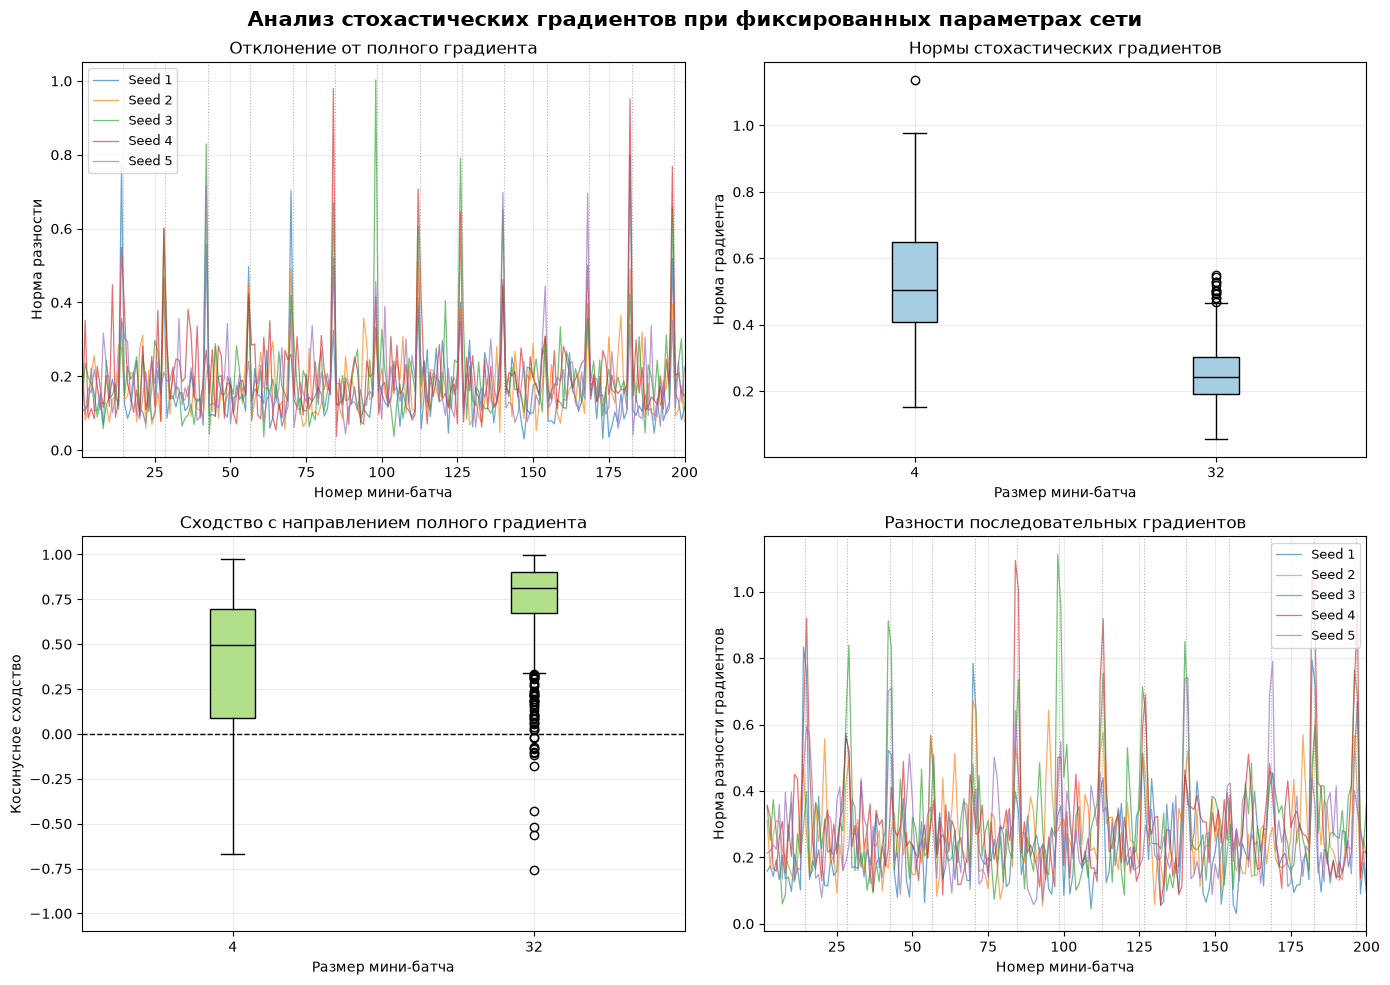


Количество контрольных проверок: 20
Максимальная погрешность аналитического градиента: 0.00000000e+00
Максимальная погрешность центральных разностей: 1.63243585e-11
Максимальная ошибка агрегирования градиентов: 5.69210594e-17
Количество исследованных мини-батчей: 1000

Все проверки градиентов пройдены.
Параметры нейронных сетей не изменялись.
Контрольные вычисления не входят в бюджет обучения.


In [4]:
# =============================================
# Вычисление функции потерь
# =============================================

def evaluate_loss(theta, X_data, y_data):

    with torch.no_grad():

        return loss_value(
            theta,
            X_data,
            y_data
        ).item()


# =============================================
# Вычисление функции потерь и градиента
# =============================================

def evaluate_loss_gradient(theta, X_data, y_data):

    theta_variable = (
        theta.detach().clone().requires_grad_(True)
    )

    value = loss_value(
        theta_variable,
        X_data,
        y_data
    )

    gradient, = torch.autograd.grad(
        value,
        theta_variable
    )

    return value.item(), gradient.detach()


# =============================================
# Аналитическое вычисление градиента
# =============================================

def analytical_gradient(theta, X_data, y_data):

    with torch.no_grad():

        W1, b1, W2, b2 = unpack_parameters(theta)

        n_samples = len(X_data)

        # Прямой проход
        a = X_data @ W1.T + b1

        h = torch.tanh(a)

        logits = h @ W2.T + b2

        probabilities = torch.sigmoid(logits)

        # Производная BCE по логитам
        delta_output = (
            probabilities - y_data
        ) / n_samples

        # Градиенты выходного слоя
        grad_W2 = delta_output.T @ h

        grad_b2 = delta_output.sum(dim=0)

        # Производная Tanh
        activation_derivative = 1 - h ** 2

        # Обратное распространение ошибки
        delta_hidden = (
            delta_output @ W2
        ) * activation_derivative

        # Градиенты скрытого слоя
        grad_W1 = delta_hidden.T @ X_data

        grad_b1 = delta_hidden.sum(dim=0)

        # Объединение градиентов
        gradient = torch.cat([
            grad_W1.reshape(-1),
            grad_b1.reshape(-1),
            grad_W2.reshape(-1),
            grad_b2.reshape(-1)
        ])

    return gradient


# =============================================
# Численный градиент центральными разностями
# =============================================

def numerical_gradient(
    theta,
    X_data,
    y_data,
    step=1e-5
):

    gradient = torch.zeros_like(theta)

    for j in range(theta.numel()):

        direction = torch.zeros_like(theta)

        direction[j] = step

        loss_plus = evaluate_loss(
            theta + direction,
            X_data,
            y_data
        )

        loss_minus = evaluate_loss(
            theta - direction,
            X_data,
            y_data
        )

        gradient[j] = (
            loss_plus - loss_minus
        ) / (2 * step)

    return gradient


# =============================================
# Проверка градиентов для пяти инициализаций
# =============================================

gradient_check_records = []

for network_seed in network_seeds:

    theta = initial_parameters[network_seed]

    schedule = batch_schedules[network_seed]

    # Проверяем полный градиент,
    # обычный батч, неполный батч
    # и первый батч следующей эпохи
    control_samples = [
        (
            "Полная выборка",
            X_train,
            y_train
        ),

        (
            "Мини-батч 1",
            X_train[schedule[0]["indices"]],
            y_train[schedule[0]["indices"]]
        ),

        (
            "Мини-батч 14",
            X_train[schedule[13]["indices"]],
            y_train[schedule[13]["indices"]]
        ),

        (
            "Мини-батч 15",
            X_train[schedule[14]["indices"]],
            y_train[schedule[14]["indices"]]
        )
    ]

    for sample_name, X_control, y_control in control_samples:

        # Автоматическое дифференцирование
        value, gradient_auto = evaluate_loss_gradient(
            theta,
            X_control,
            y_control
        )

        # Аналитические производные
        gradient_analytic = analytical_gradient(
            theta,
            X_control,
            y_control
        )

        # Центральные разности
        gradient_numeric = numerical_gradient(
            theta,
            X_control,
            y_control
        )

        # Абсолютные погрешности
        analytic_error = torch.max(
            torch.abs(
                gradient_auto - gradient_analytic
            )
        ).item()

        numeric_error = torch.max(
            torch.abs(
                gradient_auto - gradient_numeric
            )
        ).item()

        # Относительная погрешность
        relative_error = (
            torch.linalg.vector_norm(
                gradient_auto - gradient_numeric
            ).item()

            / max(
                torch.linalg.vector_norm(
                    gradient_auto
                ).item(),
                1e-15
            )
        )

        # Проверка размерности и точности
        assert gradient_auto.shape == (41,)

        assert gradient_auto.dtype == torch.float64

        assert torch.isfinite(gradient_auto).all()

        assert np.isfinite(value)

        # Сравнение аналитического градиента
        # с автоматическим дифференцированием
        assert torch.allclose(
            gradient_auto,
            gradient_analytic,
            atol=1e-12,
            rtol=1e-10
        )

        # Сравнение с центральными разностями
        assert torch.allclose(
            gradient_auto,
            gradient_numeric,
            atol=1e-8,
            rtol=1e-6
        )

        gradient_check_records.append({
            "Seed": network_seed,

            "Выборка": sample_name,

            "Наблюдений": len(X_control),

            "Loss": value,

            "Норма градиента": (
                torch.linalg.vector_norm(
                    gradient_auto
                ).item()
            ),

            "Погрешность аналитического градиента": (
                analytic_error
            ),

            "Погрешность центральных разностей": (
                numeric_error
            ),

            "Относительная погрешность": (
                relative_error
            )
        })


gradient_check_df = pd.DataFrame(
    gradient_check_records
)

print("Проверка полного и стохастических градиентов:")

display(
    gradient_check_df.style
    .hide(axis="index")
    .format({
        "Loss": "{:.8f}",
        "Норма градиента": "{:.8e}",
        "Погрешность аналитического градиента": "{:.6e}",
        "Погрешность центральных разностей": "{:.6e}",
        "Относительная погрешность": "{:.6e}"
    })
)


# =============================================
# Проверка связи полного градиента
# с градиентами мини-батчей
# =============================================

aggregation_records = []

for network_seed in network_seeds:

    theta = initial_parameters[network_seed]

    schedule = batch_schedules[network_seed]

    full_loss, full_gradient = evaluate_loss_gradient(
        theta,
        X_train,
        y_train
    )

    # Взвешенное накопление
    weighted_loss = 0.0

    weighted_gradient = torch.zeros_like(theta)

    # Невзвешенное накопление для сравнения
    unweighted_loss = 0.0

    unweighted_gradient = torch.zeros_like(theta)

    epoch_batches = [
        record
        for record in schedule
        if record["epoch"] == 1
    ]

    for record in epoch_batches:

        idx = record["indices"]

        batch_loss, batch_gradient = (
            evaluate_loss_gradient(
                theta,
                X_train[idx],
                y_train[idx]
            )
        )

        # Учитываем фактический размер батча
        weight = len(idx) / n_train

        weighted_loss += weight * batch_loss

        weighted_gradient += (
            weight * batch_gradient
        )

        unweighted_loss += batch_loss

        unweighted_gradient += batch_gradient

    # Простое среднее по батчам
    unweighted_loss /= len(epoch_batches)

    unweighted_gradient /= len(epoch_batches)

    weighted_loss_error = abs(
        weighted_loss - full_loss
    )

    weighted_gradient_error = (
        torch.linalg.vector_norm(
            weighted_gradient - full_gradient
        ).item()
    )

    unweighted_loss_error = abs(
        unweighted_loss - full_loss
    )

    unweighted_gradient_error = (
        torch.linalg.vector_norm(
            unweighted_gradient - full_gradient
        ).item()
    )

    # Взвешенное агрегирование должно совпадать
    # с вычислением по полной выборке
    assert np.isclose(
        weighted_loss,
        full_loss,
        atol=1e-12,
        rtol=1e-10
    )

    assert torch.allclose(
        weighted_gradient,
        full_gradient,
        atol=1e-12,
        rtol=1e-10
    )

    aggregation_records.append({
        "Seed": network_seed,

        "Полный train loss": full_loss,

        "Взвешенный batch loss": weighted_loss,

        "Ошибка взвешенных потерь": (
            weighted_loss_error
        ),

        "Ошибка взвешенного градиента": (
            weighted_gradient_error
        ),

        "Ошибка невзвешенных потерь": (
            unweighted_loss_error
        ),

        "Ошибка невзвешенного градиента": (
            unweighted_gradient_error
        )
    })


aggregation_df = pd.DataFrame(
    aggregation_records
)

print("\nПроверка агрегирования градиентов мини-батчей:")

display(
    aggregation_df.style
    .hide(axis="index")
    .format({
        "Полный train loss": "{:.10f}",
        "Взвешенный batch loss": "{:.10f}",
        "Ошибка взвешенных потерь": "{:.8e}",
        "Ошибка взвешенного градиента": "{:.8e}",
        "Ошибка невзвешенных потерь": "{:.8e}",
        "Ошибка невзвешенного градиента": "{:.8e}"
    })
)


# =============================================
# Анализ стохастических градиентов
# при фиксированных параметрах
# =============================================

stochastic_gradient_records = []

for network_seed in network_seeds:

    theta = initial_parameters[network_seed]

    _, full_gradient = evaluate_loss_gradient(
        theta,
        X_train,
        y_train
    )

    previous_gradient = None

    for record in batch_schedules[network_seed]:

        idx = record["indices"]

        value, batch_gradient = (
            evaluate_loss_gradient(
                theta,
                X_train[idx],
                y_train[idx]
            )
        )

        gradient_error = (
            batch_gradient - full_gradient
        )

        full_gradient_norm = (
            torch.linalg.vector_norm(
                full_gradient
            ).item()
        )

        batch_gradient_norm = (
            torch.linalg.vector_norm(
                batch_gradient
            ).item()
        )

        gradient_error_norm = (
            torch.linalg.vector_norm(
                gradient_error
            ).item()
        )

        cosine_similarity = (
            F.cosine_similarity(
                batch_gradient,
                full_gradient,
                dim=0,
                eps=1e-15
            ).item()
        )

        # Разность градиентов при неизменных параметрах
        if previous_gradient is None:

            gradient_difference_norm = np.nan

        else:

            gradient_difference_norm = (
                torch.linalg.vector_norm(
                    batch_gradient - previous_gradient
                ).item()
            )

        stochastic_gradient_records.append({
            "seed": network_seed,

            "step": record["step"],

            "epoch": record["epoch"],

            "batch_size": len(idx),

            "batch_loss": value,

            "full_gradient_norm": full_gradient_norm,

            "batch_gradient_norm": batch_gradient_norm,

            "gradient_error_norm": gradient_error_norm,

            "cosine_similarity": cosine_similarity,

            "gradient_difference_norm": (
                gradient_difference_norm
            )
        })

        previous_gradient = batch_gradient.clone()


stochastic_gradient_df = pd.DataFrame(
    stochastic_gradient_records
)

assert len(stochastic_gradient_df) == (
    n_repeats * iterations
)

# =============================================
# Сравнение полных и неполных мини-батчей
# =============================================

gradient_batch_stats = (
    stochastic_gradient_df
    .groupby("batch_size")
    .agg(
        batches=("step", "count"),

        gradient_norm_mean=(
            "batch_gradient_norm", "mean"
        ),

        gradient_norm_std=(
            "batch_gradient_norm", "std"
        ),

        gradient_error_mean=(
            "gradient_error_norm", "mean"
        ),

        gradient_error_std=(
            "gradient_error_norm", "std"
        ),

        cosine_similarity_mean=(
            "cosine_similarity", "mean"
        ),

        gradient_difference_mean=(
            "gradient_difference_norm", "mean"
        )
    )
    .reset_index()
)

print("\nХарактеристики стохастических градиентов")
print("при фиксированных начальных параметрах:")

display(
    gradient_batch_stats
    .rename(columns={
        "batch_size": "Размер батча",
        "batches": "Количество батчей",

        "gradient_norm_mean":
            "Средняя норма градиента",

        "gradient_norm_std":
            "Стандартное отклонение нормы",

        "gradient_error_mean":
            "Среднее отклонение от полного градиента",

        "gradient_error_std":
            "Стандартное отклонение ошибки",

        "cosine_similarity_mean":
            "Среднее косинусное сходство",

        "gradient_difference_mean":
            "Средняя норма разности градиентов"
    })
    .style
    .hide(axis="index")
    .format(precision=8)
)


# =============================================
# Визуализация стохастичности градиентов
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

# Отклонение стохастического градиента
# от полного градиента
for network_seed in network_seeds:

    subset = stochastic_gradient_df[
        stochastic_gradient_df["seed"] == network_seed
    ]

    axes[0, 0].plot(
        subset["step"],
        subset["gradient_error_norm"],
        linewidth=0.9,
        alpha=0.65,
        label=f"Seed {network_seed}"
    )

axes[0, 0].set_title(
    "Отклонение от полного градиента"
)

axes[0, 0].set_xlabel("Номер мини-батча")

axes[0, 0].set_ylabel("Норма разности")

axes[0, 0].legend(fontsize=9)


# Норма стохастического градиента
# для разных размеров мини-батча
batch_sizes_control = [4, 32]

axes[0, 1].boxplot(
    [
        stochastic_gradient_df.loc[
            stochastic_gradient_df["batch_size"] == size,
            "batch_gradient_norm"
        ].to_numpy()

        for size in batch_sizes_control
    ],
    tick_labels=["4", "32"],
    patch_artist=True,
    boxprops={"facecolor": "#a6cee3"},
    medianprops={"color": "black"}
)

axes[0, 1].set_title(
    "Нормы стохастических градиентов"
)

axes[0, 1].set_xlabel("Размер мини-батча")

axes[0, 1].set_ylabel("Норма градиента")


# Косинусное сходство с полным градиентом
axes[1, 0].boxplot(
    [
        stochastic_gradient_df.loc[
            stochastic_gradient_df["batch_size"] == size,
            "cosine_similarity"
        ].to_numpy()

        for size in batch_sizes_control
    ],
    tick_labels=["4", "32"],
    patch_artist=True,
    boxprops={"facecolor": "#b2df8a"},
    medianprops={"color": "black"}
)

axes[1, 0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1, 0].set_title(
    "Сходство с направлением полного градиента"
)

axes[1, 0].set_xlabel("Размер мини-батча")

axes[1, 0].set_ylabel("Косинусное сходство")

axes[1, 0].set_ylim(-1.1, 1.1)


# Разности последовательных градиентов
# при неизменных параметрах сети
for network_seed in network_seeds:

    subset = stochastic_gradient_df[
        stochastic_gradient_df["seed"] == network_seed
    ]

    axes[1, 1].plot(
        subset["step"],
        subset["gradient_difference_norm"],
        linewidth=0.9,
        alpha=0.65,
        label=f"Seed {network_seed}"
    )

axes[1, 1].set_title(
    "Разности последовательных градиентов"
)

axes[1, 1].set_xlabel("Номер мини-батча")

axes[1, 1].set_ylabel("Норма разности градиентов")

axes[1, 1].legend(fontsize=9)


# Границы эпох
for ax in [axes[0, 0], axes[1, 1]]:

    for epoch in range(1, completed_epochs + 1):

        ax.axvline(
            epoch * batches_per_epoch + 0.5,
            color="gray",
            linestyle=":",
            linewidth=0.8,
            alpha=0.6
        )

    ax.set_xlim(1, iterations)

for ax in axes.flat:

    ax.grid(alpha=0.25)

fig.suptitle(
    "Анализ стохастических градиентов "
    "при фиксированных параметрах сети",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Итоговые результаты проверок
# =============================================

print("\nКоличество контрольных проверок:",
      len(gradient_check_df))

print(
    "Максимальная погрешность аналитического градиента:",
    f"{gradient_check_df['Погрешность аналитического градиента'].max():.8e}"
)

print(
    "Максимальная погрешность центральных разностей:",
    f"{gradient_check_df['Погрешность центральных разностей'].max():.8e}"
)

print(
    "Максимальная ошибка агрегирования градиентов:",
    f"{aggregation_df['Ошибка взвешенного градиента'].max():.8e}"
)

print(
    "Количество исследованных мини-батчей:",
    len(stochastic_gradient_df)
)

print("\nВсе проверки градиентов пройдены.")

print("Параметры нейронных сетей не изменялись.")

print("Контрольные вычисления не входят в бюджет обучения.")

In [5]:
# =============================================
# Инициализация состояний оптимизаторов
# =============================================

def initialize_optimizer_state(method, theta):

    if method == "AdamW":

        return {
            "m": torch.zeros_like(theta),
            "v": torch.zeros_like(theta),
            "step": 0
        }

    if method == "Adan":

        return {
            "m": torch.zeros_like(theta),
            "v": torch.zeros_like(theta),
            "n": torch.zeros_like(theta),
            "prev_grad": torch.zeros_like(theta),
            "step": 0
        }

    raise ValueError(f"Неизвестный метод: {method}")


# =============================================
# Самостоятельная реализация AdamW
# =============================================

@torch.no_grad()
def adamw_step(
    theta,
    gradient,
    state,
    settings,
    collect_diagnostics=True
):

    eta = settings["eta"]

    beta1 = settings["beta1"]
    beta2 = settings["beta2"]

    eps = settings["eps"]
    weight_decay = settings["weight_decay"]

    t = state["step"] + 1

    # Первый момент
    m = (
        beta1 * state["m"]
        + (1 - beta1) * gradient
    )

    # Второй момент
    v = (
        beta2 * state["v"]
        + (1 - beta2) * gradient.square()
    )

    # Коррекция смещения
    m_hat = m / (1 - beta1 ** t)

    v_hat = v / (1 - beta2 ** t)

    # Адаптивный знаменатель
    denominator = torch.sqrt(v_hat) + eps

    effective_lr = eta / denominator

    # Обновление параметров
    adaptive_update = effective_lr * m_hat

    theta_new = (
        (1 - eta * weight_decay) * theta
        - adaptive_update
    )

    new_state = {
        "m": m,
        "v": v,
        "step": t
    }

    diagnostics = {}

    if collect_diagnostics:

        diagnostics = {
            "m_norm": torch.linalg.vector_norm(m).item(),

            "second_moment_norm": (
                torch.linalg.vector_norm(v).item()
            ),

            "effective_lr_mean": effective_lr.mean().item(),

            "effective_lr_min": effective_lr.min().item(),

            "effective_lr_max": effective_lr.max().item(),

            "adaptive_update_norm": (
                torch.linalg.vector_norm(
                    adaptive_update
                ).item()
            ),

            "gradient_difference_norm": np.nan,

            "difference_moment_norm": np.nan,

            "nesterov_correction_norm": np.nan,

            "gradient_difference_calls": 0
        }

    return theta_new, new_state, diagnostics


# =============================================
# Самостоятельная реализация Adan
# =============================================

@torch.no_grad()
def adan_step(
    theta,
    gradient,
    state,
    settings,
    collect_diagnostics=True
):

    eta = settings["eta"]

    beta1 = settings["beta1"]
    beta2 = settings["beta2"]
    beta3 = settings["beta3"]

    eps = settings["eps"]
    weight_decay = settings["weight_decay"]

    t = state["step"] + 1

    # В исследуемой конфигурации не используются
    # перезапуски и ограничение нормы градиента
    if settings["restart"]:

        raise ValueError(
            "Restart strategy отключена "
            "в данной экспериментальной конфигурации."
        )

    if settings["max_grad_norm"] != 0:

        raise ValueError(
            "Gradient clipping не используется."
        )

    # =========================================
    # 1. Разность последовательных градиентов
    # =========================================

    if t == 1:

        # Первый градиент принимается
        # за предыдущий: g0 = g1
        delta_g = torch.zeros_like(gradient)

        difference_calls = 0

    else:

        delta_g = (
            gradient - state["prev_grad"]
        )

        difference_calls = 1

    # =========================================
    # 2. Первый момент градиента
    # =========================================

    m = (
        beta1 * state["m"]
        + (1 - beta1) * gradient
    )

    # =========================================
    # 3. Первый момент разности градиентов
    # =========================================

    v = (
        beta2 * state["v"]
        + (1 - beta2) * delta_g
    )

    # =========================================
    # 4. Скорректированный градиент
    # =========================================

    q = gradient + beta2 * delta_g

    # =========================================
    # 5. Второй момент скорректированного
    #    градиента
    # =========================================

    n = (
        beta3 * state["n"]
        + (1 - beta3) * q.square()
    )

    # =========================================
    # 6. Коррекция смещения трёх моментов
    # =========================================

    m_hat = m / (1 - beta1 ** t)

    v_hat = v / (1 - beta2 ** t)

    n_hat = n / (1 - beta3 ** t)

    # =========================================
    # 7. Nesterov Momentum Estimation
    # =========================================

    nesterov_correction = beta2 * v_hat

    numerator = (
        m_hat + nesterov_correction
    )

    denominator = (
        torch.sqrt(n_hat) + eps
    )

    effective_lr = eta / denominator

    adaptive_update = (
        effective_lr * numerator
    )

    # =========================================
    # 8. Обновление параметров
    # =========================================

    if settings["no_prox"]:

        # Альтернативная отделённая форма
        # weight decay из авторской реализации
        theta_new = (
            (1 - eta * weight_decay) * theta
            - adaptive_update
        )

    else:

        # Проксимальная форма Adan
        theta_new = (
            theta - adaptive_update
        ) / (1 + eta * weight_decay)

    # =========================================
    # 9. Сохранение внутреннего состояния
    # =========================================

    new_state = {
        "m": m,
        "v": v,
        "n": n,
        "prev_grad": gradient.detach().clone(),
        "step": t
    }

    diagnostics = {}

    if collect_diagnostics:

        diagnostics = {
            "m_norm": (
                torch.linalg.vector_norm(m).item()
            ),

            "second_moment_norm": (
                torch.linalg.vector_norm(n).item()
            ),

            "gradient_difference_norm": (
                torch.linalg.vector_norm(
                    delta_g
                ).item()
            ),

            "difference_moment_norm": (
                torch.linalg.vector_norm(v).item()
            ),

            "corrected_gradient_norm": (
                torch.linalg.vector_norm(q).item()
            ),

            "nesterov_correction_norm": (
                torch.linalg.vector_norm(
                    nesterov_correction
                ).item()
            ),

            "numerator_norm": (
                torch.linalg.vector_norm(
                    numerator
                ).item()
            ),

            "effective_lr_mean": (
                effective_lr.mean().item()
            ),

            "effective_lr_min": (
                effective_lr.min().item()
            ),

            "effective_lr_max": (
                effective_lr.max().item()
            ),

            "adaptive_update_norm": (
                torch.linalg.vector_norm(
                    adaptive_update
                ).item()
            ),

            "gradient_difference_calls": (
                difference_calls
            )
        }

    return theta_new, new_state, diagnostics


# =============================================
# Единый интерфейс оптимизаторов
# =============================================

def optimizer_step(
    method,
    theta,
    gradient,
    state,
    settings,
    collect_diagnostics=True
):

    if method == "AdamW":

        return adamw_step(
            theta,
            gradient,
            state,
            settings,
            collect_diagnostics
        )

    if method == "Adan":

        return adan_step(
            theta,
            gradient,
            state,
            settings,
            collect_diagnostics
        )

    raise ValueError(f"Неизвестный метод: {method}")


# =============================================
# Проверка численной корректности состояния
# =============================================

def is_finite_state(state):

    return all(
        torch.isfinite(value).all().item()

        for value in state.values()

        if isinstance(value, torch.Tensor)
    )


# =============================================
# Копирование состояния оптимизатора
# =============================================

def copy_optimizer_state(state):

    return {
        key: (
            value.detach().clone()

            if isinstance(value, torch.Tensor)

            else value
        )

        for key, value in state.items()
    }


# =============================================
# Размер постоянного числового состояния
# =============================================

def optimizer_state_bytes(state):

    return sum(
        value.numel() * value.element_size()

        for value in state.values()

        if isinstance(value, torch.Tensor)
    )


# =============================================
# Контрольная реализация моментов Adan
# через явные взвешенные суммы
# =============================================

def adan_reference_moments(
    gradient_history,
    settings
):

    gradients = np.stack([
        gradient.detach().cpu().numpy()

        for gradient in gradient_history
    ])

    t = len(gradients)

    beta1 = settings["beta1"]
    beta2 = settings["beta2"]
    beta3 = settings["beta3"]

    # Разности последовательных градиентов
    differences = np.zeros_like(gradients)

    differences[1:] = (
        gradients[1:] - gradients[:-1]
    )

    corrected_gradients = (
        gradients + beta2 * differences
    )

    # Степени коэффициентов усреднения
    powers = np.arange(t - 1, -1, -1)

    weights_m = (
        (1 - beta1) * beta1 ** powers
    )

    weights_v = (
        (1 - beta2) * beta2 ** powers
    )

    weights_n = (
        (1 - beta3) * beta3 ** powers
    )

    # Накопленные моменты без рекурсии
    m = np.sum(
        weights_m[:, None] * gradients,
        axis=0
    )

    v = np.sum(
        weights_v[:, None] * differences,
        axis=0
    )

    n = np.sum(
        weights_n[:, None]
        * corrected_gradients ** 2,
        axis=0
    )

    return m, v, n


# =============================================
# Контрольная проверка AdamW относительно
# библиотечной реализации PyTorch
# =============================================

control_iterations = 30

adamw_control_records = []

for network_seed in network_seeds:

    theta = initial_parameters[
        network_seed
    ].clone()

    state = initialize_optimizer_state(
        "AdamW",
        theta
    )

    settings = config["AdamW"]

    reference_theta = nn.Parameter(
        theta.clone()
    )

    reference_optimizer = torch.optim.AdamW(
        [reference_theta],
        lr=settings["eta"],
        betas=(
            settings["beta1"],
            settings["beta2"]
        ),
        eps=settings["eps"],
        weight_decay=settings["weight_decay"],
        amsgrad=False,
        foreach=False,
        fused=False
    )

    parameter_errors = []

    state_errors = []

    for record in batch_schedules[
        network_seed
    ][:control_iterations]:

        idx = record["indices"]

        # Одинаковый входной градиент
        # для двух реализаций
        _, gradient = evaluate_loss_gradient(
            theta,
            X_train[idx],
            y_train[idx]
        )

        theta, state, diagnostics = adamw_step(
            theta,
            gradient,
            state,
            settings
        )

        reference_optimizer.zero_grad(
            set_to_none=True
        )

        reference_theta.grad = gradient.clone()

        reference_optimizer.step()

        reference_state = reference_optimizer.state[
            reference_theta
        ]

        parameter_error = torch.max(
            torch.abs(
                theta - reference_theta.detach()
            )
        ).item()

        parameter_errors.append(
            parameter_error
        )

        assert torch.allclose(
            theta,
            reference_theta.detach(),
            atol=1e-12,
            rtol=1e-10
        )

        for own_state, ref_state in [
            (
                state["m"],
                reference_state["exp_avg"]
            ),
            (
                state["v"],
                reference_state["exp_avg_sq"]
            )
        ]:

            state_error = torch.max(
                torch.abs(own_state - ref_state)
            ).item()

            state_errors.append(state_error)

            assert torch.allclose(
                own_state,
                ref_state,
                atol=1e-12,
                rtol=1e-10
            )

        assert state["step"] == record["step"]

        assert is_finite_state(state)

        assert torch.all(state["v"] >= 0)

    adamw_control_records.append({
        "Seed": network_seed,

        "Контрольные шаги": control_iterations,

        "Максимальная ошибка параметров": (
            max(parameter_errors)
        ),

        "Максимальная ошибка моментов": (
            max(state_errors)
        ),

        "Результат": "Пройдено"
    })


adamw_control_df = pd.DataFrame(
    adamw_control_records
)

print("Проверка AdamW относительно PyTorch:")

display(
    adamw_control_df.style
    .hide(axis="index")
    .format({
        "Максимальная ошибка параметров": "{:.8e}",
        "Максимальная ошибка моментов": "{:.8e}"
    })
)


# =============================================
# Контрольная проверка Adan
# =============================================

adan_control_records = []

for network_seed in network_seeds:

    theta = initial_parameters[
        network_seed
    ].clone()

    reference_theta = (
        theta.detach().cpu().numpy().copy()
    )

    settings = config["Adan"]

    state = initialize_optimizer_state(
        "Adan",
        theta
    )

    gradient_history = []

    parameter_errors = []

    m_errors = []
    v_errors = []
    n_errors = []

    for record in batch_schedules[
        network_seed
    ][:control_iterations]:

        idx = record["indices"]

        _, gradient = evaluate_loss_gradient(
            theta,
            X_train[idx],
            y_train[idx]
        )

        gradient_history.append(
            gradient.clone()
        )

        # Исследуемая рекуррентная реализация
        theta, state, diagnostics = adan_step(
            theta,
            gradient,
            state,
            settings
        )

        # Независимое вычисление моментов
        # через всю последовательность градиентов
        m_ref, v_ref, n_ref = adan_reference_moments(
            gradient_history,
            settings
        )

        t = len(gradient_history)

        beta1 = settings["beta1"]
        beta2 = settings["beta2"]
        beta3 = settings["beta3"]

        eta = settings["eta"]
        eps = settings["eps"]

        # Коррекция смещения эталонных моментов
        m_hat_ref = m_ref / (1 - beta1 ** t)

        v_hat_ref = v_ref / (1 - beta2 ** t)

        n_hat_ref = n_ref / (1 - beta3 ** t)

        # Независимое обновление параметров NumPy
        denominator = np.sqrt(n_hat_ref) + eps

        reference_theta = (
            reference_theta
            - eta * (
                m_hat_ref + beta2 * v_hat_ref
            ) / denominator
        ) / (
            1 + eta * settings["weight_decay"]
        )

        # Сравнение параметров
        parameter_error = np.max(
            np.abs(
                theta.detach().cpu().numpy()
                - reference_theta
            )
        )

        parameter_errors.append(parameter_error)

        assert np.allclose(
            theta.detach().cpu().numpy(),
            reference_theta,
            atol=1e-12,
            rtol=1e-10
        )

        # Сравнение трёх накопленных моментов
        for key, reference_value, errors in [
            ("m", m_ref, m_errors),
            ("v", v_ref, v_errors),
            ("n", n_ref, n_errors)
        ]:

            own_value = (
                state[key].detach().cpu().numpy()
            )

            error = np.max(
                np.abs(
                    own_value - reference_value
                )
            )

            errors.append(error)

            assert np.allclose(
                own_value,
                reference_value,
                atol=1e-12,
                rtol=1e-10
            )

        # Проверка сохранения предыдущего градиента
        assert torch.equal(
            state["prev_grad"],
            gradient
        )

        assert state["step"] == t

        assert is_finite_state(state)

        assert torch.all(state["n"] >= 0)

        # Первый момент разности должен быть нулевым
        # на первой итерации
        if t == 1:

            assert torch.all(
                state["v"] == 0
            )

            assert (
                diagnostics["gradient_difference_norm"]
                == 0
            )

            assert (
                diagnostics["gradient_difference_calls"]
                == 0
            )

        else:

            assert (
                diagnostics["gradient_difference_calls"]
                == 1
            )

    adan_control_records.append({
        "Seed": network_seed,

        "Контрольные шаги": control_iterations,

        "Ошибка параметров": max(parameter_errors),

        "Ошибка момента m": max(m_errors),

        "Ошибка момента v": max(v_errors),

        "Ошибка момента n": max(n_errors),

        "Результат": "Пройдено"
    })


adan_control_df = pd.DataFrame(
    adan_control_records
)

print("\nПроверка Adan через явные взвешенные суммы:")

display(
    adan_control_df.style
    .hide(axis="index")
    .format({
        "Ошибка параметров": "{:.8e}",
        "Ошибка момента m": "{:.8e}",
        "Ошибка момента v": "{:.8e}",
        "Ошибка момента n": "{:.8e}"
    })
)


# =============================================
# Проверка совпадения первого шага
# AdamW и Adan
# =============================================

first_step_records = []

for network_seed in network_seeds:

    theta = initial_parameters[
        network_seed
    ].clone()

    idx = batch_schedules[
        network_seed
    ][0]["indices"]

    _, gradient = evaluate_loss_gradient(
        theta,
        X_train[idx],
        y_train[idx]
    )

    adamw_state = initialize_optimizer_state(
        "AdamW",
        theta
    )

    adan_state = initialize_optimizer_state(
        "Adan",
        theta
    )

    theta_adamw, _, _ = adamw_step(
        theta,
        gradient,
        adamw_state,
        config["AdamW"]
    )

    theta_adan, _, adan_diagnostics = adan_step(
        theta,
        gradient,
        adan_state,
        config["Adan"]
    )

    # Теоретическое правило первого шага
    theta_reference = (
        theta
        - config["AdamW"]["eta"]
        * gradient
        / (
            torch.abs(gradient)
            + config["AdamW"]["eps"]
        )
    )

    difference = torch.max(
        torch.abs(
            theta_adamw - theta_adan
        )
    ).item()

    assert torch.allclose(
        theta_adamw,
        theta_adan,
        atol=1e-12,
        rtol=1e-10
    )

    assert torch.allclose(
        theta_adamw,
        theta_reference,
        atol=1e-12,
        rtol=1e-10
    )

    assert torch.allclose(
        theta_adan,
        theta_reference,
        atol=1e-12,
        rtol=1e-10
    )

    first_step_records.append({
        "Seed": network_seed,

        "Норма первого градиента": (
            torch.linalg.vector_norm(
                gradient
            ).item()
        ),

        "Разность градиентов Adan": (
            adan_diagnostics[
                "gradient_difference_norm"
            ]
        ),

        "Коррекция Нестерова": (
            adan_diagnostics[
                "nesterov_correction_norm"
            ]
        ),

        "Норма обновления AdamW": (
            torch.linalg.vector_norm(
                theta_adamw - theta
            ).item()
        ),

        "Норма обновления Adan": (
            torch.linalg.vector_norm(
                theta_adan - theta
            ).item()
        ),

        "Максимальная разность параметров": (
            difference
        )
    })


first_step_df = pd.DataFrame(
    first_step_records
)

print("\nПроверка совпадения первого шага:")

display(
    first_step_df.style
    .hide(axis="index")
    .format({
        column: "{:.8e}"

        for column in first_step_df.columns

        if column != "Seed"
    })
)


# =============================================
# Проверка сохранения исходных параметров
# =============================================

for network_seed in network_seeds:

    assert torch.equal(
        initial_parameters[network_seed],
        get_parameters(
            initialize_network(network_seed)
        )
    )


# =============================================
# Анализ постоянного числового состояния
# =============================================

state_memory_records = []

for method in methods:

    state = initialize_optimizer_state(
        method,
        initial_parameters[1]
    )

    tensor_count = sum(
        isinstance(value, torch.Tensor)
        for value in state.values()
    )

    element_count = sum(
        value.numel()

        for value in state.values()

        if isinstance(value, torch.Tensor)
    )

    state_bytes = optimizer_state_bytes(
        state
    )

    state_memory_records.append({
        "Метод": method,

        "Векторов состояния": tensor_count,

        "Числовых элементов": element_count,

        "Память состояния, байт": state_bytes
    })


state_memory_df = pd.DataFrame(
    state_memory_records
)

assert optimizer_state_bytes(
    initialize_optimizer_state(
        "AdamW",
        initial_parameters[1]
    )
) == 656

assert optimizer_state_bytes(
    initialize_optimizer_state(
        "Adan",
        initial_parameters[1]
    )
) == 1312

print("\nПостоянное числовое состояние:")

display(
    state_memory_df.style.hide(axis="index")
)

print("\nВсе контрольные проверки AdamW пройдены.")

print("Все контрольные проверки Adan пройдены.")

print("Первый шаг двух методов совпадает.")

print("Начальные параметры сети не изменялись.")

print("Контрольные вычисления не входят в основной эксперимент.")

print("Оба оптимизатора реализованы.")

Проверка AdamW относительно PyTorch:


Seed,Контрольные шаги,Максимальная ошибка параметров,Максимальная ошибка моментов,Результат
1,30,5.55111512e-17,1.38777878e-17,Пройдено
2,30,1.11022302e-16,1.38777878e-17,Пройдено
3,30,1.11022302e-16,1.38777878e-17,Пройдено
4,30,1.11022302e-16,2.08166817e-17,Пройдено
5,30,1.11022302e-16,1.38777878e-17,Пройдено



Проверка Adan через явные взвешенные суммы:


Seed,Контрольные шаги,Ошибка параметров,Ошибка момента m,Ошибка момента v,Ошибка момента n,Результат
1,30,1.11022302e-16,1.38777878e-17,7.37257477e-18,6.93889390e-18,Пройдено
2,30,1.11022302e-16,1.38777878e-17,6.07153217e-18,1.73472348e-18,Пройдено
3,30,5.55111512e-17,2.08166817e-17,5.20417043e-18,1.73472348e-18,Пройдено
4,30,1.11022302e-16,2.77555756e-17,8.67361738e-18,6.93889390e-18,Пройдено
5,30,5.55111512e-17,2.08166817e-17,8.67361738e-18,3.46944695e-18,Пройдено



Проверка совпадения первого шага:


Seed,Норма первого градиента,Разность градиентов Adan,Коррекция Нестерова,Норма обновления AdamW,Норма обновления Adan,Максимальная разность параметров
1,2.36149312e-01,0.00000000e+00,0.00000000e+00,3.20152998e-02,3.20152998e-02,0.00000000e+00
2,2.96485877e-01,0.00000000e+00,0.00000000e+00,3.20154426e-02,3.20154426e-02,0.00000000e+00
3,2.32048035e-01,0.00000000e+00,0.00000000e+00,3.20154831e-02,3.20154831e-02,0.00000000e+00
4,2.89988598e-01,0.00000000e+00,0.00000000e+00,3.20155693e-02,3.20155693e-02,0.00000000e+00
5,2.33353902e-01,0.00000000e+00,0.00000000e+00,3.20143522e-02,3.20143522e-02,0.00000000e+00



Постоянное числовое состояние:


Метод,Векторов состояния,Числовых элементов,"Память состояния, байт"
AdamW,2,82,656
Adan,4,164,1312



Все контрольные проверки AdamW пройдены.
Все контрольные проверки Adan пройдены.
Первый шаг двух методов совпадает.
Начальные параметры сети не изменялись.
Контрольные вычисления не входят в основной эксперимент.
Оба оптимизатора реализованы.


In [6]:
# =============================================
# Счётчики вычислительных затрат
# =============================================

def initialize_counters():

    return {
        "batch_loss_calls": 0,
        "batch_gradient_calls": 0,

        "full_train_loss_calls": 0,
        "full_gradient_calls": 0,

        "validation_loss_calls": 0,

        "processed_samples": 0,
        "diagnostic_train_samples": 0,
        "diagnostic_validation_samples": 0,

        "optimizer_step_calls": 0,
        "gradient_difference_calls": 0,

        "hessian_calls": 0,
        "jacobian_calls": 0,
        "curvature_builds": 0,
        "factorizations": 0,
        "linear_system_solves": 0
    }


# =============================================
# Стохастический градиент для оптимизации
# =============================================

def counted_batch_gradient(theta, idx, counters):

    X_batch = X_train[idx]

    y_batch = y_train[idx]

    value, gradient = evaluate_loss_gradient(
        theta,
        X_batch,
        y_batch
    )

    counters["batch_loss_calls"] += 1

    counters["batch_gradient_calls"] += 1

    counters["processed_samples"] += len(idx)

    return value, gradient


# =============================================
# Диагностические вычисления
# =============================================

def evaluate_diagnostics(theta, counters):

    train_loss, full_gradient = evaluate_loss_gradient(
        theta,
        X_train,
        y_train
    )

    counters["full_train_loss_calls"] += 1

    counters["full_gradient_calls"] += 1

    counters["diagnostic_train_samples"] += len(X_train)

    validation_loss = evaluate_loss(
        theta,
        X_val,
        y_val
    )

    counters["validation_loss_calls"] += 1

    counters["diagnostic_validation_samples"] += len(X_val)

    return {
        "train_loss": train_loss,

        "validation_loss": validation_loss,

        "full_gradient": full_gradient,

        "gradient_norm": (
            torch.linalg.vector_norm(
                full_gradient
            ).item()
        )
    }


# =============================================
# Проверка численной корректности диагностики
# =============================================

def finite_diagnostics(diagnostics):

    return bool(
        np.isfinite(diagnostics["train_loss"])

        and np.isfinite(diagnostics["validation_loss"])

        and torch.isfinite(
            diagnostics["full_gradient"]
        ).all().item()
    )


# =============================================
# Формирование записи истории
# =============================================

def make_history_record(
    method,
    network_seed,
    step,
    theta,
    state,
    diagnostics,
    counters
):

    record = {
        "method": method,

        "seed": network_seed,

        "iteration": step,

        "train_loss": diagnostics["train_loss"],

        "validation_loss": diagnostics["validation_loss"],

        "gradient_norm": diagnostics["gradient_norm"],

        "parameter_norm": (
            torch.linalg.vector_norm(theta).item()
        ),

        "theta": theta.detach().clone(),

        "full_gradient": (
            diagnostics["full_gradient"].detach().clone()
        ),

        "optimizer_state": copy_optimizer_state(state),

        "state_bytes": optimizer_state_bytes(state),

        "diagnostics_finite": finite_diagnostics(
            diagnostics
        ),

        **counters
    }

    # Каждый обратный проход сопровождается
    # вычислением функции потерь
    record["total_loss_calls"] = (
        counters["batch_loss_calls"]
        + counters["full_train_loss_calls"]
        + counters["validation_loss_calls"]
    )

    record["total_backward_calls"] = (
        counters["batch_gradient_calls"]
        + counters["full_gradient_calls"]
    )

    record["total_processed_samples"] = (
        counters["processed_samples"]

        + counters["diagnostic_train_samples"]

        + counters["diagnostic_validation_samples"]
    )

    return record


# =============================================
# Единая функция стохастической оптимизации
# =============================================

def optimize(
    method,
    network_seed,
    n_iterations=iterations,
    record_history=True,
    save_path=False
):

    assert 1 <= n_iterations <= iterations

    settings = config[method].copy()

    start_time = perf_counter()

    # =========================================
    # Инициализация
    # =========================================

    theta = initial_parameters[
        network_seed
    ].clone()

    theta_initial = theta.clone()

    state = initialize_optimizer_state(
        method,
        theta
    )

    counters = initialize_counters()

    schedule = batch_schedules[
        network_seed
    ][:n_iterations]

    core_time = perf_counter() - start_time

    iteration_history = []

    parameter_history = []

    accepted_history = []

    status_history = []

    core_time_history_ms = [
        core_time * 1000
    ]

    if save_path:

        parameter_history.append(
            theta.clone()
        )

    # =========================================
    # Диагностика начального состояния
    # =========================================

    current_diagnostics = None

    if record_history:

        current_diagnostics = evaluate_diagnostics(
            theta,
            counters
        )

        assert finite_diagnostics(
            current_diagnostics
        )

        initial_record = make_history_record(
            method,
            network_seed,
            0,
            theta,
            state,
            current_diagnostics,
            counters
        )

        initial_record.update({
            "epoch": 0,

            "batch_in_epoch": 0,

            "batch_size": 0,

            "batch_indices": None,

            "batch_loss": np.nan,

            "stochastic_gradient": None,

            "stochastic_gradient_norm": np.nan,

            "step_norm": 0.0,

            "accepted": None,

            "status": "Initial state",

            "candidate_theta": None,

            "candidate_optimizer_state": None,

            "candidate_train_loss": np.nan,

            "candidate_validation_loss": np.nan,

            "candidate_gradient_norm": np.nan,

            "gradient_difference_norm": np.nan,

            "nesterov_correction_norm": np.nan,

            "core_elapsed_time_ms": core_time * 1000
        })

        initial_record["elapsed_time_ms"] = (
            perf_counter() - start_time
        ) * 1000

        initial_record["iteration_time_ms"] = (
            initial_record["elapsed_time_ms"]
        )

        iteration_history.append(
            initial_record
        )

    # =========================================
    # Основной цикл обучения
    # =========================================

    for batch_record in schedule:

        iteration_start = perf_counter()

        step = batch_record["step"]

        idx = batch_record["indices"]

        theta_previous = theta

        # -------------------------------------
        # Основные вычисления оптимизации
        # -------------------------------------

        core_start = perf_counter()

        batch_loss, gradient = counted_batch_gradient(
            theta,
            idx,
            counters
        )

        candidate_theta = None

        candidate_state = None

        optimizer_diagnostics = {}

        accepted = False

        # Проверяем входной стохастический градиент
        finite_input = bool(
            np.isfinite(batch_loss)

            and torch.isfinite(
                gradient
            ).all().item()
        )

        if finite_input:

            counters["optimizer_step_calls"] += 1

            # Разность градиентов вычисляется
            # начиная со второго обновления Adan
            if method == "Adan" and state["step"] > 0:

                counters["gradient_difference_calls"] += 1

            (
                candidate_theta,
                candidate_state,
                optimizer_diagnostics
            ) = optimizer_step(
                method,
                theta,
                gradient,
                state,
                settings,
                collect_diagnostics=record_history
            )

            accepted = bool(
                torch.isfinite(
                    candidate_theta
                ).all().item()

                and is_finite_state(
                    candidate_state
                )
            )

            if accepted:

                theta = candidate_theta

                state = candidate_state

                status = "Accepted"

            else:

                status = "Non-finite candidate"

        else:

            status = "Non-finite batch loss or gradient"

        # При отклонении обновления параметры
        # и состояние оптимизатора не меняются.
        # Повторного использования батча
        # и автоматического перезапуска нет.

        core_time += (
            perf_counter() - core_start
        )

        core_time_history_ms.append(
            core_time * 1000
        )

        accepted_history.append(accepted)

        # -------------------------------------
        # Диагностика после попытки обновления
        # -------------------------------------

        if record_history:

            # При наличии пробного состояния
            # диагностируем именно его
            diagnostic_theta = (
                candidate_theta

                if candidate_theta is not None

                else theta
            )

            candidate_diagnostics = evaluate_diagnostics(
                diagnostic_theta,
                counters
            )

            candidate_diagnostics_finite = (
                finite_diagnostics(
                    candidate_diagnostics
                )
            )

            if accepted:

                current_diagnostics = (
                    candidate_diagnostics
                )

            # Диагностические показатели
            # не используются для принятия шага
            if not candidate_diagnostics_finite:

                status += "; Non-finite diagnostics"

            # Норма фактически выполненного обновления
            step_norm = torch.linalg.vector_norm(
                theta - theta_previous
            ).item()

            if not accepted:

                assert step_norm == 0.0

            # ---------------------------------
            # Сохранение истории
            # ---------------------------------

            record = make_history_record(
                method,
                network_seed,
                step,
                theta,
                state,
                current_diagnostics,
                counters
            )

            record.update({
                "epoch": batch_record["epoch"],

                "batch_in_epoch": (
                    batch_record["batch_in_epoch"]
                ),

                "batch_size": len(idx),

                "batch_indices": (
                    batch_record["original_indices"].copy()
                ),

                # Потери и градиент до обновления
                # на текущем мини-батче
                "batch_loss": batch_loss,

                "stochastic_gradient": (
                    gradient.detach().clone()
                ),

                "stochastic_gradient_norm": (
                    torch.linalg.vector_norm(
                        gradient
                    ).item()
                ),

                # Полные потери и полный градиент
                # сохраняются для состояния
                # после обработки попытки
                "step_norm": step_norm,

                "accepted": accepted,

                "status": status,

                "candidate_theta": (
                    candidate_theta.detach().clone()

                    if candidate_theta is not None

                    else None
                ),

                "candidate_optimizer_state": (
                    copy_optimizer_state(candidate_state)

                    if candidate_state is not None

                    else None
                ),

                "candidate_train_loss": (
                    candidate_diagnostics["train_loss"]
                ),

                "candidate_validation_loss": (
                    candidate_diagnostics["validation_loss"]
                ),

                "candidate_gradient_norm": (
                    candidate_diagnostics["gradient_norm"]
                ),

                "candidate_full_gradient": (
                    candidate_diagnostics[
                        "full_gradient"
                    ].detach().clone()
                ),

                "candidate_diagnostics_finite": (
                    candidate_diagnostics_finite
                ),

                "core_elapsed_time_ms": (
                    core_time * 1000
                )
            })

            # Дополнительные характеристики
            # внутренних механизмов оптимизатора
            for key, value in optimizer_diagnostics.items():

                if key == "gradient_difference_calls":

                    record["step_gradient_difference_calls"] = (
                        value
                    )

                else:

                    record[key] = value

            record["iteration_time_ms"] = (
                perf_counter() - iteration_start
            ) * 1000

            record["elapsed_time_ms"] = (
                perf_counter() - start_time
            ) * 1000

            iteration_history.append(
                record
            )

        status_history.append(status)

        if save_path:

            parameter_history.append(
                theta.clone()
            )

    # =========================================
    # Завершение обучения
    # =========================================

    best_record = None

    threshold_record = None

    if record_history:

        valid_records = [
            record
            for record in iteration_history

            if record["diagnostics_finite"]
        ]

        assert valid_records

        # Выбор лучшего состояния исключительно
        # по валидационной функции потерь
        best_record = min(
            valid_records,
            key=lambda record: record["validation_loss"]
        )

        # Первое достижение фиксированного качества
        threshold_records = [
            record
            for record in valid_records

            if (
                record["validation_loss"]
                <= quality_threshold
            )
        ]

        if threshold_records:

            threshold_record = threshold_records[0]

        assert len(iteration_history) == (
            n_iterations + 1
        )

    accepted_steps = sum(accepted_history)

    rejected_steps = (
        n_iterations - accepted_steps
    )

    assert state["step"] == accepted_steps

    assert counters["batch_gradient_calls"] == (
        n_iterations
    )

    # Проверяем сохранность исходных параметров
    assert torch.equal(
        theta_initial,
        initial_parameters[network_seed]
    )

    elapsed_time_ms = (
        perf_counter() - start_time
    ) * 1000

    return {
        "method": method,

        "seed": network_seed,

        "settings": settings,

        "initial_theta": theta_initial,

        "final_theta": theta.detach().clone(),

        "final_state": copy_optimizer_state(state),

        "best_theta": (
            best_record["theta"].clone()

            if best_record is not None

            else None
        ),

        "best_record": best_record,

        "threshold_record": threshold_record,

        "iteration_history": iteration_history,

        "parameter_history": parameter_history,

        "accepted_history": accepted_history,

        "status_history": status_history,

        "accepted_steps": accepted_steps,

        "rejected_steps": rejected_steps,

        "counters": counters.copy(),

        "core_time_ms": core_time * 1000,

        "core_time_history_ms": core_time_history_ms,

        "elapsed_time_ms": elapsed_time_ms
    }


# =============================================
# Контрольные запуски
# =============================================

# Используем 16 шагов, чтобы проверить
# обработку неполного мини-батча
# и переход ко второй эпохе

smoke_test_iterations = 16

smoke_test_results = {}

smoke_test_records = []

for method in methods:

    result = optimize(
        method=method,
        network_seed=1,
        n_iterations=smoke_test_iterations,
        record_history=True,
        save_path=False
    )

    smoke_test_results[method] = result

    history = result["iteration_history"]

    counters = result["counters"]

    # =========================================
    # Проверка полноты истории
    # =========================================

    assert len(history) == 17

    assert result["accepted_steps"] == 16

    assert result["rejected_steps"] == 0

    assert torch.equal(
        result["initial_theta"],
        initial_parameters[1]
    )

    # =========================================
    # Проверка вычислительных затрат
    # =========================================

    assert counters["batch_loss_calls"] == 16

    assert counters["batch_gradient_calls"] == 16

    assert counters["full_train_loss_calls"] == 17

    assert counters["full_gradient_calls"] == 17

    assert counters["validation_loss_calls"] == 17

    assert counters["processed_samples"] == 484

    assert counters["optimizer_step_calls"] == 16

    assert history[-1]["total_backward_calls"] == 33

    assert history[-1]["total_loss_calls"] == 50

    # Методы первого порядка
    # не вычисляют матрицы кривизны
    for key in [
        "hessian_calls",
        "jacobian_calls",
        "curvature_builds",
        "factorizations",
        "linear_system_solves"
    ]:

        assert counters[key] == 0

    # =========================================
    # Проверка обработки мини-батчей
    # =========================================

    assert history[14]["batch_size"] == 4

    assert history[14]["epoch"] == 1

    assert history[15]["batch_size"] == 32

    assert history[15]["epoch"] == 2

    # Состояние оптимизатора не сбрасывается
    assert history[14]["optimizer_state"]["step"] == 14

    assert history[15]["optimizer_state"]["step"] == 15

    assert history[16]["optimizer_state"]["step"] == 16

    # =========================================
    # Проверка сохранённых состояний
    # =========================================

    for record in history:

        assert record["theta"].shape == (41,)

        assert record["theta"].dtype == torch.float64

        assert record["full_gradient"].shape == (41,)

        assert np.isfinite(record["train_loss"])

        assert np.isfinite(record["validation_loss"])

        assert np.isfinite(record["gradient_norm"])

    # Проверка накопленных счётчиков
    for key in initialize_counters():

        values = [
            record[key]
            for record in history
        ]

        assert np.all(
            np.diff(values) >= 0
        )

    # =========================================
    # Проверка механизма Adan
    # =========================================

    if method == "Adan":

        assert counters["gradient_difference_calls"] == 15

        for current in history[1:]:

            # Предыдущий градиент в состоянии
            # должен совпадать с градиентом
            # последнего принятого шага
            assert torch.equal(
                current["optimizer_state"]["prev_grad"],
                current["stochastic_gradient"]
            )

        # Проверка фактических разностей градиентов
        # включая переход между эпохами
        for previous, current in zip(
            history[1:-1],
            history[2:]
        ):

            expected_difference = (
                current["stochastic_gradient"]

                - previous["stochastic_gradient"]
            )

            expected_norm = (
                torch.linalg.vector_norm(
                    expected_difference
                ).item()
            )

            assert np.isclose(
                current["gradient_difference_norm"],
                expected_norm,
                atol=1e-12,
                rtol=1e-10
            )

    else:

        assert counters["gradient_difference_calls"] == 0

    smoke_test_records.append({
        "Метод": method,

        "Шагов": smoke_test_iterations,

        "Начальный train loss": (
            history[0]["train_loss"]
        ),

        "Конечный train loss": (
            history[-1]["train_loss"]
        ),

        "Начальный validation loss": (
            history[0]["validation_loss"]
        ),

        "Конечный validation loss": (
            history[-1]["validation_loss"]
        ),

        "Конечная норма полного градиента": (
            history[-1]["gradient_norm"]
        ),

        "Принято шагов": result["accepted_steps"],

        "Отклонено шагов": result["rejected_steps"],

        "Основные обратные проходы": (
            counters["batch_gradient_calls"]
        ),

        "Диагностические обратные проходы": (
            counters["full_gradient_calls"]
        ),

        "Вычисления разности градиентов": (
            counters["gradient_difference_calls"]
        ),

        "Обработано наблюдений": (
            counters["processed_samples"]
        ),

        "Память состояния, байт": (
            history[-1]["state_bytes"]
        )
    })


# =============================================
# Проверка условий парного эксперимента
# =============================================

adamw_history = smoke_test_results[
    "AdamW"
]["iteration_history"]

adan_history = smoke_test_results[
    "Adan"
]["iteration_history"]

# Совпадение начальной точки
assert torch.equal(
    adamw_history[0]["theta"],
    adan_history[0]["theta"]
)

# Совпадение первого обновления
assert torch.allclose(
    adamw_history[1]["theta"],
    adan_history[1]["theta"],
    atol=1e-12,
    rtol=1e-10
)

# Совпадение последовательностей мини-батчей
for record_adamw, record_adan in zip(
    adamw_history[1:],
    adan_history[1:]
):

    assert np.array_equal(
        record_adamw["batch_indices"],
        record_adan["batch_indices"]
    )

    assert (
        record_adamw["batch_size"]
        == record_adan["batch_size"]
    )

    assert (
        record_adamw["epoch"]
        == record_adan["epoch"]
    )


# =============================================
# Результаты контрольных запусков
# =============================================

smoke_test_df = pd.DataFrame(
    smoke_test_records
)

print("Контрольные запуски AdamW и Adan:")

display(
    smoke_test_df.style
    .hide(axis="index")
    .format({
        "Начальный train loss": "{:.8f}",
        "Конечный train loss": "{:.8f}",
        "Начальный validation loss": "{:.8f}",
        "Конечный validation loss": "{:.8f}",
        "Конечная норма полного градиента": "{:.8e}"
    })
)


# =============================================
# Проверка перехода между эпохами
# =============================================

transition_records = []

for method in methods:

    history = smoke_test_results[
        method
    ]["iteration_history"]

    for record in history[12:17]:

        transition_records.append({
            "Метод": method,

            "Шаг": record["iteration"],

            "Эпоха": record["epoch"],

            "Размер батча": record["batch_size"],

            "Шаг состояния оптимизатора": (
                record["optimizer_state"]["step"]
            ),

            "Норма стохастического градиента": (
                record["stochastic_gradient_norm"]
            ),

            "Норма полного градиента": (
                record["gradient_norm"]
            ),

            "Норма обновления": (
                record["step_norm"]
            ),

            "Норма разности градиентов": (
                record.get(
                    "gradient_difference_norm",
                    np.nan
                )
            )
        })

print("\nПроверка перехода между эпохами:")

display(
    pd.DataFrame(transition_records)
    .style
    .hide(axis="index")
    .format({
        "Норма стохастического градиента": "{:.8f}",
        "Норма полного градиента": "{:.8f}",
        "Норма обновления": "{:.8f}",
        "Норма разности градиентов": "{:.8f}"
    }, na_rep="—")
)

print("\nВсе контрольные проверки пройдены.")

print("Начальные параметры двух методов совпадают.")

print("Последовательности мини-батчей совпадают.")

print("Первое обновление параметров совпадает.")

print("Состояния оптимизаторов между эпохами сохраняются.")

print("Основные и диагностические градиенты разделены.")

print("Полные истории обучения сохраняются.")

print("Тестовая выборка не использовалась.")

print("Единая функция оптимизации готова.")

Контрольные запуски AdamW и Adan:


Метод,Шагов,Начальный train loss,Конечный train loss,Начальный validation loss,Конечный validation loss,Конечная норма полного градиента,Принято шагов,Отклонено шагов,Основные обратные проходы,Диагностические обратные проходы,Вычисления разности градиентов,Обработано наблюдений,"Память состояния, байт"
AdamW,16,0.70979245,0.67350606,0.70273417,0.67440725,1.32983558e-01,16,0,16,17,0,484,656
Adan,16,0.70979245,0.68085359,0.70273417,0.68090778,1.42295461e-01,16,0,16,17,15,484,1312



Проверка перехода между эпохами:


Метод,Шаг,Эпоха,Размер батча,Шаг состояния оптимизатора,Норма стохастического градиента,Норма полного градиента,Норма обновления,Норма разности градиентов
AdamW,12,1,32,12,0.24624493,0.14007719,0.02111623,—
AdamW,13,1,32,13,0.23442302,0.13751125,0.02247540,—
AdamW,14,1,4,14,0.71897335,0.13606956,0.01744259,—
AdamW,15,2,32,15,0.21977407,0.13458125,0.01758380,—
AdamW,16,2,32,16,0.21089143,0.13298356,0.01788080,—
Adan,12,1,32,12,0.25451491,0.14733018,0.01676170,0.16215681
Adan,13,1,32,13,0.24465950,0.14524779,0.01782353,0.09894675
Adan,14,1,4,14,0.70958835,0.14455501,0.01444015,0.82728426
Adan,15,2,32,15,0.22766131,0.14347620,0.01370681,0.74549419
Adan,16,2,32,16,0.22052238,0.14229546,0.01389100,0.14416296



Все контрольные проверки пройдены.
Начальные параметры двух методов совпадают.
Последовательности мини-батчей совпадают.
Первое обновление параметров совпадает.
Состояния оптимизаторов между эпохами сохраняются.
Основные и диагностические градиенты разделены.
Полные истории обучения сохраняются.
Тестовая выборка не использовалась.
Единая функция оптимизации готова.


In [7]:
# =============================================
# Основные вычислительные счётчики
# =============================================

core_counter_names = [
    "batch_loss_calls",
    "batch_gradient_calls",
    "processed_samples",
    "optimizer_step_calls",
    "gradient_difference_calls",
    "hessian_calls",
    "jacobian_calls",
    "curvature_builds",
    "factorizations",
    "linear_system_solves"
]


# =============================================
# Проверка совпадения результатов оптимизации
# =============================================

def validate_core_replay(reference, replay):

    assert torch.equal(
        reference["initial_theta"],
        replay["initial_theta"]
    )

    assert torch.allclose(
        reference["final_theta"],
        replay["final_theta"],
        atol=1e-12,
        rtol=1e-10
    )

    assert (
        reference["accepted_history"]
        == replay["accepted_history"]
    )

    # Проверка основных вычислительных затрат
    for key in core_counter_names:

        assert (
            reference["counters"][key]
            == replay["counters"][key]
        )

    # Проверка конечного состояния оптимизатора
    assert (
        reference["final_state"].keys()
        == replay["final_state"].keys()
    )

    for key, value in replay["final_state"].items():

        reference_value = reference[
            "final_state"
        ][key]

        if isinstance(value, torch.Tensor):

            assert torch.allclose(
                value,
                reference_value,
                atol=1e-12,
                rtol=1e-10
            )

        else:

            assert value == reference_value

    # Диагностические вычисления отсутствуют
    for key in [
        "full_train_loss_calls",
        "full_gradient_calls",
        "validation_loss_calls",
        "diagnostic_train_samples",
        "diagnostic_validation_samples"
    ]:

        assert replay["counters"][key] == 0

    assert len(replay["iteration_history"]) == 0

    # Проверка накопленного времени
    assert np.all(
        np.diff(
            replay["core_time_history_ms"]
        ) >= 0
    )

    # Максимальное отклонение конечных параметров
    final_error = torch.max(
        torch.abs(
            reference["final_theta"]
            - replay["final_theta"]
        )
    ).item()

    return final_error


# =============================================
# Измерение времени оптимизации
# =============================================

timing_repeats = 3


def measure_core_time(
    method,
    network_seed,
    n_iterations=iterations,
    n_measurements=timing_repeats
):

    assert n_measurements >= 1
    assert n_measurements % 2 == 1

    measurements = []

    results = []

    for _ in range(n_measurements):

        gc.collect()

        result = optimize(
            method=method,
            network_seed=network_seed,
            n_iterations=n_iterations,
            record_history=False,
            save_path=False
        )

        measurements.append(
            result["core_time_ms"]
        )

        results.append(result)

    # Выбираем фактический запуск
    # с медианным временем выполнения
    median_index = int(
        np.argsort(measurements)[
            n_measurements // 2
        ]
    )

    median_result = results[median_index]

    # Все измерительные запуски должны
    # давать одинаковый результат оптимизации
    for result in results:

        validate_core_replay(
            median_result,
            result
        )

    return {
        "core_time_ms": (
            median_result["core_time_ms"]
        ),

        "core_time_history_ms": (
            median_result["core_time_history_ms"]
        ),

        "measurements_ms": measurements,

        "timing_std_ms": (
            np.std(measurements, ddof=1)
            if n_measurements > 1
            else np.nan
        ),

        "min_time_ms": min(measurements),

        "max_time_ms": max(measurements),

        "result": median_result
    }


# =============================================
# Измерение пиковой дополнительной памяти
# PyTorch на CPU
# =============================================

def measure_torch_peak_memory(
    method,
    network_seed,
    n_iterations=iterations
):

    gc.collect()

    # Профилирование проводится отдельно
    # от измерения времени
    with profile(
        activities=[ProfilerActivity.CPU],
        profile_memory=True,
        record_shapes=False,
        with_stack=False
    ) as profiler:

        result = optimize(
            method=method,
            network_seed=network_seed,
            n_iterations=n_iterations,
            record_history=False,
            save_path=False
        )

    # Экспорт событий профилировщика
    with tempfile.TemporaryDirectory() as tmp_dir:

        trace_path = (
            Path(tmp_dir) / "memory_trace.json"
        )

        profiler.export_chrome_trace(
            str(trace_path)
        )

        # errors="replace" учитывает возможные
        # проблемы кодировки служебных строк
        # профилировщика в Windows
        with open(
            trace_path,
            "r",
            encoding="utf-8",
            errors="replace"
        ) as file:

            trace = json.load(file)

    # Выделения и освобождения CPU-памяти
    memory_events = [
        event
        for event in trace["traceEvents"]

        if (
            event.get("name") == "[memory]"

            and event.get("args", {}).get(
                "Device Type"
            ) == 0

            and "Bytes" in event.get("args", {})

            and "Addr" in event.get("args", {})
        )
    ]

    if not memory_events:

        raise RuntimeError(
            "События памяти CPU не зарегистрированы."
        )

    memory_events.sort(
        key=lambda event: event["ts"]
    )

    # Активные выделения памяти по адресам
    active_allocations = {}

    current_bytes = 0

    peak_bytes = 0

    allocation_count = 0

    deallocation_count = 0

    unmatched_deallocations = 0

    for event in memory_events:

        args = event["args"]

        size = int(args["Bytes"])

        address = args["Addr"]

        # Выделение памяти
        if size > 0:

            previous_size = active_allocations.get(
                address,
                0
            )

            current_bytes -= previous_size

            active_allocations[address] = size

            current_bytes += size

            allocation_count += 1

            peak_bytes = max(
                peak_bytes,
                current_bytes
            )

        # Освобождение памяти
        elif size < 0:

            # Не учитываем освобождение памяти,
            # выделенной до начала профилирования
            if address not in active_allocations:

                unmatched_deallocations += 1

            released_size = active_allocations.pop(
                address,
                0
            )

            current_bytes -= released_size

            deallocation_count += 1

        assert current_bytes >= 0

    assert peak_bytes > 0

    return {
        "torch_peak_bytes": peak_bytes,

        "torch_peak_kib": peak_bytes / 1024,

        "allocation_count": allocation_count,

        "deallocation_count": deallocation_count,

        "unmatched_deallocations": (
            unmatched_deallocations
        ),

        "memory_event_count": len(memory_events),

        "result": result
    }


# =============================================
# Измерение дополнительной памяти Python
# =============================================

def measure_python_peak_memory(
    method,
    network_seed,
    n_iterations=iterations
):

    gc.collect()

    if tracemalloc.is_tracing():

        raise RuntimeError(
            "tracemalloc уже запущен."
        )

    tracemalloc.start()

    try:

        baseline, _ = (
            tracemalloc.get_traced_memory()
        )

        tracemalloc.reset_peak()

        result = optimize(
            method=method,
            network_seed=network_seed,
            n_iterations=n_iterations,
            record_history=False,
            save_path=False
        )

        current, peak = (
            tracemalloc.get_traced_memory()
        )

    finally:

        tracemalloc.stop()

    peak_bytes = max(
        0,
        peak - baseline
    )

    return {
        "python_peak_bytes": peak_bytes,

        "python_peak_kib": peak_bytes / 1024,

        "result": result
    }


# =============================================
# Контрольные проверки измерительного механизма
# =============================================

cost_control_records = []

cost_control_results = {}

for method in methods:

    # Результат предыдущего контрольного обучения
    reference = smoke_test_results[method]

    # =========================================
    # 1. Проверка полной траектории
    # без диагностических вычислений
    # =========================================

    path_result = optimize(
        method=method,
        network_seed=1,
        n_iterations=smoke_test_iterations,
        record_history=False,
        save_path=True
    )

    validate_core_replay(
        reference,
        path_result
    )

    assert len(
        path_result["parameter_history"]
    ) == smoke_test_iterations + 1

    path_errors = []

    for theta_core, record in zip(
        path_result["parameter_history"],
        reference["iteration_history"]
    ):

        error = torch.max(
            torch.abs(
                theta_core - record["theta"]
            )
        ).item()

        path_errors.append(error)

        assert torch.allclose(
            theta_core,
            record["theta"],
            atol=1e-12,
            rtol=1e-10
        )

    # =========================================
    # 2. Измерение вычислительного времени
    # =========================================

    timing_result = measure_core_time(
        method=method,
        network_seed=1,
        n_iterations=smoke_test_iterations
    )

    timing_error = validate_core_replay(
        reference,
        timing_result["result"]
    )

    # =========================================
    # 3. Измерение памяти PyTorch
    # =========================================

    torch_memory = measure_torch_peak_memory(
        method=method,
        network_seed=1,
        n_iterations=smoke_test_iterations
    )

    torch_memory_error = validate_core_replay(
        reference,
        torch_memory["result"]
    )

    # =========================================
    # 4. Измерение памяти Python
    # =========================================

    python_memory = measure_python_peak_memory(
        method=method,
        network_seed=1,
        n_iterations=smoke_test_iterations
    )

    python_memory_error = validate_core_replay(
        reference,
        python_memory["result"]
    )

    # Максимальная погрешность всех проверок
    max_error = max(
        max(path_errors),
        timing_error,
        torch_memory_error,
        python_memory_error
    )

    assert max_error < 1e-10

    # Сохранение результатов
    cost_control_results[method] = {
        "timing": timing_result,
        "torch_memory": torch_memory,
        "python_memory": python_memory,
        "max_path_error": max_error
    }

    cost_control_records.append({
        "Метод": method,

        "Шагов": smoke_test_iterations,

        "Погрешность траектории": max_error,

        "Полное время, мс": (
            reference["elapsed_time_ms"]
        ),

        "Медианное время оптимизации, мс": (
            timing_result["core_time_ms"]
        ),

        "Стандартное отклонение времени, мс": (
            timing_result["timing_std_ms"]
        ),

        "Пик памяти PyTorch, байт": (
            torch_memory["torch_peak_bytes"]
        ),

        "Пик памяти PyTorch, КиБ": (
            torch_memory["torch_peak_kib"]
        ),

        "Пик памяти Python, КиБ": (
            python_memory["python_peak_kib"]
        ),

        "Память состояния, байт": (
            optimizer_state_bytes(
                reference["final_state"]
            )
        ),

        "События памяти PyTorch": (
            torch_memory["memory_event_count"]
        )
    })


# =============================================
# Результаты контрольных измерений
# =============================================

cost_control_df = pd.DataFrame(
    cost_control_records
)

print("Контрольные измерения вычислительных затрат:")

display(
    cost_control_df.style
    .hide(axis="index")
    .format({
        "Погрешность траектории": "{:.8e}",

        "Полное время, мс": "{:.4f}",

        "Медианное время оптимизации, мс": "{:.4f}",

        "Стандартное отклонение времени, мс": "{:.4f}",

        "Пик памяти PyTorch, КиБ": "{:.4f}",

        "Пик памяти Python, КиБ": "{:.4f}"
    })
)


# =============================================
# Отдельные измерения времени
# =============================================

timing_control_records = []

for method in methods:

    timing = cost_control_results[
        method
    ]["timing"]

    for measurement, value in enumerate(
        timing["measurements_ms"],
        start=1
    ):

        timing_control_records.append({
            "Метод": method,

            "Измерение": measurement,

            "Время оптимизации, мс": value
        })

timing_control_df = pd.DataFrame(
    timing_control_records
)

print("\nОтдельные измерения времени:")

display(
    timing_control_df
    .pivot(
        index="Измерение",
        columns="Метод",
        values="Время оптимизации, мс"
    )
    .style.format("{:.6f}")
)


# =============================================
# Проверка событий памяти
# =============================================

memory_control_records = []

for method in methods:

    memory = cost_control_results[
        method
    ]["torch_memory"]

    memory_control_records.append({
        "Метод": method,

        "Выделения памяти": (
            memory["allocation_count"]
        ),

        "Освобождения памяти": (
            memory["deallocation_count"]
        ),

        "Освобождения без ранее зарегистрированного выделения": (
            memory["unmatched_deallocations"]
        ),

        "Всего событий": (
            memory["memory_event_count"]
        )
    })

print("\nХарактеристики профилирования памяти:")

display(
    pd.DataFrame(memory_control_records)
    .style.hide(axis="index")
)


# =============================================
# Итоговые проверки
# =============================================

print("\nВсе проверки измерительного механизма пройдены.")

print("Полные траектории оптимизации совпадают.")

print("Конечные состояния оптимизаторов совпадают.")

print("Основные вычислительные счётчики совпадают.")

print("Диагностические обратные проходы отключены.")

print("Профилирование не изменяет результаты обучения.")

print("Количество измерений времени:", timing_repeats)

print("Тестовая выборка не использовалась.")

print("Механизм измерения вычислительных затрат готов.")

Контрольные измерения вычислительных затрат:


Метод,Шагов,Погрешность траектории,"Полное время, мс","Медианное время оптимизации, мс","Стандартное отклонение времени, мс","Пик памяти PyTorch, байт","Пик памяти PyTorch, КиБ","Пик памяти Python, КиБ","Память состояния, байт",События памяти PyTorch
AdamW,16,0.00000000e+00,13.1729,6.0891,0.4874,9224,9.0078,8.3359,656,2474
Adan,16,0.00000000e+00,13.3553,6.1062,0.4902,9880,9.6484,8.7188,1312,3344



Отдельные измерения времени:


Метод,AdamW,Adan
Измерение,,
1,5.251900,6.106200
2,6.102900,5.706100
3,6.089100,6.681200



Характеристики профилирования памяти:


Метод,Выделения памяти,Освобождения памяти,Освобождения без ранее зарегистрированного выделения,Всего событий
AdamW,1239,1235,0,2474
Adan,1675,1669,0,3344



Все проверки измерительного механизма пройдены.
Полные траектории оптимизации совпадают.
Конечные состояния оптимизаторов совпадают.
Основные вычислительные счётчики совпадают.
Диагностические обратные проходы отключены.
Профилирование не изменяет результаты обучения.
Количество измерений времени: 3
Тестовая выборка не использовалась.
Механизм измерения вычислительных затрат готов.


In [8]:
# =============================================
# Основной сравнительный эксперимент
# =============================================

experiment_results = {}

experiment_records = []

experiment_start = perf_counter()

total_runs = len(methods) * n_repeats

completed_runs = 0


for seed_index, network_seed in enumerate(network_seeds):

    print(f"\n{'=' * 75}")
    print(f"Инициализация сети: seed = {network_seed}")
    print(f"{'=' * 75}")

    # Чередование порядка запуска методов
    # для уменьшения влияния последовательности измерений
    execution_order = (
        methods
        if seed_index % 2 == 0
        else methods[::-1]
    )

    for method in execution_order:

        print(f"\nМетод: {method}")

        # =====================================
        # 1. Основной запуск
        # =====================================

        gc.collect()

        result = optimize(
            method=method,
            network_seed=network_seed,
            n_iterations=iterations,
            record_history=True,
            save_path=False
        )

        history = result["iteration_history"]

        counters = result["counters"]

        # =====================================
        # 2. Измерение вычислительного времени
        # =====================================

        timing_result = measure_core_time(
            method=method,
            network_seed=network_seed,
            n_iterations=iterations
        )

        # =====================================
        # 3. Измерение дополнительной памяти
        # =====================================

        torch_memory = measure_torch_peak_memory(
            method=method,
            network_seed=network_seed,
            n_iterations=iterations
        )

        python_memory = measure_python_peak_memory(
            method=method,
            network_seed=network_seed,
            n_iterations=iterations
        )

        # =====================================
        # 4. Проверка полной траектории
        # =====================================

        path_result = optimize(
            method=method,
            network_seed=network_seed,
            n_iterations=iterations,
            record_history=False,
            save_path=True
        )

        path_errors = []

        assert len(history) == iterations + 1

        assert len(
            path_result["parameter_history"]
        ) == iterations + 1

        for theta_core, record in zip(
            path_result["parameter_history"],
            history
        ):

            error = torch.max(
                torch.abs(
                    theta_core - record["theta"]
                )
            ).item()

            path_errors.append(error)

            assert torch.allclose(
                theta_core,
                record["theta"],
                atol=1e-12,
                rtol=1e-10,
                equal_nan=True
            )

        # Проверка конечных параметров,
        # состояний и вычислительных счётчиков
        for replay in [
            path_result,
            timing_result["result"],
            torch_memory["result"],
            python_memory["result"]
        ]:

            error = validate_core_replay(
                result,
                replay
            )

            path_errors.append(error)

        # =====================================
        # 5. Проверки условий эксперимента
        # =====================================

        assert torch.equal(
            result["initial_theta"],
            initial_parameters[network_seed]
        )

        assert (
            result["accepted_steps"]
            + result["rejected_steps"]
            == iterations
        )

        assert counters["batch_loss_calls"] == 200

        assert counters["batch_gradient_calls"] == 200

        assert counters["full_train_loss_calls"] == 201

        assert counters["full_gradient_calls"] == 201

        assert counters["validation_loss_calls"] == 201

        assert counters["processed_samples"] == 6008

        assert counters["diagnostic_train_samples"] == (
            201 * len(X_train)
        )

        assert counters["diagnostic_validation_samples"] == (
            201 * len(X_val)
        )

        assert history[-1]["total_backward_calls"] == 401

        assert history[-1]["total_loss_calls"] == 602

        assert (
            result["final_state"]["step"]
            == result["accepted_steps"]
        )

        # Отсутствие вычислений кривизны
        for key in [
            "hessian_calls",
            "jacobian_calls",
            "curvature_builds",
            "factorizations",
            "linear_system_solves"
        ]:

            assert counters[key] == 0

        # Проверка вычислений разности градиентов
        if method == "AdamW":

            assert counters["gradient_difference_calls"] == 0

        elif result["accepted_steps"] == iterations:

            assert counters["gradient_difference_calls"] == 199

        # Проверка последовательности мини-батчей
        for record, batch_record in zip(
            history[1:],
            batch_schedules[network_seed]
        ):

            assert np.array_equal(
                record["batch_indices"],
                batch_record["original_indices"]
            )

            assert (
                record["batch_size"]
                == batch_record["batch_size"]
            )

            assert record["epoch"] == batch_record["epoch"]

        # Проверка накопленных счётчиков
        for key in initialize_counters():

            values = [
                record[key]
                for record in history
            ]

            assert np.all(
                np.diff(values) >= 0
            )

        # При отклонении шага параметры
        # и состояния оптимизатора сохраняются
        for previous, current in zip(
            history[:-1],
            history[1:]
        ):

            if not current["accepted"]:

                assert torch.equal(
                    previous["theta"],
                    current["theta"]
                )

                for key, value in current[
                    "optimizer_state"
                ].items():

                    previous_value = previous[
                        "optimizer_state"
                    ][key]

                    if isinstance(value, torch.Tensor):

                        assert torch.equal(
                            value,
                            previous_value
                        )

                    else:

                        assert value == previous_value

        # =====================================
        # 6. Сохранение измеренного времени
        # =====================================

        measured_time_history = timing_result[
            "core_time_history_ms"
        ]

        assert len(measured_time_history) == (
            iterations + 1
        )

        for record, measured_time in zip(
            history,
            measured_time_history
        ):

            # Исходное время основного запуска
            # не удаляется и не заменяется
            record["measured_core_elapsed_time_ms"] = (
                measured_time
            )

        result["timing"] = timing_result

        result["measured_core_time_ms"] = (
            timing_result["core_time_ms"]
        )

        result["measured_core_time_history_ms"] = (
            measured_time_history
        )

        result["torch_memory"] = torch_memory

        result["python_memory"] = python_memory

        result["max_path_error"] = max(path_errors)

        # =====================================
        # 7. Анализ сохранённых состояний
        # =====================================

        initial_record = history[0]

        final_record = history[-1]

        best_record = result["best_record"]

        threshold_record = result["threshold_record"]

        threshold_reached = (
            threshold_record is not None
        )

        # Относительное уменьшение потерь
        train_loss_reduction = (
            initial_record["train_loss"]
            - final_record["train_loss"]
        ) / initial_record["train_loss"]

        validation_loss_reduction = (
            initial_record["validation_loss"]
            - final_record["validation_loss"]
        ) / initial_record["validation_loss"]

        # Количество увеличений функции потерь
        train_loss_increases = int(
            np.sum(
                np.diff([
                    record["train_loss"]
                    for record in history
                ]) > 1e-12
            )
        )

        validation_loss_increases = int(
            np.sum(
                np.diff([
                    record["validation_loss"]
                    for record in history
                ]) > 1e-12
            )
        )

        # Фиксация нечисловых событий
        nonfinite_steps = sum(
            "non-finite" in record["status"].lower()
            for record in history[1:]
        )

        # Нормы стохастических градиентов
        stochastic_gradient_norms = np.array([
            record["stochastic_gradient_norm"]
            for record in history[1:]
        ])

        # Нормы обновлений параметров
        step_norms = np.array([
            record["step_norm"]
            for record in history[1:]
        ])

        # =====================================
        # 8. Формирование сводной записи
        # =====================================

        summary = {
            "method": method,

            "seed": network_seed,

            "iterations": iterations,

            "initial_train_loss": (
                initial_record["train_loss"]
            ),

            "initial_validation_loss": (
                initial_record["validation_loss"]
            ),

            "final_train_loss": (
                final_record["train_loss"]
            ),

            "final_validation_loss": (
                final_record["validation_loss"]
            ),

            "best_validation_loss": (
                best_record["validation_loss"]
            ),

            "best_iteration": (
                best_record["iteration"]
            ),

            "train_loss_at_best": (
                best_record["train_loss"]
            ),

            "gradient_norm_at_best": (
                best_record["gradient_norm"]
            ),

            "final_gradient_norm": (
                final_record["gradient_norm"]
            ),

            "min_gradient_norm": min(
                record["gradient_norm"]
                for record in history
                if record["diagnostics_finite"]
            ),

            "train_loss_reduction": (
                train_loss_reduction
            ),

            "validation_loss_reduction": (
                validation_loss_reduction
            ),

            "final_generalization_gap": (
                final_record["validation_loss"]
                - final_record["train_loss"]
            ),

            "train_loss_increases": (
                train_loss_increases
            ),

            "validation_loss_increases": (
                validation_loss_increases
            ),

            "mean_stochastic_gradient_norm": (
                stochastic_gradient_norms.mean()
            ),

            "std_stochastic_gradient_norm": (
                stochastic_gradient_norms.std(ddof=1)
            ),

            "mean_step_norm": (
                step_norms.mean()
            ),

            "std_step_norm": (
                step_norms.std(ddof=1)
            ),

            "max_step_norm": (
                step_norms.max()
            ),

            "accepted_steps": (
                result["accepted_steps"]
            ),

            "rejected_steps": (
                result["rejected_steps"]
            ),

            "nonfinite_steps": nonfinite_steps,

            "threshold_reached": threshold_reached,

            "threshold_iteration": (
                threshold_record["iteration"]
                if threshold_reached
                else np.nan
            ),

            "threshold_validation_loss": (
                threshold_record["validation_loss"]
                if threshold_reached
                else np.nan
            ),

            "threshold_core_time_ms": (
                threshold_record[
                    "measured_core_elapsed_time_ms"
                ]
                if threshold_reached
                else np.nan
            ),

            "threshold_total_time_ms": (
                threshold_record["elapsed_time_ms"]
                if threshold_reached
                else np.nan
            ),

            "core_time_ms": (
                timing_result["core_time_ms"]
            ),

            "timing_std_ms": (
                timing_result["timing_std_ms"]
            ),

            "total_time_ms": (
                result["elapsed_time_ms"]
            ),

            "torch_peak_bytes": (
                torch_memory["torch_peak_bytes"]
            ),

            "torch_peak_kib": (
                torch_memory["torch_peak_kib"]
            ),

            "python_peak_bytes": (
                python_memory["python_peak_bytes"]
            ),

            "python_peak_kib": (
                python_memory["python_peak_kib"]
            ),

            "torch_allocation_count": (
                torch_memory["allocation_count"]
            ),

            "torch_deallocation_count": (
                torch_memory["deallocation_count"]
            ),

            "state_bytes": (
                optimizer_state_bytes(
                    result["final_state"]
                )
            ),

            "total_loss_calls": (
                final_record["total_loss_calls"]
            ),

            "total_backward_calls": (
                final_record["total_backward_calls"]
            ),

            "total_processed_samples": (
                final_record["total_processed_samples"]
            ),

            "max_path_error": max(path_errors),

            **counters
        }

        # =====================================
        # 9. Затраты до достижения порога
        # =====================================

        for key in initialize_counters():

            summary[f"threshold_{key}"] = (
                threshold_record[key]
                if threshold_reached
                else np.nan
            )

        for key in [
            "total_loss_calls",
            "total_backward_calls",
            "total_processed_samples"
        ]:

            summary[f"threshold_{key}"] = (
                threshold_record[key]
                if threshold_reached
                else np.nan
            )

        # =====================================
        # 10. Дополнительные характеристики Adan
        # =====================================

        if method == "Adan":

            differences = np.array([
                record.get(
                    "gradient_difference_norm",
                    np.nan
                )
                for record in history[1:]
            ])

            corrections = np.array([
                record.get(
                    "nesterov_correction_norm",
                    np.nan
                )
                for record in history[1:]
            ])

            summary["mean_gradient_difference_norm"] = (
                differences.mean()
            )

            summary["max_gradient_difference_norm"] = (
                differences.max()
            )

            summary["mean_nesterov_correction_norm"] = (
                corrections.mean()
            )

        else:

            summary["mean_gradient_difference_norm"] = np.nan

            summary["max_gradient_difference_norm"] = np.nan

            summary["mean_nesterov_correction_norm"] = np.nan

        # =====================================
        # 11. Сохранение результатов
        # =====================================

        experiment_results[
            (method, network_seed)
        ] = result

        experiment_records.append(summary)

        completed_runs += 1

        # =====================================
        # 12. Краткий вывод текущего запуска
        # =====================================

        print(
            f"Train loss: "
            f"{initial_record['train_loss']:.8f} "
            f"→ {final_record['train_loss']:.8f}"
        )

        print(
            f"Validation loss: "
            f"{initial_record['validation_loss']:.8f} "
            f"→ {final_record['validation_loss']:.8f}"
        )

        print(
            f"Лучший validation loss: "
            f"{best_record['validation_loss']:.8f} "
            f"(итерация {best_record['iteration']})"
        )

        print(
            f"Принято шагов: "
            f"{result['accepted_steps']}/{iterations}"
        )

        if threshold_reached:

            print(
                f"Порог {quality_threshold:.2f} "
                f"достигнут на итерации "
                f"{threshold_record['iteration']}"
            )

        else:

            print(
                f"Порог {quality_threshold:.2f} "
                f"не достигнут"
            )

        print(
            f"Медианное время оптимизации: "
            f"{timing_result['core_time_ms']:.4f} мс"
        )

        print(
            f"Пиковая память PyTorch: "
            f"{torch_memory['torch_peak_kib']:.4f} КиБ"
        )

        print(
            f"Завершено запусков: "
            f"{completed_runs}/{total_runs}"
        )


# =============================================
# Общая таблица результатов
# =============================================

experiment_df = pd.DataFrame(
    experiment_records
)

experiment_df["method"] = pd.Categorical(
    experiment_df["method"],
    categories=methods,
    ordered=True
)

experiment_df = (
    experiment_df
    .sort_values(["method", "seed"])
    .reset_index(drop=True)
)


# =============================================
# Итоговые проверки основного эксперимента
# =============================================

assert len(experiment_results) == 10

assert len(experiment_df) == 10

assert not experiment_df.duplicated(
    subset=["method", "seed"]
).any()

assert experiment_df["iterations"].sum() == 2000

assert (
    experiment_df["accepted_steps"].sum()
    + experiment_df["rejected_steps"].sum()
    == 2000
)

assert experiment_df[
    "batch_gradient_calls"
].sum() == 2000

assert experiment_df[
    "full_gradient_calls"
].sum() == 2010

assert experiment_df[
    "total_backward_calls"
].sum() == 4010

assert experiment_df[
    "total_loss_calls"
].sum() == 6020

assert experiment_df[
    "processed_samples"
].sum() == 60080


# =============================================
# Проверки парного сравнения
# =============================================

paired_path_records = []

for network_seed in network_seeds:

    adamw_result = experiment_results[
        ("AdamW", network_seed)
    ]

    adan_result = experiment_results[
        ("Adan", network_seed)
    ]

    adamw_history = adamw_result[
        "iteration_history"
    ]

    adan_history = adan_result[
        "iteration_history"
    ]

    # Общая начальная точка
    assert torch.equal(
        adamw_result["initial_theta"],
        adan_result["initial_theta"]
    )

    # Совпадение первого обновления
    assert torch.allclose(
        adamw_history[1]["theta"],
        adan_history[1]["theta"],
        atol=1e-12,
        rtol=1e-10
    )

    # Совпадение всех мини-батчей
    for adamw_record, adan_record in zip(
        adamw_history[1:],
        adan_history[1:]
    ):

        assert np.array_equal(
            adamw_record["batch_indices"],
            adan_record["batch_indices"]
        )

    # Различие конечных параметров
    final_parameter_distance = (
        torch.linalg.vector_norm(
            adamw_result["final_theta"]
            - adan_result["final_theta"]
        ).item()
    )

    paired_path_records.append({
        "Seed": network_seed,

        "Одинаковые начальные параметры": True,

        "Одинаковые мини-батчи": True,

        "Совпадение первого шага": True,

        "Расстояние между конечными параметрами": (
            final_parameter_distance
        )
    })


# =============================================
# Таблица качества оптимизации
# =============================================

quality_columns = {
    "method": "Метод",

    "seed": "Seed",

    "initial_train_loss": "Начальный train loss",

    "final_train_loss": "Конечный train loss",

    "final_validation_loss": "Конечный validation loss",

    "best_validation_loss": "Лучший validation loss",

    "best_iteration": "Лучшая итерация",

    "final_gradient_norm": "Конечная норма градиента",

    "threshold_iteration": "Достижение порога"
}

print(f"\n{'=' * 75}")
print("РЕЗУЛЬТАТЫ ОСНОВНОГО ЭКСПЕРИМЕНТА")
print(f"{'=' * 75}")

display(
    experiment_df[list(quality_columns)]
    .rename(columns=quality_columns)
    .style
    .hide(axis="index")
    .format({
        "Начальный train loss": "{:.8f}",

        "Конечный train loss": "{:.8f}",

        "Конечный validation loss": "{:.8f}",

        "Лучший validation loss": "{:.8f}",

        "Конечная норма градиента": "{:.8e}",

        "Достижение порога": "{:.0f}"
    }, na_rep="Не достигнут")
)


# =============================================
# Таблица вычислительных затрат
# =============================================

cost_columns = {
    "method": "Метод",

    "seed": "Seed",

    "batch_gradient_calls": "Основные обратные проходы",

    "full_gradient_calls": "Диагностические обратные проходы",

    "gradient_difference_calls": "Разности градиентов",

    "curvature_builds": "Сборки матриц кривизны",

    "core_time_ms": "Время оптимизации, мс",

    "timing_std_ms": "Разброс измерений времени, мс",

    "total_time_ms": "Полное время, мс",

    "torch_peak_kib": "Пик памяти PyTorch, КиБ",

    "python_peak_kib": "Пик памяти Python, КиБ",

    "state_bytes": "Память состояния, байт"
}

print("\nВычислительные затраты:")

display(
    experiment_df[list(cost_columns)]
    .rename(columns=cost_columns)
    .style
    .hide(axis="index")
    .format({
        "Время оптимизации, мс": "{:.4f}",

        "Разброс измерений времени, мс": "{:.4f}",

        "Полное время, мс": "{:.4f}",

        "Пик памяти PyTorch, КиБ": "{:.4f}",

        "Пик памяти Python, КиБ": "{:.4f}"
    })
)


# =============================================
# Проверка условий парного сравнения
# =============================================

paired_path_df = pd.DataFrame(
    paired_path_records
)

print("\nПроверка парного сравнения:")

display(
    paired_path_df.style
    .hide(axis="index")
    .format({
        "Расстояние между конечными параметрами": "{:.8f}"
    })
)


# =============================================
# Общие характеристики эксперимента
# =============================================

experiment_elapsed = (
    perf_counter() - experiment_start
)

print("\nОбщие характеристики эксперимента:")

print(
    "Количество основных запусков:",
    len(experiment_results)
)

print(
    "Количество попыток обновления:",
    experiment_df["iterations"].sum()
)

print(
    "Принятых обновлений:",
    experiment_df["accepted_steps"].sum()
)

print(
    "Отклонённых обновлений:",
    experiment_df["rejected_steps"].sum()
)

print(
    "Нечисловых событий на шагах:",
    experiment_df["nonfinite_steps"].sum()
)

print(
    "Основных обратных проходов:",
    experiment_df["batch_gradient_calls"].sum()
)

print(
    "Диагностических обратных проходов:",
    experiment_df["full_gradient_calls"].sum()
)

print(
    "Всего обратных проходов:",
    experiment_df["total_backward_calls"].sum()
)

print(
    "Всего вычислений функции потерь:",
    experiment_df["total_loss_calls"].sum()
)

print(
    "Всего обработано наблюдений при оптимизации:",
    experiment_df["processed_samples"].sum()
)

print(
    "Вычислений разности градиентов:",
    experiment_df["gradient_difference_calls"].sum()
)

print(
    "Операций сборки матриц кривизны:",
    experiment_df["curvature_builds"].sum()
)

print(
    "Максимальная погрешность траекторий:",
    f"{experiment_df['max_path_error'].max():.8e}"
)

print(
    f"Общее время эксперимента "
    f"с измерениями и профилированием: "
    f"{experiment_elapsed:.2f} с"
)

print("\nВсе проверки основного эксперимента пройдены.")

print("Результаты 10 основных запусков сохранены.")

print("Гиперпараметры оптимизаторов не изменялись.")

print("Тестовая выборка для оценки моделей не использовалась.")


Инициализация сети: seed = 1

Метод: AdamW
Train loss: 0.70979245 → 0.60709334
Validation loss: 0.70273417 → 0.64086453
Лучший validation loss: 0.63305113 (итерация 92)
Принято шагов: 200/200
Порог 0.60 не достигнут
Медианное время оптимизации: 71.0787 мс
Пиковая память PyTorch: 9.0078 КиБ
Завершено запусков: 1/10

Метод: Adan
Train loss: 0.70979245 → 0.60798141
Validation loss: 0.70273417 → 0.63828898
Лучший validation loss: 0.63566674 (итерация 111)
Принято шагов: 200/200
Порог 0.60 не достигнут
Медианное время оптимизации: 71.8657 мс
Пиковая память PyTorch: 9.6484 КиБ
Завершено запусков: 2/10

Инициализация сети: seed = 2

Метод: Adan
Train loss: 0.67250649 → 0.60673057
Validation loss: 0.70880055 → 0.63664941
Лучший validation loss: 0.63283489 (итерация 161)
Принято шагов: 200/200
Порог 0.60 не достигнут
Медианное время оптимизации: 73.4824 мс
Пиковая память PyTorch: 9.6484 КиБ
Завершено запусков: 3/10

Метод: AdamW
Train loss: 0.67250649 → 0.60599394
Validation loss: 0.70880055 →

Метод,Seed,Начальный train loss,Конечный train loss,Конечный validation loss,Лучший validation loss,Лучшая итерация,Конечная норма градиента,Достижение порога
AdamW,1,0.70979245,0.60709334,0.64086453,0.63305113,92,1.59826572e-02,Не достигнут
AdamW,2,0.67250649,0.60599394,0.64052856,0.63419746,123,1.26381796e-02,Не достигнут
AdamW,3,0.65912624,0.60664275,0.63359925,0.63219314,51,1.25245018e-02,Не достигнут
AdamW,4,0.82448771,0.60745381,0.63296332,0.62745577,137,1.74941681e-02,Не достигнут
AdamW,5,0.70548209,0.60714242,0.63926104,0.62988562,74,2.97630128e-02,Не достигнут
Adan,1,0.70979245,0.60798141,0.63828898,0.63566674,111,1.75531276e-02,Не достигнут
Adan,2,0.67250649,0.60673057,0.63664941,0.63283489,161,9.44919287e-03,Не достигнут
Adan,3,0.65912624,0.60691347,0.63578722,0.63244316,71,8.27214410e-03,Не достигнут
Adan,4,0.82448771,0.61041491,0.63039908,0.62958259,191,2.66421805e-02,Не достигнут
Adan,5,0.70548209,0.60777040,0.63529127,0.63110708,111,2.42254639e-02,Не достигнут



Вычислительные затраты:


Метод,Seed,Основные обратные проходы,Диагностические обратные проходы,Разности градиентов,Сборки матриц кривизны,"Время оптимизации, мс","Разброс измерений времени, мс","Полное время, мс","Пик памяти PyTorch, КиБ","Пик памяти Python, КиБ","Память состояния, байт"
AdamW,1,200,201,0,0,71.0787,1.5805,163.8050,9.0078,43.2188,656
AdamW,2,200,201,0,0,63.4285,0.1528,154.0230,9.0078,43.2188,656
AdamW,3,200,201,0,0,66.6768,3.2226,151.8363,9.0078,43.2188,656
AdamW,4,200,201,0,0,65.1294,0.6569,145.4037,9.0078,43.2188,656
AdamW,5,200,201,0,0,62.6193,1.3518,151.3035,9.0078,43.2188,656
Adan,1,200,201,199,0,71.8657,1.2987,172.0857,9.6484,43.5859,1312
Adan,2,200,201,199,0,73.4824,0.5849,164.0144,9.6484,43.5859,1312
Adan,3,200,201,199,0,70.3969,1.4208,165.2114,9.6484,43.5859,1312
Adan,4,200,201,199,0,72.1483,2.3964,164.7981,9.6484,43.5859,1312
Adan,5,200,201,199,0,72.6682,1.8686,156.0560,9.6484,43.5859,1312



Проверка парного сравнения:


Seed,Одинаковые начальные параметры,Одинаковые мини-батчи,Совпадение первого шага,Расстояние между конечными параметрами
1,True,True,True,0.19138842
2,True,True,True,0.20615186
3,True,True,True,0.12489565
4,True,True,True,0.34356533
5,True,True,True,0.20239758



Общие характеристики эксперимента:
Количество основных запусков: 10
Количество попыток обновления: 2000
Принятых обновлений: 2000
Отклонённых обновлений: 0
Нечисловых событий на шагах: 0
Основных обратных проходов: 2000
Диагностических обратных проходов: 2010
Всего обратных проходов: 4010
Всего вычислений функции потерь: 6020
Всего обработано наблюдений при оптимизации: 60080
Вычислений разности градиентов: 995
Операций сборки матриц кривизны: 0
Максимальная погрешность траекторий: 0.00000000e+00
Общее время эксперимента с измерениями и профилированием: 19.81 с

Все проверки основного эксперимента пройдены.
Результаты 10 основных запусков сохранены.
Гиперпараметры оптимизаторов не изменялись.
Тестовая выборка для оценки моделей не использовалась.


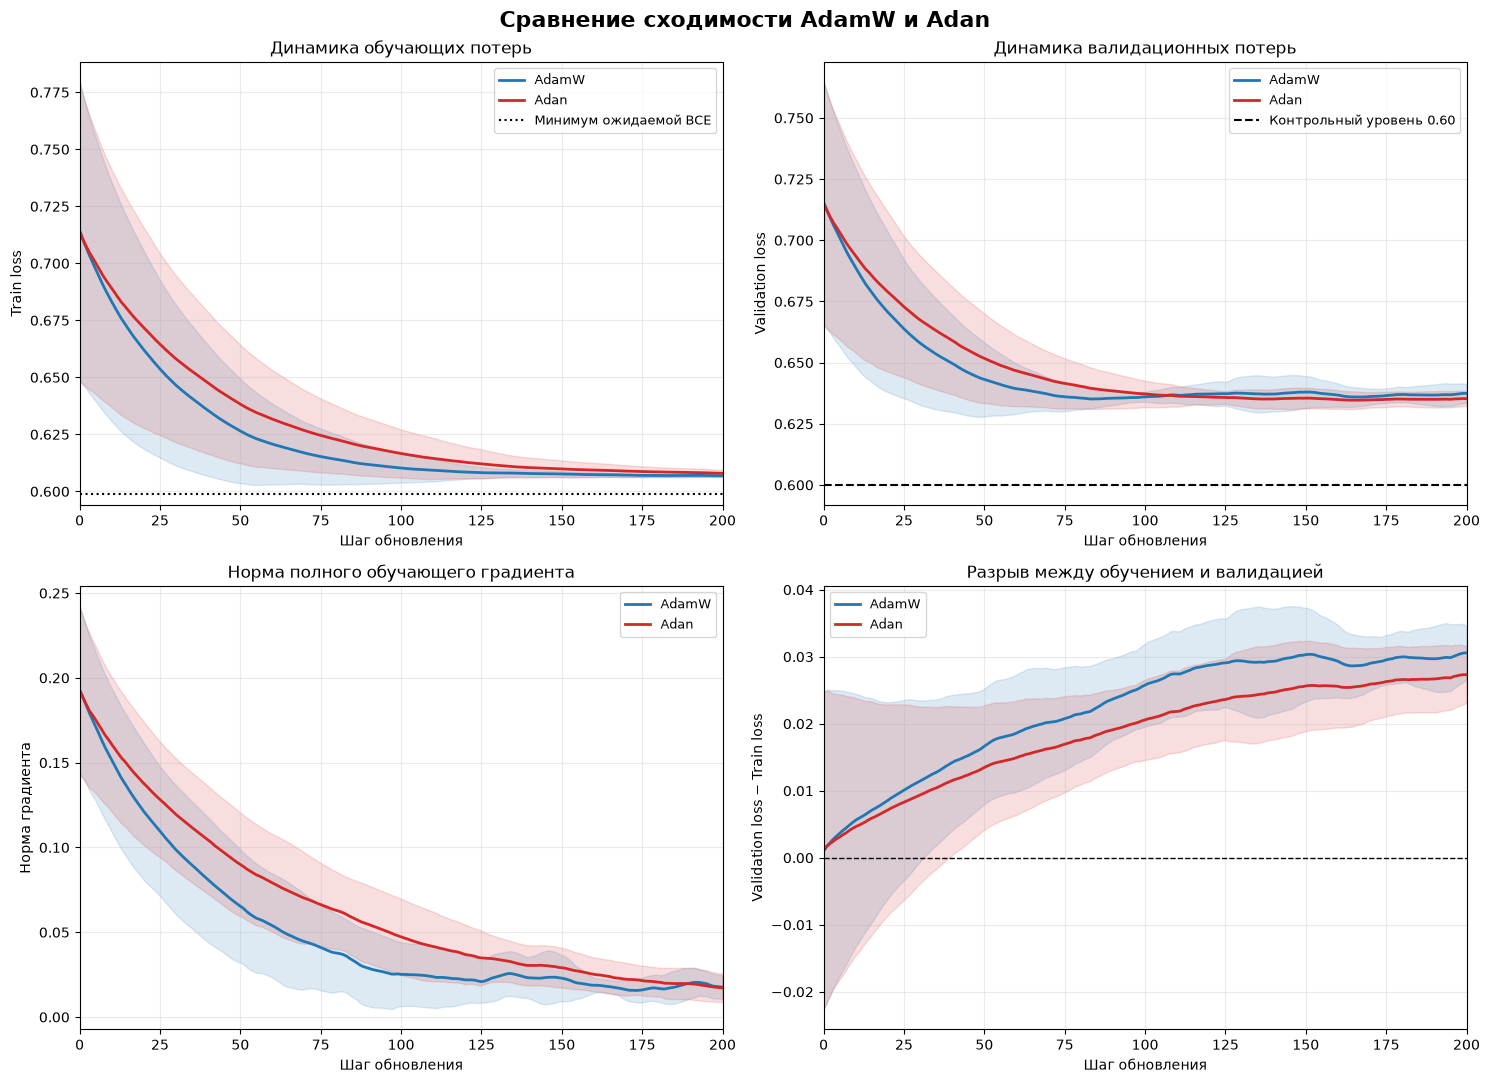

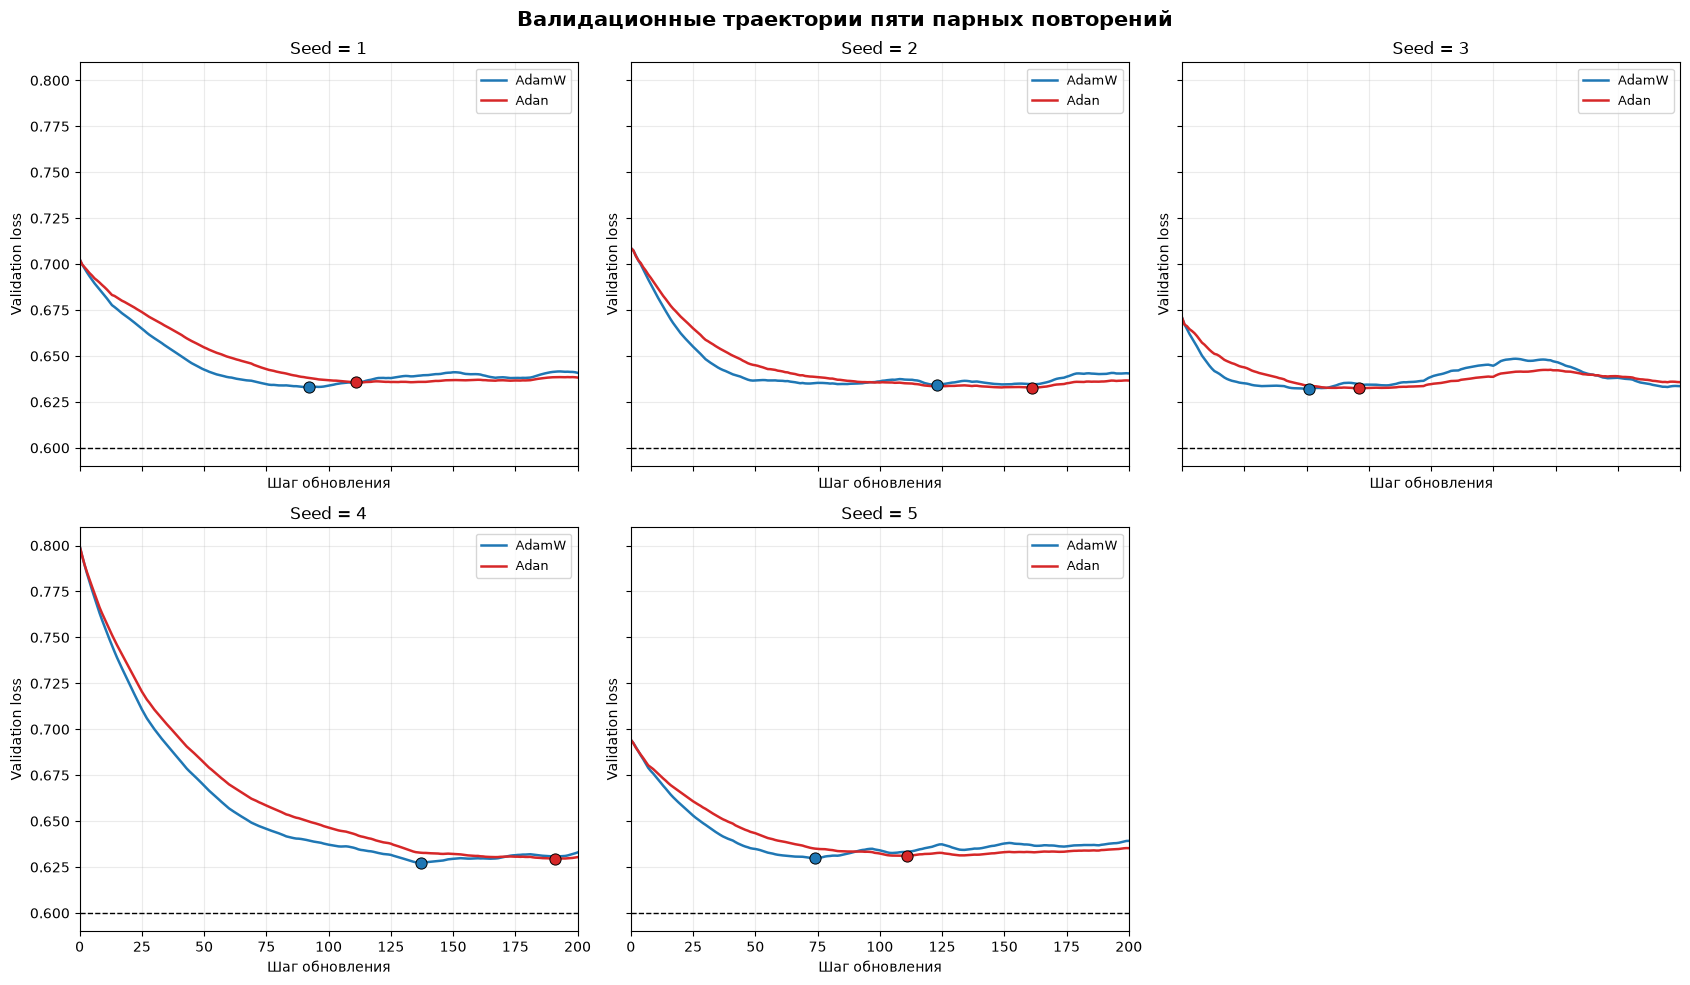

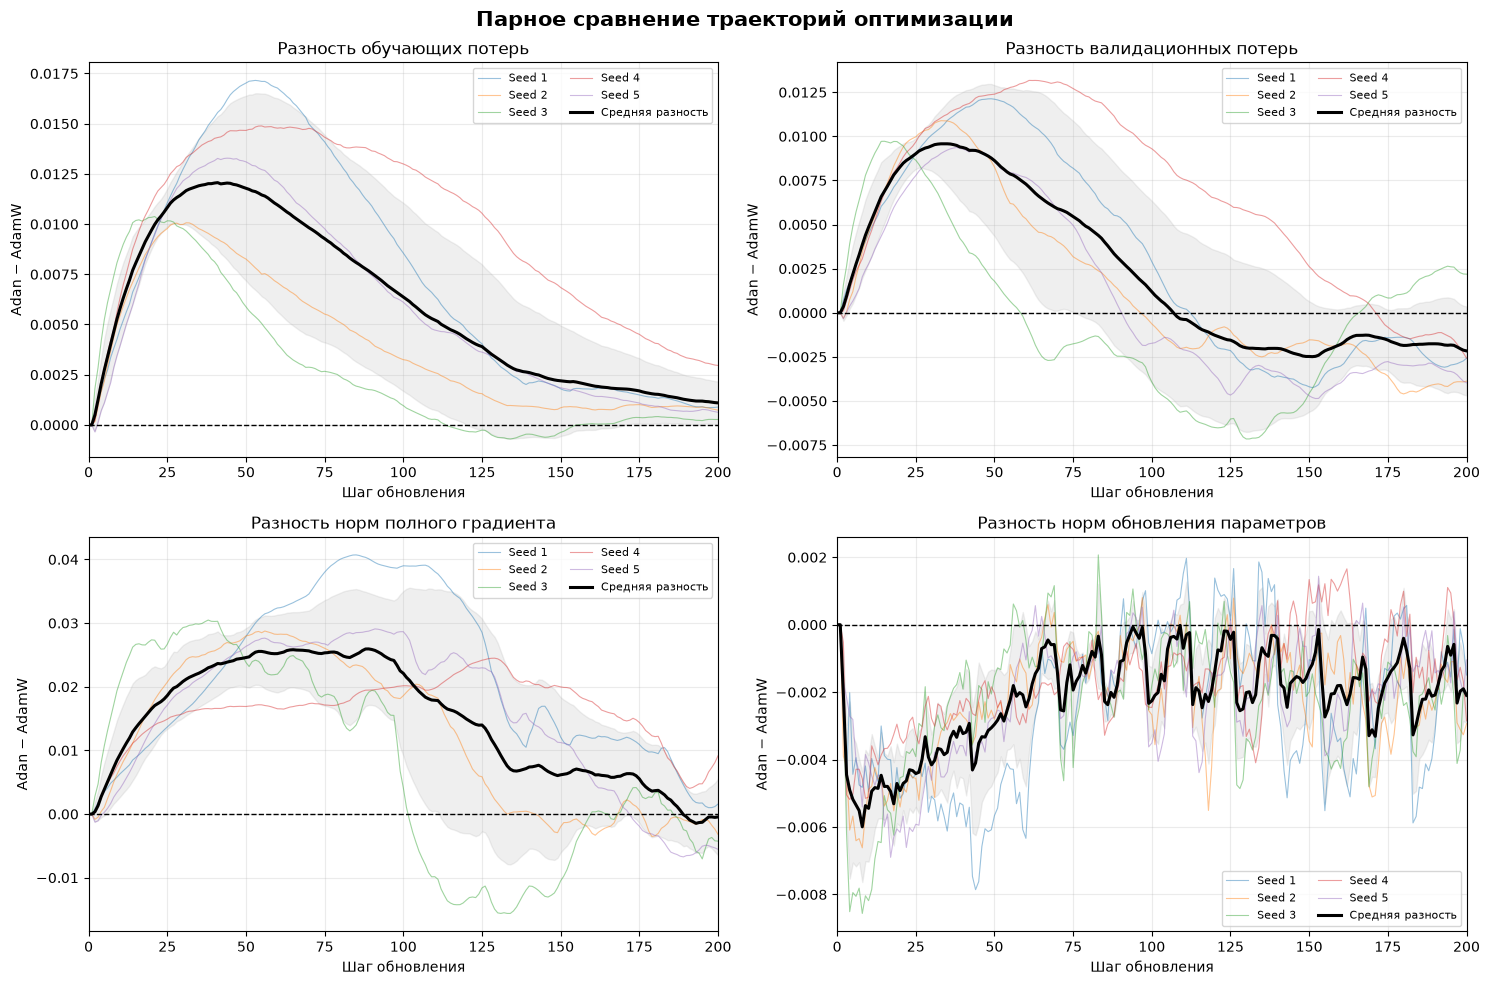

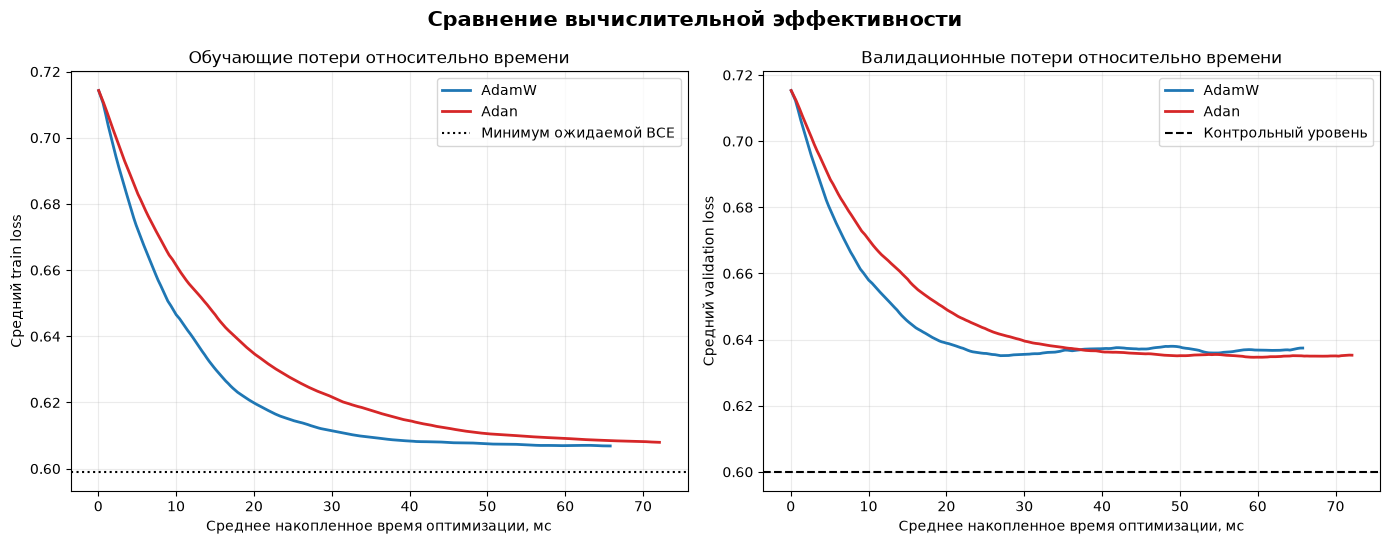

Сравнение качества оптимизации:
Среднее ± выборочное стандартное отклонение


,AdamW,Adan
Начальный train loss,0.71427900 ± 0.06524999,0.71427900 ± 0.06524999
Начальный validation loss,0.71530576 ± 0.04939940,0.71530576 ± 0.04939940
Train loss после 200 шагов,0.60686525 ± 0.00056655,0.60796215 ± 0.00147222
Validation loss после 200 шагов,0.63744334 ± 0.00385275,0.63528319 ± 0.00295846
Минимальный validation loss,0.63135662 ± 0.00269360,0.63232689 ± 0.00226082
Лучшая итерация,95.40 ± 35.12,129.00 ± 47.12
Train loss на лучшей итерации,0.60935812 ± 0.00208909,0.61079846 ± 0.00232748
Конечная норма полного градиента,0.01768050 ± 0.00708720,0.01722842 ± 0.00834287
Минимальная норма полного градиента,0.01045478 ± 0.00424503,0.01681540 ± 0.00795257
Относительное уменьшение train loss,14.52% ± 7.14 п.п.,14.37% ± 7.02 п.п.



Численная устойчивость методов:


Метод,Запуски,Принятые шаги,Отклонённые шаги,Нечисловые события,Увеличения train loss,Увеличения validation loss
AdamW,5,1000,0,0,183,372
Adan,5,1000,0,0,58,276



Индивидуальные результаты парного сравнения:


Показатель,Seed,AdamW,Adan,Adan − AdamW
Конечный train loss,1,0.60709334,0.60798141,+0.00088806
Конечный train loss,2,0.60599394,0.60673057,+0.00073662
Конечный train loss,3,0.60664275,0.60691347,+0.00027072
Конечный train loss,4,0.60745381,0.61041491,+0.00296111
Конечный train loss,5,0.60714242,0.60777040,+0.00062798
Конечный validation loss,1,0.64086453,0.63828898,-0.00257555
Конечный validation loss,2,0.64052856,0.63664941,-0.00387915
Конечный validation loss,3,0.63359925,0.63578722,+0.00218797
Конечный validation loss,4,0.63296332,0.63039908,-0.00256424
Конечный validation loss,5,0.63926104,0.63529127,-0.00396978


... (3 outputs left out)

method,AdamW,Adan,Adan − AdamW
seed,,,
1,92,111,19
2,123,161,38
3,51,71,20
4,137,191,54
5,74,111,37


Средняя разность лучших итераций: 33.60

Достижение контрольного уровня validation loss ≤ 0.60:


,Запусков,Успешных запусков,Средний минимальный validation loss,Средний конечный validation loss,Доля успешных запусков
method,,,,,
AdamW,5,0,0.63135662,0.63744334,0.00%
Adan,5,0,0.63232689,0.63528319,0.00%



Ни один оптимизатор не достиг контрольного уровня.
Сравнение времени и количества шагов до достижения этого уровня невозможно.
Контрольный уровень не изменяется.

Количество сохранённых состояний: 2010
Количество парных повторений: 5
Количество средних состояний: 402
Гиперпараметры оптимизаторов не изменялись.
Статистическая значимость различий не устанавливалась.
Тестовая выборка для оценки моделей ещё не использовалась.

Анализ траекторий оптимизации завершён.


In [9]:
# =============================================
# Формирование общей истории эксперимента
# =============================================

history_columns = [
    "method",
    "seed",
    "iteration",
    "epoch",
    "batch_size",
    "batch_loss",
    "train_loss",
    "validation_loss",
    "gradient_norm",
    "stochastic_gradient_norm",
    "parameter_norm",
    "step_norm",
    "gradient_difference_norm",
    "nesterov_correction_norm",
    "accepted",
    "batch_gradient_calls",
    "full_gradient_calls",
    "total_backward_calls",
    "total_loss_calls",
    "processed_samples",
    "measured_core_elapsed_time_ms",
    "elapsed_time_ms"
]

history_df = pd.DataFrame([
    {
        column: record.get(column, np.nan)
        for column in history_columns
    }

    for result in experiment_results.values()

    for record in result["iteration_history"]
])

history_df["method"] = pd.Categorical(
    history_df["method"],
    categories=methods,
    ordered=True
)

history_df = (
    history_df
    .sort_values(["method", "seed", "iteration"])
    .reset_index(drop=True)
)

# Разрыв между обучающими
# и валидационными потерями
history_df["generalization_gap"] = (
    history_df["validation_loss"]
    - history_df["train_loss"]
)

assert len(history_df) == 2010

assert not history_df.duplicated(
    subset=["method", "seed", "iteration"]
).any()

assert (
    history_df.groupby(
        ["method", "iteration"],
        observed=True
    ).size() == n_repeats
).all()


# =============================================
# Средние траектории и стандартные отклонения
# =============================================

trajectory_metrics = [
    "train_loss",
    "validation_loss",
    "gradient_norm",
    "batch_loss",
    "stochastic_gradient_norm",
    "step_norm",
    "generalization_gap",
    "measured_core_elapsed_time_ms"
]

trajectory_stats = (
    history_df
    .groupby(
        ["method", "iteration"],
        observed=True
    )[trajectory_metrics]
    .agg(["mean", "std"])
)

trajectory_stats.columns = [
    f"{metric}_{stat}"
    for metric, stat in trajectory_stats.columns
]

trajectory_stats = trajectory_stats.reset_index()

assert len(trajectory_stats) == 402


# =============================================
# Цветовое оформление графиков
# =============================================

method_colors = {
    "AdamW": "#1f77b4",
    "Adan": "#d62728"
}


# =============================================
# Основные кривые сходимости
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 11)
)

plot_settings = [
    (
        axes[0, 0],
        "train_loss",
        "Динамика обучающих потерь",
        "Train loss"
    ),

    (
        axes[0, 1],
        "validation_loss",
        "Динамика валидационных потерь",
        "Validation loss"
    ),

    (
        axes[1, 0],
        "gradient_norm",
        "Норма полного обучающего градиента",
        "Норма градиента"
    ),

    (
        axes[1, 1],
        "generalization_gap",
        "Разрыв между обучением и валидацией",
        "Validation loss − Train loss"
    )
]

for ax, metric, title, ylabel in plot_settings:

    for method in methods:

        subset = trajectory_stats[
            trajectory_stats["method"] == method
        ]

        x = subset["iteration"].to_numpy()

        mean = subset[
            f"{metric}_mean"
        ].to_numpy()

        std = subset[
            f"{metric}_std"
        ].to_numpy()

        color = method_colors[method]

        ax.plot(
            x,
            mean,
            color=color,
            linewidth=2,
            label=method
        )

        lower = mean - std

        upper = mean + std

        # Норма градиента не может быть отрицательной
        if metric == "gradient_norm":

            lower = np.maximum(lower, 0)

        ax.fill_between(
            x,
            lower,
            upper,
            color=color,
            alpha=0.15
        )

    ax.set_title(title)

    ax.set_xlabel("Шаг обновления")

    ax.set_ylabel(ylabel)

    ax.set_xlim(0, iterations)

    ax.grid(alpha=0.25)


# Теоретический ориентир
axes[0, 0].axhline(
    expected_bayes_loss,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Минимум ожидаемой BCE"
)

# Контрольный уровень качества
axes[0, 1].axhline(
    quality_threshold,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Контрольный уровень {quality_threshold:.2f}"
)

# Нулевой разрыв потерь
axes[1, 1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

for ax in axes.flat:

    ax.legend(fontsize=9)

fig.suptitle(
    "Сравнение сходимости AdamW и Adan",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Индивидуальные траектории пяти повторений
# =============================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10),
    sharex=True,
    sharey=True
)

for ax, network_seed in zip(
    axes.flat,
    network_seeds
):

    for method in methods:

        subset = history_df[
            (history_df["method"] == method)

            & (history_df["seed"] == network_seed)
        ]

        color = method_colors[method]

        ax.plot(
            subset["iteration"],
            subset["validation_loss"],
            color=color,
            linewidth=1.8,
            label=method
        )

        # Минимум validation loss
        best_record = experiment_results[
            (method, network_seed)
        ]["best_record"]

        ax.scatter(
            best_record["iteration"],
            best_record["validation_loss"],
            color=color,
            edgecolor="black",
            linewidth=0.7,
            s=65,
            zorder=5
        )

    ax.axhline(
        quality_threshold,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"Seed = {network_seed}")

    ax.set_xlabel("Шаг обновления")

    ax.set_ylabel("Validation loss")

    ax.set_xlim(0, iterations)

    ax.grid(alpha=0.25)

    ax.legend(fontsize=9)

# Шестая область не используется
axes.flat[-1].axis("off")

fig.suptitle(
    "Валидационные траектории пяти парных повторений",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Парные разности траекторий
# =============================================

paired_trajectories = {}

for metric in [
    "train_loss",
    "validation_loss",
    "gradient_norm",
    "step_norm"
]:

    paired = history_df.pivot(
        index=["seed", "iteration"],
        columns="method",
        values=metric
    )

    # Положительная разность означает,
    # что значение Adan больше значения AdamW
    paired["difference"] = (
        paired["Adan"] - paired["AdamW"]
    )

    paired_trajectories[metric] = (
        paired.reset_index()
    )


fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

difference_settings = [
    (
        "train_loss",
        "Разность обучающих потерь"
    ),

    (
        "validation_loss",
        "Разность валидационных потерь"
    ),

    (
        "gradient_norm",
        "Разность норм полного градиента"
    ),

    (
        "step_norm",
        "Разность норм обновления параметров"
    )
]

for ax, (metric, title) in zip(
    axes.flat,
    difference_settings
):

    paired = paired_trajectories[metric]

    # Индивидуальные парные разности
    for network_seed in network_seeds:

        subset = paired[
            paired["seed"] == network_seed
        ]

        ax.plot(
            subset["iteration"],
            subset["difference"],
            linewidth=0.8,
            alpha=0.45,
            label=f"Seed {network_seed}"
        )

    # Средняя парная разность
    difference_stats = (
        paired
        .groupby("iteration")["difference"]
        .agg(["mean", "std"])
        .reset_index()
    )

    x = difference_stats["iteration"].to_numpy()

    mean = difference_stats["mean"].to_numpy()

    std = difference_stats["std"].to_numpy()

    ax.plot(
        x,
        mean,
        color="black",
        linewidth=2.2,
        label="Средняя разность"
    )

    ax.fill_between(
        x,
        mean - std,
        mean + std,
        color="gray",
        alpha=0.12
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(title)

    ax.set_xlabel("Шаг обновления")

    ax.set_ylabel("Adan − AdamW")

    ax.set_xlim(0, iterations)

    ax.grid(alpha=0.25)

    ax.legend(
        fontsize=8,
        ncol=2
    )

fig.suptitle(
    "Парное сравнение траекторий оптимизации",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Сходимость относительно вычислительного времени
# =============================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5)
)

for method in methods:

    subset = trajectory_stats[
        trajectory_stats["method"] == method
    ]

    color = method_colors[method]

    mean_time = subset[
        "measured_core_elapsed_time_ms_mean"
    ].to_numpy()

    axes[0].plot(
        mean_time,
        subset["train_loss_mean"],
        color=color,
        linewidth=2,
        label=method
    )

    axes[1].plot(
        mean_time,
        subset["validation_loss_mean"],
        color=color,
        linewidth=2,
        label=method
    )

axes[0].axhline(
    expected_bayes_loss,
    color="black",
    linestyle=":",
    label="Минимум ожидаемой BCE"
)

axes[1].axhline(
    quality_threshold,
    color="black",
    linestyle="--",
    label="Контрольный уровень"
)

axes[0].set_title(
    "Обучающие потери относительно времени"
)

axes[0].set_ylabel("Средний train loss")

axes[1].set_title(
    "Валидационные потери относительно времени"
)

axes[1].set_ylabel("Средний validation loss")

for ax in axes:

    ax.set_xlabel(
        "Среднее накопленное время оптимизации, мс"
    )

    ax.grid(alpha=0.25)

    ax.legend()

fig.suptitle(
    "Сравнение вычислительной эффективности",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Сводные статистики качества оптимизации
# =============================================

quality_metrics = {
    "initial_train_loss":
        "Начальный train loss",

    "initial_validation_loss":
        "Начальный validation loss",

    "final_train_loss":
        "Train loss после 200 шагов",

    "final_validation_loss":
        "Validation loss после 200 шагов",

    "best_validation_loss":
        "Минимальный validation loss",

    "best_iteration":
        "Лучшая итерация",

    "train_loss_at_best":
        "Train loss на лучшей итерации",

    "final_gradient_norm":
        "Конечная норма полного градиента",

    "min_gradient_norm":
        "Минимальная норма полного градиента",

    "train_loss_reduction":
        "Относительное уменьшение train loss",

    "validation_loss_reduction":
        "Относительное уменьшение validation loss",

    "final_generalization_gap":
        "Конечный разрыв потерь",

    "mean_stochastic_gradient_norm":
        "Средняя норма стохастического градиента",

    "std_stochastic_gradient_norm":
        "Разброс норм стохастических градиентов",

    "mean_step_norm":
        "Средняя норма обновления параметров",

    "std_step_norm":
        "Разброс норм обновлений параметров",

    "max_step_norm":
        "Максимальная норма обновления"
}

quality_stats = (
    experiment_df
    .groupby("method", observed=True)[
        list(quality_metrics)
    ]
    .agg(["mean", "std"])
)

quality_summary = pd.DataFrame(
    index=list(quality_metrics.values()),
    columns=methods,
    dtype=object
)

for metric, label in quality_metrics.items():

    for method in methods:

        mean_value = quality_stats.loc[
            method,
            (metric, "mean")
        ]

        std_value = quality_stats.loc[
            method,
            (metric, "std")
        ]

        if metric.endswith("_reduction"):

            formatted = (
                f"{mean_value:.2%} ± "
                f"{std_value * 100:.2f} п.п."
            )

        elif metric == "best_iteration":

            formatted = (
                f"{mean_value:.2f} ± "
                f"{std_value:.2f}"
            )

        else:

            formatted = (
                f"{mean_value:.8f} ± "
                f"{std_value:.8f}"
            )

        quality_summary.loc[
            label,
            method
        ] = formatted

print("Сравнение качества оптимизации:")

print(
    "Среднее ± выборочное стандартное отклонение"
)

display(quality_summary)


# =============================================
# Анализ численной устойчивости
# =============================================

stability_summary = (
    experiment_df
    .groupby("method", observed=True)
    .agg(
        runs=("seed", "count"),

        accepted_steps=(
            "accepted_steps", "sum"
        ),

        rejected_steps=(
            "rejected_steps", "sum"
        ),

        nonfinite_steps=(
            "nonfinite_steps", "sum"
        ),

        train_loss_increases=(
            "train_loss_increases", "sum"
        ),

        validation_loss_increases=(
            "validation_loss_increases", "sum"
        )
    )
    .reset_index()
)

print("\nЧисленная устойчивость методов:")

display(
    stability_summary
    .rename(columns={
        "method": "Метод",

        "runs": "Запуски",

        "accepted_steps": "Принятые шаги",

        "rejected_steps": "Отклонённые шаги",

        "nonfinite_steps": "Нечисловые события",

        "train_loss_increases":
            "Увеличения train loss",

        "validation_loss_increases":
            "Увеличения validation loss"
    })
    .style.hide(axis="index")
)


# =============================================
# Парное сравнение итоговых показателей
# =============================================

paired_metrics = {
    "final_train_loss":
        "Конечный train loss",

    "final_validation_loss":
        "Конечный validation loss",

    "best_validation_loss":
        "Минимальный validation loss",

    "final_gradient_norm":
        "Конечная норма градиента",

    "mean_step_norm":
        "Средняя норма обновления",

    "core_time_ms":
        "Время оптимизации, мс",

    "torch_peak_kib":
        "Пиковая память PyTorch, КиБ"
}

paired_comparison_records = []

paired_summary_records = []

comparison_tolerance = 1e-12

for metric, label in paired_metrics.items():

    paired = experiment_df.pivot(
        index="seed",
        columns="method",
        values=metric
    )

    difference = (
        paired["Adan"] - paired["AdamW"]
    )

    for network_seed in network_seeds:

        adamw_value = paired.loc[
            network_seed, "AdamW"
        ]

        adan_value = paired.loc[
            network_seed, "Adan"
        ]

        delta = difference.loc[
            network_seed
        ]

        paired_comparison_records.append({
            "Показатель": label,

            "Seed": network_seed,

            "AdamW": adamw_value,

            "Adan": adan_value,

            "Adan − AdamW": delta
        })

    n_lower = int(
        (difference < -comparison_tolerance).sum()
    )

    n_higher = int(
        (difference > comparison_tolerance).sum()
    )

    n_equal = int(
        (
            difference.abs()
            <= comparison_tolerance
        ).sum()
    )

    paired_summary_records.append({
        "Показатель": label,

        "Средняя разность": difference.mean(),

        "Стандартное отклонение разности": (
            difference.std(ddof=1)
        ),

        "Adan < AdamW": n_lower,

        "Adan > AdamW": n_higher,

        "Совпадения": n_equal
    })


paired_comparison_df = pd.DataFrame(
    paired_comparison_records
)

paired_summary_df = pd.DataFrame(
    paired_summary_records
)

print("\nИндивидуальные результаты парного сравнения:")

display(
    paired_comparison_df.style
    .hide(axis="index")
    .format({
        "AdamW": "{:.8f}",
        "Adan": "{:.8f}",
        "Adan − AdamW": "{:+.8f}"
    })
)

print("\nСводные характеристики парных разностей:")

display(
    paired_summary_df.style
    .hide(axis="index")
    .format({
        "Средняя разность": "{:+.8f}",

        "Стандартное отклонение разности":
            "{:.8f}"
    })
)


# =============================================
# Сравнение лучших итераций
# =============================================

best_iteration_comparison = experiment_df.pivot(
    index="seed",
    columns="method",
    values="best_iteration"
)

best_iteration_comparison["Adan − AdamW"] = (
    best_iteration_comparison["Adan"]
    - best_iteration_comparison["AdamW"]
)

print("\nИтерации достижения минимального validation loss:")

display(best_iteration_comparison)

print(
    "Средняя разность лучших итераций:",
    f"{best_iteration_comparison['Adan − AdamW'].mean():.2f}"
)


# =============================================
# Анализ достижения контрольного уровня
# =============================================

threshold_summary = (
    experiment_df
    .groupby("method", observed=True)
    .agg(
        runs=("seed", "count"),

        successful_runs=(
            "threshold_reached", "sum"
        ),

        mean_best_validation_loss=(
            "best_validation_loss", "mean"
        ),

        mean_final_validation_loss=(
            "final_validation_loss", "mean"
        )
    )
)

threshold_summary["success_rate"] = (
    threshold_summary["successful_runs"]
    / threshold_summary["runs"]
)

print(
    f"\nДостижение контрольного уровня "
    f"validation loss ≤ {quality_threshold:.2f}:"
)

display(
    threshold_summary
    .rename(columns={
        "runs": "Запусков",

        "successful_runs": "Успешных запусков",

        "mean_best_validation_loss":
            "Средний минимальный validation loss",

        "mean_final_validation_loss":
            "Средний конечный validation loss",

        "success_rate": "Доля успешных запусков"
    })
    .style.format({
        "Средний минимальный validation loss":
            "{:.8f}",

        "Средний конечный validation loss":
            "{:.8f}",

        "Доля успешных запусков":
            "{:.2%}"
    })
)

if not experiment_df["threshold_reached"].any():

    print(
        "\nНи один оптимизатор не достиг "
        "контрольного уровня."
    )

    print(
        "Сравнение времени и количества шагов "
        "до достижения этого уровня невозможно."
    )

    print(
        "Контрольный уровень не изменяется."
    )


# =============================================
# Итоговые проверки
# =============================================

print(
    "\nКоличество сохранённых состояний:",
    len(history_df)
)

print(
    "Количество парных повторений:",
    n_repeats
)

print(
    "Количество средних состояний:",
    len(trajectory_stats)
)

print(
    "Гиперпараметры оптимизаторов не изменялись."
)

print(
    "Статистическая значимость различий "
    "не устанавливалась."
)

print(
    "Тестовая выборка для оценки моделей "
    "ещё не использовалась."
)

print(
    "\nАнализ траекторий оптимизации завершён."
)

Согласованность обновлений с полным градиентом:



Характеристики обновлений по размерам мини-батчей:


Метод,Размер батча,Шагов,Отклонение градиента,Норма обновления,Косинусное сходство,Доля направлений спуска,Изменение train loss
AdamW,4,70,0.45887365,0.01020525,0.45637258,0.82857143,-0.00043883
AdamW,32,930,0.16150608,0.00947274,0.44614524,0.82688172,-0.00054446
Adan,4,70,0.45591700,0.00868206,0.52156302,0.90000000,-0.00045128
Adan,32,930,0.15895743,0.00725345,0.62499405,0.94838710,-0.00053763



Компоненты обновления Adan:


,Шагов,Норма разности градиентов,Коррекция Нестерова,Основная составляющая,Дополнительная составляющая,Отношение норм составляющих,Сходство составляющих,Норма итогового обновления
batch_type,,,,,,,,
Неполный батч (4),70.00000000,0.48291137,0.03516708,0.00713750,0.00244857,0.43455429,0.54156500,0.00868206
Остальные полные батчи,860.00000000,0.23070563,0.01472349,0.00715624,0.00114915,0.22275705,0.01401463,0.00725933
Первый батч после неполного,70.00000000,0.49155290,0.01269251,0.00705509,0.00087994,0.15866881,0.06477920,0.00718125


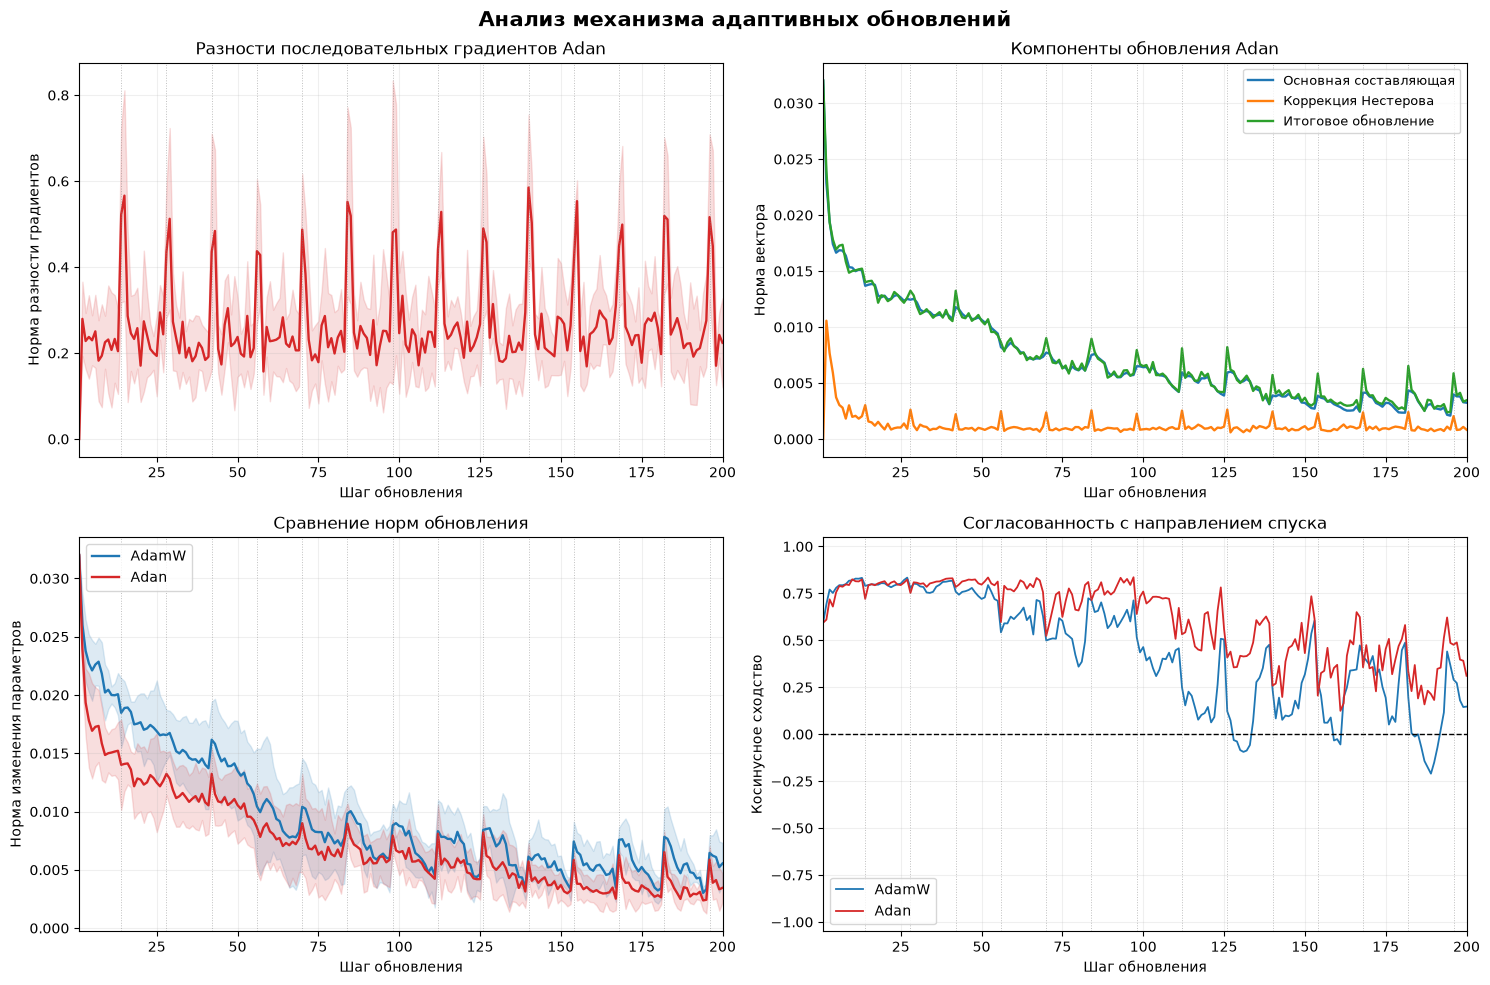


Сравнение плавности траекторий:


Показатель,AdamW,Adan,Относительное изменение
Средняя норма обновления,0.00952401,0.00735346,-22.79%
Разброс норм обновлений,0.00568267,0.00455700,-19.81%
Увеличения train loss,36.60000000,11.60000000,-68.31%
Увеличения validation loss,74.40000000,55.20000000,-25.81%



Исследовано обновлений: 2000
Исследовано обновлений Adan: 1000
Максимальная ошибка восстановления шага Adan: 5.59448321e-17
Дополнительных обратных проходов: 0
Дополнительных обновлений параметров: 0
Тестовая выборка не использовалась.
Анализ механизма Adan завершён.


In [10]:
# =============================================
# Анализ направлений обновления параметров
# =============================================

mechanism_records = []

for (method, network_seed), result in experiment_results.items():

    history = result["iteration_history"]

    for previous, current in zip(
        history[:-1],
        history[1:]
    ):

        # Фактическое обновление параметров
        update = current["theta"] - previous["theta"]

        # Полный градиент до обновления
        full_gradient = previous["full_gradient"]

        stochastic_gradient = current["stochastic_gradient"]

        # Согласованность обновления с направлением спуска
        descent_cosine = F.cosine_similarity(
            update,
            -full_gradient,
            dim=0,
            eps=1e-15
        ).item()

        directional_derivative = torch.dot(
            full_gradient,
            update
        ).item()

        # Отклонение стохастического градиента от полного
        gradient_error = torch.linalg.vector_norm(
            stochastic_gradient - full_gradient
        ).item()

        record = {
            "method": method,
            "seed": network_seed,
            "iteration": current["iteration"],
            "batch_size": current["batch_size"],

            "after_partial_batch": (
                previous["batch_size"] == 4
            ),

            "step_norm": current["step_norm"],

            "gradient_error_norm": gradient_error,

            "descent_cosine": descent_cosine,

            "directional_derivative": directional_derivative,

            "descent_direction": (
                directional_derivative < 0
            ),

            "train_loss_change": (
                current["train_loss"]
                - previous["train_loss"]
            ),

            "validation_loss_change": (
                current["validation_loss"]
                - previous["validation_loss"]
            )
        }

        # =====================================
        # Декомпозиция обновления Adan
        # =====================================

        if method == "Adan" and current["accepted"]:

            state = current["optimizer_state"]

            settings = config["Adan"]

            t = state["step"]

            beta1 = settings["beta1"]
            beta2 = settings["beta2"]
            beta3 = settings["beta3"]

            eta = settings["eta"]
            eps = settings["eps"]

            m_hat = state["m"] / (1 - beta1 ** t)

            v_hat = state["v"] / (1 - beta2 ** t)

            n_hat = state["n"] / (1 - beta3 ** t)

            denominator = torch.sqrt(n_hat) + eps

            # Составляющая первого момента
            base_update = (
                -eta * m_hat / denominator
            )

            # Составляющая коррекции Нестерова
            correction_update = (
                -eta * beta2 * v_hat / denominator
            )

            reconstructed_update = (
                base_update + correction_update
            )

            # Проверка восстановления фактического шага
            reconstruction_error = torch.max(
                torch.abs(
                    update - reconstructed_update
                )
            ).item()

            assert torch.allclose(
                update,
                reconstructed_update,
                atol=1e-12,
                rtol=1e-10
            )

            base_norm = torch.linalg.vector_norm(
                base_update
            ).item()

            correction_norm = torch.linalg.vector_norm(
                correction_update
            ).item()

            # Согласованность двух составляющих
            component_cosine = (
                F.cosine_similarity(
                    base_update,
                    correction_update,
                    dim=0,
                    eps=1e-15
                ).item()

                if correction_norm > 0 and base_norm > 0

                else np.nan
            )

            record.update({
                "gradient_difference_norm": (
                    current["gradient_difference_norm"]
                ),

                "nesterov_correction_norm": (
                    current["nesterov_correction_norm"]
                ),

                "base_update_norm": base_norm,

                "correction_update_norm": correction_norm,

                "correction_ratio": (
                    correction_norm / max(base_norm, 1e-15)
                ),

                "component_cosine": component_cosine,

                "reconstruction_error": reconstruction_error
            })

        mechanism_records.append(record)


mechanism_df = pd.DataFrame(mechanism_records)

assert len(mechanism_df) == 2000

adan_mechanism_df = mechanism_df[
    mechanism_df["method"] == "Adan"
].copy()

assert len(adan_mechanism_df) == 1000


# =============================================
# Согласованность обновлений с полным градиентом
# =============================================

direction_stats = (
    mechanism_df
    .groupby(["method", "seed"])
    .agg(
        mean_descent_cosine=("descent_cosine", "mean"),

        descent_share=("descent_direction", "mean"),

        mean_gradient_error=("gradient_error_norm", "mean"),

        mean_step_norm=("step_norm", "mean")
    )
    .reset_index()
)

direction_summary = (
    direction_stats
    .groupby("method")[
        [
            "mean_descent_cosine",
            "descent_share",
            "mean_gradient_error",
            "mean_step_norm"
        ]
    ]
    .agg(["mean", "std"])
    .reindex(methods)
)

print("Согласованность обновлений с полным градиентом:")

display(
    direction_summary
    .rename(columns={
        "mean_descent_cosine": "Косинусное сходство",
        "descent_share": "Доля направлений спуска",
        "mean_gradient_error": "Отклонение градиента",
        "mean_step_norm": "Норма обновления"
    })
    .style.format("{:.6f}")
)


# =============================================
# Характеристики обновлений для разных батчей
# =============================================

batch_mechanism_stats = (
    mechanism_df
    .groupby(["method", "batch_size"])
    .agg(
        steps=("iteration", "count"),

        mean_gradient_error=("gradient_error_norm", "mean"),

        mean_step_norm=("step_norm", "mean"),

        mean_descent_cosine=("descent_cosine", "mean"),

        descent_share=("descent_direction", "mean"),

        mean_train_loss_change=("train_loss_change", "mean")
    )
    .reset_index()
)

print("\nХарактеристики обновлений по размерам мини-батчей:")

display(
    batch_mechanism_stats
    .rename(columns={
        "method": "Метод",
        "batch_size": "Размер батча",
        "steps": "Шагов",
        "mean_gradient_error": "Отклонение градиента",
        "mean_step_norm": "Норма обновления",
        "mean_descent_cosine": "Косинусное сходство",
        "descent_share": "Доля направлений спуска",
        "mean_train_loss_change": "Изменение train loss"
    })
    .style.hide(axis="index")
    .format(precision=8)
)


# =============================================
# Анализ механизма коррекции Нестерова
# =============================================

adan_mechanism_df["batch_type"] = np.select(
    [
        adan_mechanism_df["batch_size"] == 4,

        adan_mechanism_df["after_partial_batch"]
    ],
    [
        "Неполный батч (4)",

        "Первый батч после неполного"
    ],
    default="Остальные полные батчи"
)

adan_component_stats = (
    adan_mechanism_df
    .groupby("batch_type")
    .agg(
        steps=("iteration", "count"),

        gradient_difference=(
            "gradient_difference_norm", "mean"
        ),

        nesterov_correction=(
            "nesterov_correction_norm", "mean"
        ),

        base_update=(
            "base_update_norm", "mean"
        ),

        correction_update=(
            "correction_update_norm", "mean"
        ),

        correction_ratio=(
            "correction_ratio", "mean"
        ),

        component_cosine=(
            "component_cosine", "mean"
        ),

        actual_step=(
            "step_norm", "mean"
        )
    )
)

print("\nКомпоненты обновления Adan:")

display(
    adan_component_stats
    .rename(columns={
        "steps": "Шагов",

        "gradient_difference": "Норма разности градиентов",

        "nesterov_correction": "Коррекция Нестерова",

        "base_update": "Основная составляющая",

        "correction_update": "Дополнительная составляющая",

        "correction_ratio": "Отношение норм составляющих",

        "component_cosine": "Сходство составляющих",

        "actual_step": "Норма итогового обновления"
    })
    .style.format("{:.8f}")
)


# =============================================
# Визуализация механизма Adan
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

# 1. Разности последовательных градиентов

difference_stats = (
    adan_mechanism_df
    .groupby("iteration")["gradient_difference_norm"]
    .agg(["mean", "std"])
)

axes[0, 0].plot(
    difference_stats.index,
    difference_stats["mean"],
    color=method_colors["Adan"],
    linewidth=1.7
)

axes[0, 0].fill_between(
    difference_stats.index,
    np.maximum(
        difference_stats["mean"] - difference_stats["std"],
        0
    ),
    difference_stats["mean"] + difference_stats["std"],
    color=method_colors["Adan"],
    alpha=0.15
)

axes[0, 0].set_title(
    "Разности последовательных градиентов Adan"
)

axes[0, 0].set_ylabel("Норма разности градиентов")


# 2. Составляющие обновления Adan

component_trajectories = (
    adan_mechanism_df
    .groupby("iteration")[
        [
            "base_update_norm",
            "correction_update_norm",
            "step_norm"
        ]
    ]
    .mean()
)

for column, label in [
    ("base_update_norm", "Основная составляющая"),

    ("correction_update_norm", "Коррекция Нестерова"),

    ("step_norm", "Итоговое обновление")
]:

    axes[0, 1].plot(
        component_trajectories.index,
        component_trajectories[column],
        linewidth=1.7,
        label=label
    )

axes[0, 1].set_title("Компоненты обновления Adan")

axes[0, 1].set_ylabel("Норма вектора")

axes[0, 1].legend(fontsize=9)


# 3. Сравнение фактических норм обновлений

for method in methods:

    subset = mechanism_df[
        mechanism_df["method"] == method
    ]

    step_stats = (
        subset
        .groupby("iteration")["step_norm"]
        .agg(["mean", "std"])
    )

    axes[1, 0].plot(
        step_stats.index,
        step_stats["mean"],
        color=method_colors[method],
        linewidth=1.7,
        label=method
    )

    axes[1, 0].fill_between(
        step_stats.index,
        np.maximum(
            step_stats["mean"] - step_stats["std"],
            0
        ),
        step_stats["mean"] + step_stats["std"],
        color=method_colors[method],
        alpha=0.15
    )

axes[1, 0].set_title("Сравнение норм обновления")

axes[1, 0].set_ylabel("Норма изменения параметров")

axes[1, 0].legend()


# 4. Согласованность с направлением полного градиента

for method in methods:

    subset = mechanism_df[
        mechanism_df["method"] == method
    ]

    cosine_stats = (
        subset
        .groupby("iteration")["descent_cosine"]
        .mean()
    )

    axes[1, 1].plot(
        cosine_stats.index,
        cosine_stats,
        color=method_colors[method],
        linewidth=1.3,
        label=method
    )

axes[1, 1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1, 1].set_title(
    "Согласованность с направлением спуска"
)

axes[1, 1].set_ylabel("Косинусное сходство")

axes[1, 1].set_ylim(-1.05, 1.05)

axes[1, 1].legend()


# Границы завершённых эпох

for ax in axes.flat:

    for epoch in range(1, completed_epochs + 1):

        ax.axvline(
            epoch * batches_per_epoch,
            color="gray",
            linestyle=":",
            linewidth=0.7,
            alpha=0.5
        )

    ax.set_xlabel("Шаг обновления")

    ax.set_xlim(1, iterations)

    ax.grid(alpha=0.2)


fig.suptitle(
    "Анализ механизма адаптивных обновлений",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Сравнение плавности обновлений
# =============================================

smoothness_metrics = [
    "mean_step_norm",
    "std_step_norm",
    "train_loss_increases",
    "validation_loss_increases"
]

smoothness_records = []

for metric in smoothness_metrics:

    means = (
        experiment_df
        .groupby("method", observed=True)[metric]
        .mean()
    )

    adamw_value = means["AdamW"]

    adan_value = means["Adan"]

    smoothness_records.append({
        "Показатель": metric,

        "AdamW": adamw_value,

        "Adan": adan_value,

        "Относительное изменение": (
            adan_value / adamw_value - 1
        )
    })

smoothness_df = pd.DataFrame(smoothness_records)

smoothness_df["Показатель"] = (
    smoothness_df["Показатель"].replace({
        "mean_step_norm": "Средняя норма обновления",

        "std_step_norm": "Разброс норм обновлений",

        "train_loss_increases": "Увеличения train loss",

        "validation_loss_increases": "Увеличения validation loss"
    })
)

print("\nСравнение плавности траекторий:")

display(
    smoothness_df.style
    .hide(axis="index")
    .format({
        "AdamW": "{:.8f}",
        "Adan": "{:.8f}",
        "Относительное изменение": "{:+.2%}"
    })
)


# =============================================
# Итоговые проверки
# =============================================

print("\nИсследовано обновлений:", len(mechanism_df))

print("Исследовано обновлений Adan:", len(adan_mechanism_df))

print(
    "Максимальная ошибка восстановления шага Adan:",
    f"{adan_mechanism_df['reconstruction_error'].max():.8e}"
)

print("Дополнительных обратных проходов: 0")

print("Дополнительных обновлений параметров: 0")

print("Тестовая выборка не использовалась.")

print("Анализ механизма Adan завершён.")

Вычислительные затраты за 200 обновлений:
Среднее ± выборочное стандартное отклонение


,AdamW,Adan
Основные вычисления loss,200.0000 ± 0.0000,200.0000 ± 0.0000
Основные обратные проходы,200.0000 ± 0.0000,200.0000 ± 0.0000
Диагностические вычисления train loss,201.0000 ± 0.0000,201.0000 ± 0.0000
Диагностические обратные проходы,201.0000 ± 0.0000,201.0000 ± 0.0000
Вычисления validation loss,201.0000 ± 0.0000,201.0000 ± 0.0000
Все вычисления функции потерь,602.0000 ± 0.0000,602.0000 ± 0.0000
Все обратные проходы,401.0000 ± 0.0000,401.0000 ± 0.0000
Обработано наблюдений при оптимизации,6008.0000 ± 0.0000,6008.0000 ± 0.0000
Наблюдений при диагностике Train,84420.0000 ± 0.0000,84420.0000 ± 0.0000
Наблюдений при диагностике Validation,18090.0000 ± 0.0000,18090.0000 ± 0.0000



Относительные вычислительные затраты Adan:


Показатель,AdamW,Adan,Adan / AdamW,Относительное изменение
Время оптимизации,65.786541,72.112300,1.0962,+9.62%
Полное время,153.274300,164.433120,1.0728,+7.28%
Пиковая память PyTorch,9.007812,9.648438,1.0711,+7.11%
Пиковая память Python,43.218750,43.585938,1.0085,+0.85%
Выделения памяти PyTorch,15407.000000,20811.000000,1.3507,+35.07%
Постоянное числовое состояние,656.000000,1312.000000,2.0000,+100.00%



Средняя стоимость одного обновления, мкс:



Парное сравнение времени оптимизации:


method,AdamW,Adan,Adan − AdamW,Относительное изменение
seed,,,,
1,71.0787,71.8657,+0.7870,+1.11%
2,63.4285,73.4824,+10.0539,+15.85%
3,66.6768,70.3969,+3.7201,+5.58%
4,65.1294,72.1483,+7.0189,+10.78%
5,62.6193,72.6682,+10.0489,+16.05%


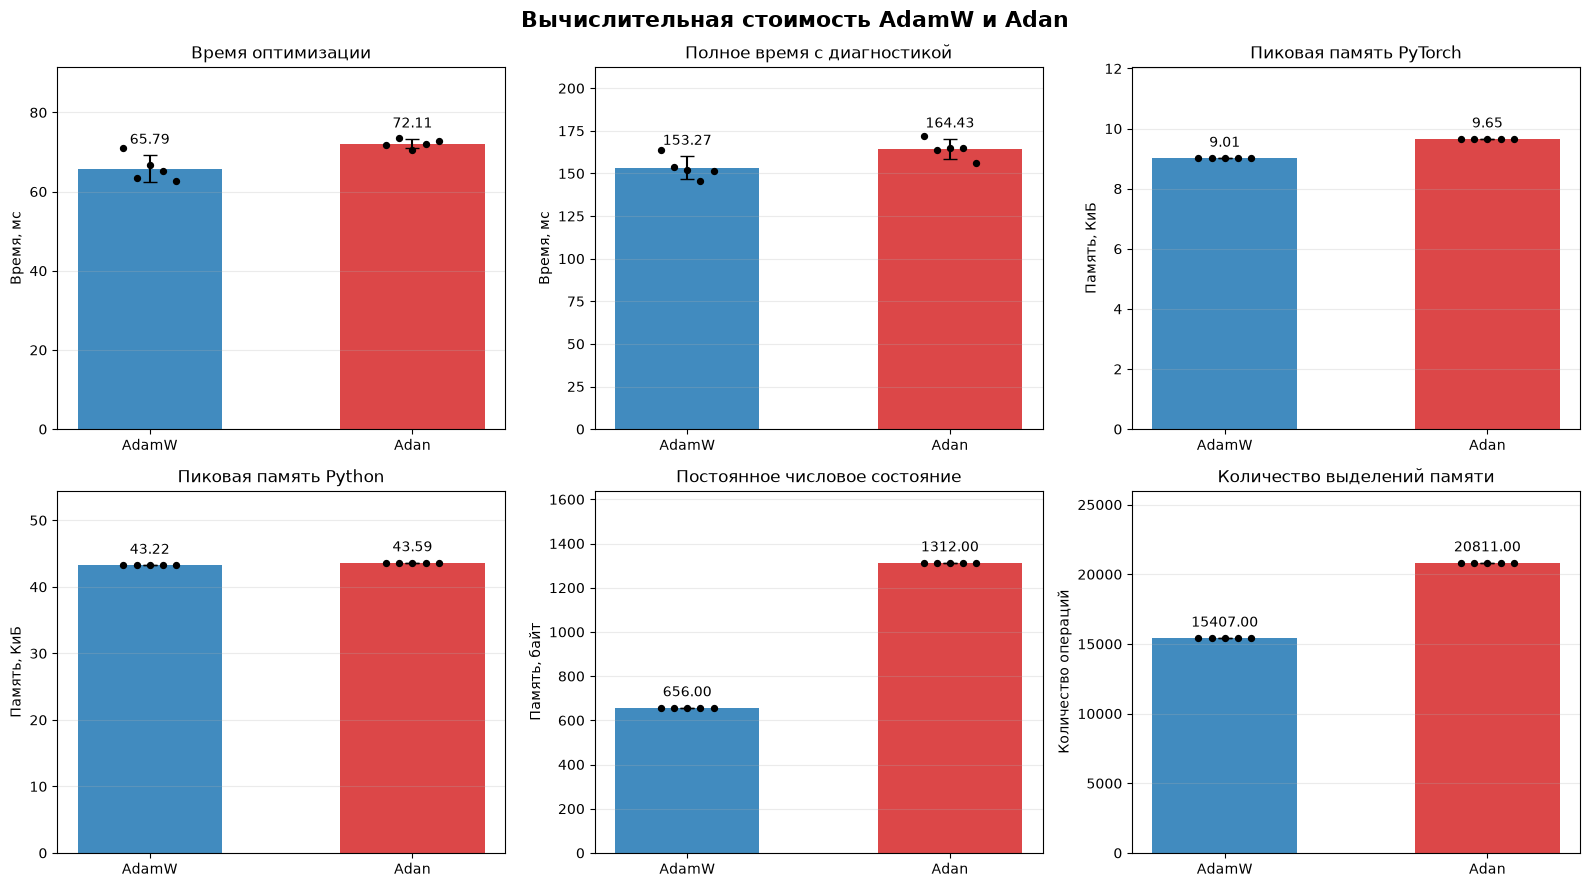

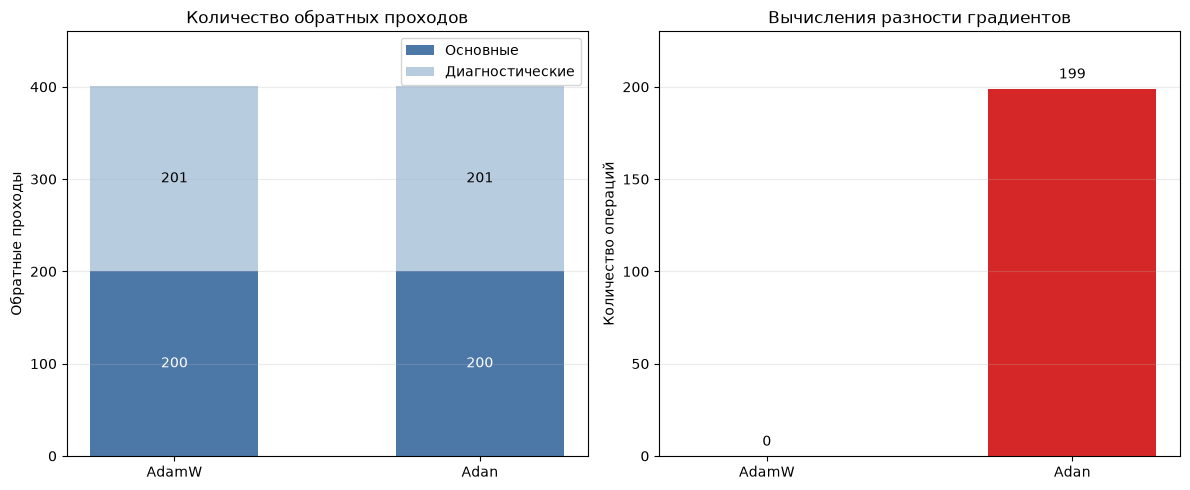


Затраты до достижения validation loss ≤ 0.60:


Метод,Успешных запусков,Всего запусков,Доля успешных запусков,Шагов до порога,Обратных проходов до порога,"Время до порога, мс"
AdamW,0,5,0.00%,Не достигнут,Не достигнут,Не достигнут
Adan,0,5,0.00%,Не достигнут,Не достигнут,Не достигнут



Итоговое сравнение вычислительной стоимости:
Среднее время AdamW: 65.7865 мс
Среднее время Adan: 72.1123 мс
Относительное изменение времени Adan: +9.62%
Относительное изменение пиковой памяти PyTorch: +7.11%
Разница постоянного состояния: 656 байт
Количество повторений, в которых Adan быстрее: 0 из 5

Сравнение затрат до достижения порога невозможно: порог не достигнут.

Вычислительные бюджеты методов совпадают.
Дополнительных обратных проходов Adan не требует.
Операции вычисления кривизны отсутствуют.
Память Python и PyTorch измерена отдельно.
Тестовая выборка не использовалась.
Анализ вычислительных затрат завершён.


In [11]:
# =============================================
# Сводные вычислительные затраты
# =============================================

cost_metrics = {
    "batch_loss_calls":
        "Основные вычисления loss",

    "batch_gradient_calls":
        "Основные обратные проходы",

    "full_train_loss_calls":
        "Диагностические вычисления train loss",

    "full_gradient_calls":
        "Диагностические обратные проходы",

    "validation_loss_calls":
        "Вычисления validation loss",

    "total_loss_calls":
        "Все вычисления функции потерь",

    "total_backward_calls":
        "Все обратные проходы",

    "processed_samples":
        "Обработано наблюдений при оптимизации",

    "diagnostic_train_samples":
        "Наблюдений при диагностике Train",

    "diagnostic_validation_samples":
        "Наблюдений при диагностике Validation",

    "total_processed_samples":
        "Всего обработано наблюдений",

    "optimizer_step_calls":
        "Вызовы оптимизатора",

    "gradient_difference_calls":
        "Вычисления разности градиентов",

    "hessian_calls":
        "Вычисления Гессе",

    "jacobian_calls":
        "Построения якобиана",

    "curvature_builds":
        "Сборки матриц кривизны",

    "factorizations":
        "Матричные факторизации",

    "linear_system_solves":
        "Решения линейных систем",

    "core_time_ms":
        "Время оптимизации, мс",

    "total_time_ms":
        "Полное время, мс",

    "torch_peak_kib":
        "Пиковая память PyTorch, КиБ",

    "python_peak_kib":
        "Пиковая память Python, КиБ",

    "torch_allocation_count":
        "Выделения памяти PyTorch",

    "state_bytes":
        "Постоянное числовое состояние, байт"
}

cost_stats = (
    experiment_df
    .groupby("method", observed=True)[list(cost_metrics)]
    .agg(["mean", "std"])
)

cost_summary = pd.DataFrame(
    index=list(cost_metrics.values()),
    columns=methods,
    dtype=object
)

for metric, label in cost_metrics.items():

    for method in methods:

        mean_value = cost_stats.loc[
            method, (metric, "mean")
        ]

        std_value = cost_stats.loc[
            method, (metric, "std")
        ]

        cost_summary.loc[label, method] = (
            f"{mean_value:.4f} ± {std_value:.4f}"
        )

print("Вычислительные затраты за 200 обновлений:")
print("Среднее ± выборочное стандартное отклонение")

display(cost_summary)


# =============================================
# Относительные вычислительные затраты
# =============================================

relative_cost_metrics = {
    "core_time_ms":
        "Время оптимизации",

    "total_time_ms":
        "Полное время",

    "torch_peak_kib":
        "Пиковая память PyTorch",

    "python_peak_kib":
        "Пиковая память Python",

    "torch_allocation_count":
        "Выделения памяти PyTorch",

    "state_bytes":
        "Постоянное числовое состояние"
}

relative_cost_records = []

for metric, label in relative_cost_metrics.items():

    adamw_mean = cost_stats.loc[
        "AdamW", (metric, "mean")
    ]

    adan_mean = cost_stats.loc[
        "Adan", (metric, "mean")
    ]

    ratio = adan_mean / adamw_mean

    relative_cost_records.append({
        "Показатель": label,

        "AdamW": adamw_mean,

        "Adan": adan_mean,

        "Adan / AdamW": ratio,

        "Относительное изменение": ratio - 1
    })

relative_cost_df = pd.DataFrame(
    relative_cost_records
)

print("\nОтносительные вычислительные затраты Adan:")

display(
    relative_cost_df.style
    .hide(axis="index")
    .format({
        "AdamW": "{:.6f}",
        "Adan": "{:.6f}",
        "Adan / AdamW": "{:.4f}",
        "Относительное изменение": "{:+.2%}"
    })
)


# =============================================
# Средняя стоимость одного обновления
# =============================================

iteration_cost_df = experiment_df[
    [
        "method",
        "seed",
        "core_time_ms",
        "total_time_ms",
        "iterations"
    ]
].copy()

iteration_cost_df["core_step_us"] = (
    iteration_cost_df["core_time_ms"]
    / iteration_cost_df["iterations"]
    * 1000
)

iteration_cost_df["total_step_us"] = (
    iteration_cost_df["total_time_ms"]
    / iteration_cost_df["iterations"]
    * 1000
)

iteration_cost_stats = (
    iteration_cost_df
    .groupby("method", observed=True)[
        ["core_step_us", "total_step_us"]
    ]
    .agg(["mean", "std"])
)

print("\nСредняя стоимость одного обновления, мкс:")

display(
    iteration_cost_stats
    .rename(columns={
        "core_step_us": "Основная оптимизация",
        "total_step_us": "С учётом диагностики"
    })
    .style.format("{:.4f}")
)


# =============================================
# Парное сравнение времени
# =============================================

paired_time = experiment_df.pivot(
    index="seed",
    columns="method",
    values="core_time_ms"
)

paired_time["Adan − AdamW"] = (
    paired_time["Adan"]
    - paired_time["AdamW"]
)

paired_time["Относительное изменение"] = (
    paired_time["Adan"]
    / paired_time["AdamW"]
    - 1
)

print("\nПарное сравнение времени оптимизации:")

display(
    paired_time.style.format({
        "AdamW": "{:.4f}",
        "Adan": "{:.4f}",
        "Adan − AdamW": "{:+.4f}",
        "Относительное изменение": "{:+.2%}"
    })
)


# =============================================
# Визуализация вычислительных затрат
# =============================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

cost_plot_settings = [
    (
        "core_time_ms",
        "Время оптимизации",
        "Время, мс"
    ),

    (
        "total_time_ms",
        "Полное время с диагностикой",
        "Время, мс"
    ),

    (
        "torch_peak_kib",
        "Пиковая память PyTorch",
        "Память, КиБ"
    ),

    (
        "python_peak_kib",
        "Пиковая память Python",
        "Память, КиБ"
    ),

    (
        "state_bytes",
        "Постоянное числовое состояние",
        "Память, байт"
    ),

    (
        "torch_allocation_count",
        "Количество выделений памяти",
        "Количество операций"
    )
]

for ax, (metric, title, ylabel) in zip(
    axes.flat,
    cost_plot_settings
):

    means = [
        cost_stats.loc[method, (metric, "mean")]
        for method in methods
    ]

    stds = [
        cost_stats.loc[method, (metric, "std")]
        for method in methods
    ]

    bars = ax.bar(
        methods,
        means,
        yerr=stds,
        capsize=5,
        width=0.55,
        color=[
            method_colors[method]
            for method in methods
        ],
        alpha=0.85
    )

    # Отдельные результаты пяти повторений
    for i, method in enumerate(methods):

        values = experiment_df.loc[
            experiment_df["method"] == method,
            metric
        ].to_numpy()

        offsets = np.linspace(-0.10, 0.10, len(values))

        ax.scatter(
            i + offsets,
            values,
            color="black",
            s=18,
            zorder=5
        )

    ax.bar_label(
        bars,
        labels=[
            f"{value:.2f}"
            for value in means
        ],
        padding=6
    )

    ax.set_title(title)

    ax.set_ylabel(ylabel)

    ax.set_ylim(
        0,
        max(
            mean + std
            for mean, std in zip(means, stds)
        ) * 1.25
    )

    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Вычислительная стоимость AdamW и Adan",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Сравнение количества обратных проходов
# =============================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

main_backward = [
    cost_stats.loc[
        method, ("batch_gradient_calls", "mean")
    ]

    for method in methods
]

diagnostic_backward = [
    cost_stats.loc[
        method, ("full_gradient_calls", "mean")
    ]

    for method in methods
]

bars_main = axes[0].bar(
    methods,
    main_backward,
    color="#4c78a8",
    width=0.55,
    label="Основные"
)

bars_diag = axes[0].bar(
    methods,
    diagnostic_backward,
    bottom=main_backward,
    color="#b8cce0",
    width=0.55,
    label="Диагностические"
)

axes[0].bar_label(
    bars_main,
    label_type="center",
    fmt="%.0f",
    color="white"
)

axes[0].bar_label(
    bars_diag,
    label_type="center",
    fmt="%.0f"
)

axes[0].set_title(
    "Количество обратных проходов"
)

axes[0].set_ylabel("Обратные проходы")

axes[0].set_ylim(0, 460)

axes[0].legend()


# Дополнительные операции Adan

difference_calls = [
    cost_stats.loc[
        method, ("gradient_difference_calls", "mean")
    ]

    for method in methods
]

bars = axes[1].bar(
    methods,
    difference_calls,
    color=[
        method_colors[method]
        for method in methods
    ],
    width=0.55
)

axes[1].bar_label(
    bars,
    fmt="%.0f",
    padding=5
)

axes[1].set_title(
    "Вычисления разности градиентов"
)

axes[1].set_ylabel("Количество операций")

axes[1].set_ylim(0, 230)

for ax in axes:

    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# =============================================
# Анализ достижения контрольного качества
# =============================================

threshold_cost_records = []

for method in methods:

    subset = experiment_df[
        experiment_df["method"] == method
    ]

    successful = subset[
        subset["threshold_reached"]
    ]

    threshold_cost_records.append({
        "Метод": method,

        "Успешных запусков": len(successful),

        "Всего запусков": len(subset),

        "Доля успешных запусков": (
            len(successful) / len(subset)
        ),

        "Шагов до порога": (
            successful["threshold_iteration"].mean()
        ),

        "Обратных проходов до порога": (
            successful[
                "threshold_batch_gradient_calls"
            ].mean()
        ),

        "Время до порога, мс": (
            successful["threshold_core_time_ms"].mean()
        )
    })

threshold_cost_df = pd.DataFrame(
    threshold_cost_records
)

print(
    f"\nЗатраты до достижения "
    f"validation loss ≤ {quality_threshold:.2f}:"
)

display(
    threshold_cost_df.style
    .hide(axis="index")
    .format({
        "Доля успешных запусков": "{:.2%}",

        "Шагов до порога": "{:.2f}",

        "Обратных проходов до порога": "{:.2f}",

        "Время до порога, мс": "{:.4f}"
    }, na_rep="Не достигнут")
)


# =============================================
# Проверки равенства вычислительного бюджета
# =============================================

assert (
    experiment_df["batch_gradient_calls"] == 200
).all()

assert (
    experiment_df["full_gradient_calls"] == 201
).all()

assert (
    experiment_df["processed_samples"] == 6008
).all()

assert (
    experiment_df["total_backward_calls"] == 401
).all()

assert (
    experiment_df["total_loss_calls"] == 602
).all()

curvature_columns = [
    "hessian_calls",
    "jacobian_calls",
    "curvature_builds",
    "factorizations",
    "linear_system_solves"
]

assert (
    experiment_df[curvature_columns] == 0
).all().all()


# =============================================
# Итоговые характеристики
# =============================================

adamw_time = cost_stats.loc[
    "AdamW", ("core_time_ms", "mean")
]

adan_time = cost_stats.loc[
    "Adan", ("core_time_ms", "mean")
]

adamw_memory = cost_stats.loc[
    "AdamW", ("torch_peak_kib", "mean")
]

adan_memory = cost_stats.loc[
    "Adan", ("torch_peak_kib", "mean")
]

print("\nИтоговое сравнение вычислительной стоимости:")

print(
    f"Среднее время AdamW: "
    f"{adamw_time:.4f} мс"
)

print(
    f"Среднее время Adan: "
    f"{adan_time:.4f} мс"
)

print(
    f"Относительное изменение времени Adan: "
    f"{adan_time / adamw_time - 1:+.2%}"
)

print(
    f"Относительное изменение пиковой памяти PyTorch: "
    f"{adan_memory / adamw_memory - 1:+.2%}"
)

print(
    f"Разница постоянного состояния: "
    f"{1312 - 656} байт"
)

print(
    "Количество повторений, в которых Adan быстрее:",
    int((paired_time["Adan"] < paired_time["AdamW"]).sum()),
    "из 5"
)

if not experiment_df["threshold_reached"].any():

    print(
        "\nСравнение затрат до достижения порога "
        "невозможно: порог не достигнут."
    )

print("\nВычислительные бюджеты методов совпадают.")

print("Дополнительных обратных проходов Adan не требует.")

print("Операции вычисления кривизны отсутствуют.")

print("Память Python и PyTorch измерена отдельно.")

print("Тестовая выборка не использовалась.")

print("Анализ вычислительных затрат завершён.")

Качество моделей после 200 обновлений:


Метод,Seed,Train loss,Train accuracy,Train F1-macro,Train ROC-AUC,Validation loss,Validation accuracy,Validation F1-macro,Validation ROC-AUC
AdamW,1,0.607093,0.669048,0.664851,0.727433,0.640865,0.644444,0.644269,0.686411
AdamW,2,0.605994,0.676190,0.669895,0.729082,0.640529,0.655556,0.655172,0.684420
AdamW,3,0.606643,0.669048,0.661430,0.728006,0.633599,0.633333,0.632198,0.695371
AdamW,4,0.607454,0.669048,0.660926,0.727639,0.632963,0.644444,0.643741,0.692882
AdamW,5,0.607142,0.661905,0.652804,0.728143,0.639261,0.633333,0.632198,0.682429
Adan,1,0.607981,0.671429,0.667080,0.726586,0.638289,0.644444,0.644269,0.687407
Adan,2,0.606731,0.673810,0.667243,0.727777,0.636649,0.644444,0.643741,0.688900
Adan,3,0.606913,0.678571,0.672540,0.727410,0.635787,0.644444,0.643741,0.689398
Adan,4,0.610415,0.671429,0.663109,0.726883,0.630399,0.644444,0.643741,0.693380
Adan,5,0.607770,0.666667,0.657143,0.727502,0.635291,0.633333,0.632198,0.685913



Итоговые результаты на тестовой выборке:


Метод,Seed,Лучшая итерация,Validation loss,Test loss,Test accuracy,Test F1-macro,Test ROC-AUC
AdamW,1,92,0.63305113,0.63302767,67.78%,0.665856,0.690393
AdamW,2,123,0.63419746,0.63421938,66.67%,0.655788,0.692882
AdamW,3,51,0.63219314,0.63404695,67.78%,0.662747,0.691389
AdamW,4,137,0.62745577,0.63370540,70.00%,0.686006,0.688402
AdamW,5,74,0.62988562,0.63543377,67.78%,0.659224,0.686411
Adan,1,111,0.63566674,0.63429497,66.67%,0.655788,0.687407
Adan,2,161,0.63283489,0.63339814,67.78%,0.662747,0.691389
Adan,3,71,0.63244316,0.63355681,68.89%,0.672727,0.692384
Adan,4,191,0.62958259,0.63459811,67.78%,0.662747,0.687904
Adan,5,111,0.63110708,0.63445635,68.89%,0.672727,0.687904



Сводное качество классификации:
Среднее ± выборочное стандартное отклонение


,AdamW,Adan
Test loss,0.634087 ± 0.000880,0.634061 ± 0.000546
Test accuracy,68.00% ± 1.22 п.п.,68.00% ± 0.93 п.п.
Test F1-macro,0.665924 ± 0.011843,0.665347 ± 0.007312
Test ROC-AUC,0.689895 ± 0.002538,0.689398 ± 0.002308


... (2 outputs left out)


Теоретические ожидаемые характеристики Test:
Ожидаемая байесовская accuracy: 67.9883%
Минимальная ожидаемая BCE: 0.59765885

Парное сравнение тестовых результатов:


Показатель,Seed,AdamW,Adan,Adan − AdamW
Test loss,1,0.63302767,0.63429497,+0.00126730
Test loss,2,0.63421938,0.63339814,-0.00082124
Test loss,3,0.63404695,0.63355681,-0.00049014
Test loss,4,0.63370540,0.63459811,+0.00089271
Test loss,5,0.63543377,0.63445635,-0.00097742
Test accuracy,1,0.67777778,0.66666667,-0.01111111
Test accuracy,2,0.66666667,0.67777778,+0.01111111
Test accuracy,3,0.67777778,0.68888889,+0.01111111
Test accuracy,4,0.70000000,0.67777778,-0.02222222
Test accuracy,5,0.67777778,0.68888889,+0.01111111



Сводные результаты парного сравнения:


Показатель,Средняя разность Adan − AdamW,Стандартное отклонение разности,Лучше Adan,Лучше AdamW,Совпадения
Test loss,-0.00002576,0.00103316,3,2,0
Test accuracy,+0.00000000,0.01571348,3,2,0
Test F1-macro,-0.00057691,0.01558071,3,2,0
Test ROC-AUC,-0.00049776,0.00182889,2,3,0


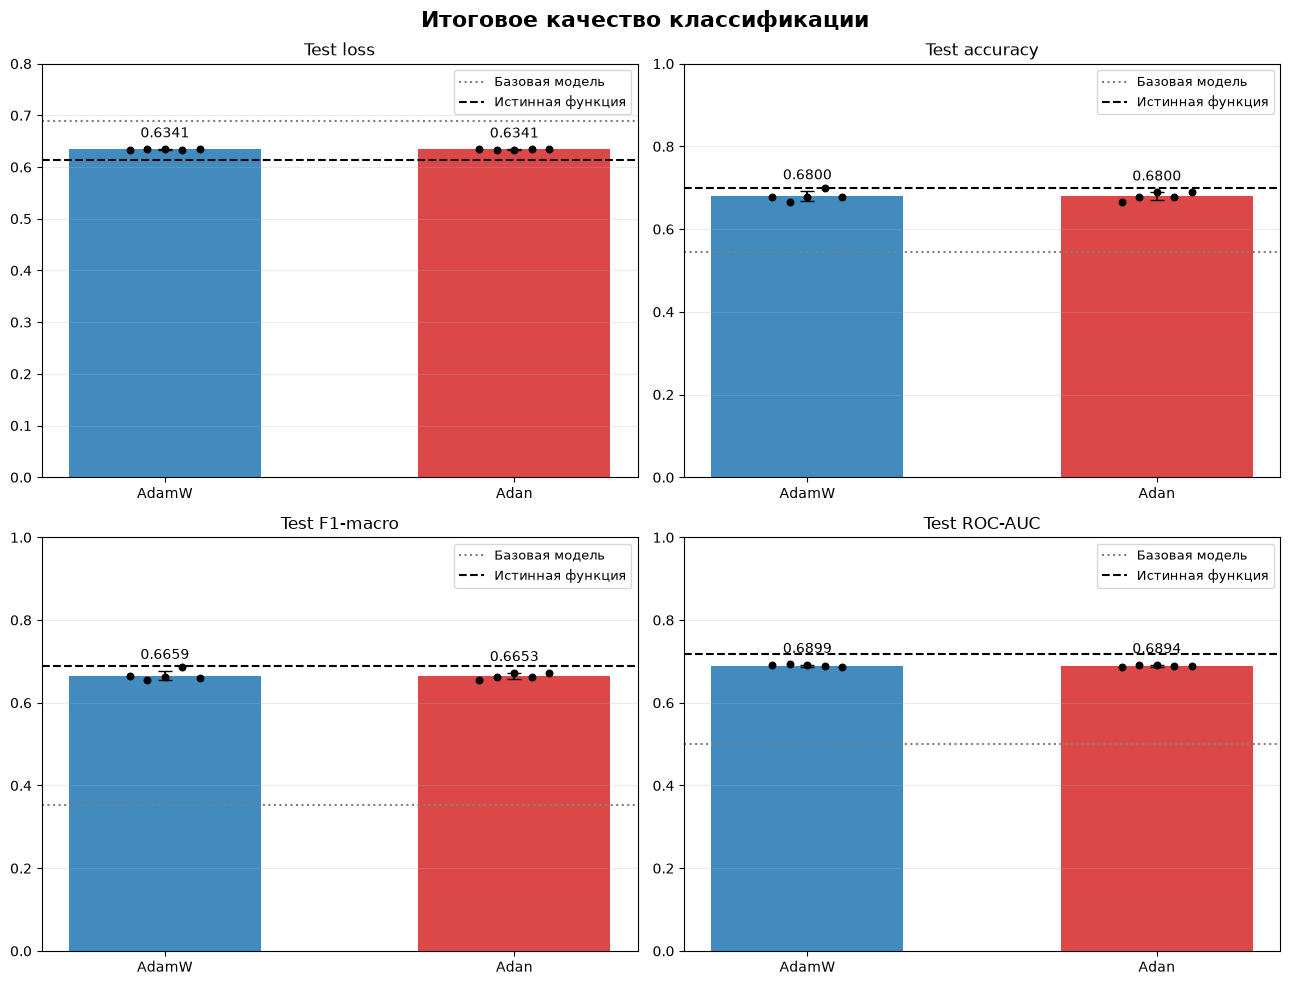

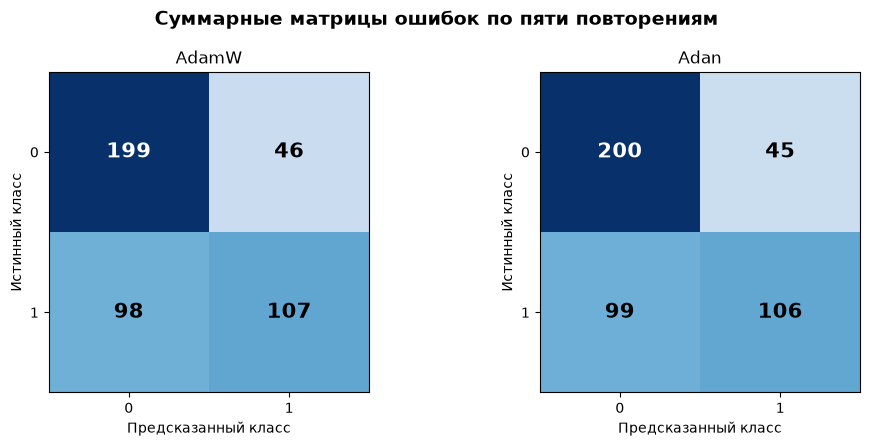

Лидеры по средним тестовым показателям:


Критерий,Метод,Среднее значение
Test loss,Adan,0.63406088
Test accuracy,"AdamW, Adan",0.68000000
Test F1-macro,AdamW,0.66592424
Test ROC-AUC,AdamW,0.68989547



Количество оценённых моделей: 10
Количество тестовых наблюдений: 90
Количество классификаций для каждого метода: 450
Матрицы ошибок объединяют прогнозы пяти моделей на одной тестовой выборке.
450 классификаций не являются 450 независимыми наблюдениями.
Лучшие состояния выбраны исключительно по Validation.
Гиперпараметры после тестирования не изменялись.
Статистическая значимость различий не устанавливалась.
Итоговая оценка классификации завершена.


In [12]:
# =============================================
# Метрики качества классификации
# =============================================

def classification_metrics(theta, X_data, y_data):

    with torch.no_grad():

        loss = loss_value(
            theta, X_data, y_data
        ).item()

        probabilities = predict_proba(
            theta, X_data
        ).cpu().numpy().ravel()

    targets = y_data.cpu().numpy().ravel().astype(int)

    predictions = (
        probabilities >= classification_threshold
    ).astype(int)

    return {
        "loss": loss,

        "accuracy": accuracy_score(
            targets, predictions
        ),

        "f1_macro": f1_score(
            targets, predictions,
            average="macro",
            labels=[0, 1],
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            targets, probabilities
        ),

        "confusion_matrix": confusion_matrix(
            targets, predictions,
            labels=[0, 1]
        ),

        "probabilities": probabilities,

        "predictions": predictions
    }


# =============================================
# Проверка выбора лучших состояний
# до обращения к тестовой выборке
# =============================================

for result in experiment_results.values():

    history = result["iteration_history"]

    valid_history = [
        record for record in history
        if record["diagnostics_finite"]
    ]

    expected_best = min(
        valid_history,
        key=lambda record: record["validation_loss"]
    )

    assert result["best_record"]["iteration"] == (
        expected_best["iteration"]
    )

    assert torch.equal(
        result["best_theta"],
        expected_best["theta"]
    )

    assert result["settings"] == config[result["method"]]


# =============================================
# Оценка моделей
# =============================================

final_quality_records = []

test_quality_records = []

test_predictions = {}

for (method, network_seed), result in experiment_results.items():

    final_theta = result["final_theta"].clone()

    best_theta = result["best_theta"].clone()

    best_iteration = result["best_record"]["iteration"]

    # Качество после 200 обновлений
    final_train = classification_metrics(
        final_theta, X_train, y_train
    )

    final_val = classification_metrics(
        final_theta, X_val, y_val
    )

    final_quality_records.append({
        "method": method,
        "seed": network_seed,

        "train_loss": final_train["loss"],
        "train_accuracy": final_train["accuracy"],
        "train_f1_macro": final_train["f1_macro"],
        "train_roc_auc": final_train["roc_auc"],

        "validation_loss": final_val["loss"],
        "validation_accuracy": final_val["accuracy"],
        "validation_f1_macro": final_val["f1_macro"],
        "validation_roc_auc": final_val["roc_auc"]
    })

    # Качество состояния, выбранного по Validation
    best_train = classification_metrics(
        best_theta, X_train, y_train
    )

    best_val = classification_metrics(
        best_theta, X_val, y_val
    )

    assert np.isclose(
        best_val["loss"],
        result["best_record"]["validation_loss"],
        atol=1e-12,
        rtol=1e-10
    )

    # Итоговая оценка на Test
    test_result = classification_metrics(
        best_theta, X_test, y_test
    )

    test_quality_records.append({
        "method": method,
        "seed": network_seed,
        "best_iteration": best_iteration,

        "train_loss": best_train["loss"],
        "train_accuracy": best_train["accuracy"],
        "train_f1_macro": best_train["f1_macro"],

        "validation_loss": best_val["loss"],
        "validation_accuracy": best_val["accuracy"],
        "validation_f1_macro": best_val["f1_macro"],

        "test_loss": test_result["loss"],
        "test_accuracy": test_result["accuracy"],
        "test_f1_macro": test_result["f1_macro"],
        "test_roc_auc": test_result["roc_auc"]
    })

    test_predictions[(method, network_seed)] = test_result

    # Проверка сохранности параметров
    assert torch.equal(
        final_theta, result["final_theta"]
    )

    assert torch.equal(
        best_theta, result["best_theta"]
    )


final_quality_df = (
    pd.DataFrame(final_quality_records)
    .sort_values(["method", "seed"])
    .reset_index(drop=True)
)

test_quality_df = (
    pd.DataFrame(test_quality_records)
    .sort_values(["method", "seed"])
    .reset_index(drop=True)
)

assert len(final_quality_df) == 10
assert len(test_quality_df) == 10

assert not test_quality_df.duplicated(
    ["method", "seed"]
).any()


# =============================================
# Качество после 200 обновлений
# =============================================

print("Качество моделей после 200 обновлений:")

display(
    final_quality_df.rename(columns={
        "method": "Метод",
        "seed": "Seed",

        "train_loss": "Train loss",
        "train_accuracy": "Train accuracy",
        "train_f1_macro": "Train F1-macro",
        "train_roc_auc": "Train ROC-AUC",

        "validation_loss": "Validation loss",
        "validation_accuracy": "Validation accuracy",
        "validation_f1_macro": "Validation F1-macro",
        "validation_roc_auc": "Validation ROC-AUC"
    })
    .style.hide(axis="index")
    .format(precision=6)
)


# =============================================
# Индивидуальные тестовые результаты
# =============================================

test_columns = {
    "method": "Метод",
    "seed": "Seed",
    "best_iteration": "Лучшая итерация",
    "validation_loss": "Validation loss",
    "test_loss": "Test loss",
    "test_accuracy": "Test accuracy",
    "test_f1_macro": "Test F1-macro",
    "test_roc_auc": "Test ROC-AUC"
}

print("\nИтоговые результаты на тестовой выборке:")

display(
    test_quality_df[list(test_columns)]
    .rename(columns=test_columns)
    .style.hide(axis="index")
    .format({
        "Validation loss": "{:.8f}",
        "Test loss": "{:.8f}",
        "Test accuracy": "{:.2%}",
        "Test F1-macro": "{:.6f}",
        "Test ROC-AUC": "{:.6f}"
    })
)


# =============================================
# Среднее и стандартное отклонение
# =============================================

test_metrics = {
    "test_loss": "Test loss",
    "test_accuracy": "Test accuracy",
    "test_f1_macro": "Test F1-macro",
    "test_roc_auc": "Test ROC-AUC"
}

test_stats = (
    test_quality_df
    .groupby("method")[list(test_metrics)]
    .agg(["mean", "std"])
    .reindex(methods)
)

test_summary = pd.DataFrame(
    index=list(test_metrics.values()),
    columns=methods,
    dtype=object
)

for metric, label in test_metrics.items():

    for method in methods:

        mean = test_stats.loc[method, (metric, "mean")]

        std = test_stats.loc[method, (metric, "std")]

        if metric == "test_accuracy":

            value = (
                f"{mean:.2%} ± {std * 100:.2f} п.п."
            )

        else:

            value = f"{mean:.6f} ± {std:.6f}"

        test_summary.loc[label, method] = value

print("\nСводное качество классификации:")
print("Среднее ± выборочное стандартное отклонение")

display(test_summary)


# =============================================
# Базовые и теоретические ориентиры
# =============================================

y_test_numpy = y_test.numpy().ravel().astype(int)

p_test_true = p_true[test_idx]

p_train_mean = y_train.mean().item()


def probability_metrics(probabilities, targets):

    probabilities = np.asarray(probabilities)

    safe_probabilities = np.clip(
        probabilities, 1e-15, 1 - 1e-15
    )

    predictions = (
        probabilities >= classification_threshold
    ).astype(int)

    loss = -np.mean(
        targets * np.log(safe_probabilities)
        + (1 - targets) * np.log(1 - safe_probabilities)
    )

    return {
        "Test loss": loss,

        "Accuracy": accuracy_score(
            targets, predictions
        ),

        "F1-macro": f1_score(
            targets, predictions,
            average="macro",
            labels=[0, 1],
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            targets, probabilities
        )
    }


baseline_records = []

for name, probabilities in [
    (
        "Постоянная вероятность 0.5",
        np.full(len(y_test_numpy), 0.5)
    ),
    (
        "Частота класса 1 в Train",
        np.full(len(y_test_numpy), p_train_mean)
    ),
    (
        "Истинная функция вероятностей",
        p_test_true
    )
]:

    baseline_records.append({
        "Модель": name,
        **probability_metrics(
            probabilities, y_test_numpy
        )
    })

baseline_df = pd.DataFrame(baseline_records)

print("\nБазовые и теоретические ориентиры на Test:")

display(
    baseline_df.style
    .hide(axis="index")
    .format({
        "Test loss": "{:.8f}",
        "Accuracy": "{:.2%}",
        "F1-macro": "{:.6f}",
        "ROC-AUC": "{:.6f}"
    })
)


# =============================================
# Ожидаемые байесовские характеристики
# =============================================

expected_test_accuracy = np.mean(
    np.maximum(p_test_true, 1 - p_test_true)
)

expected_test_loss = -np.mean(
    p_test_true * np.log(p_test_true)
    + (1 - p_test_true) * np.log(1 - p_test_true)
)

print("\nТеоретические ожидаемые характеристики Test:")

print(
    "Ожидаемая байесовская accuracy:",
    f"{expected_test_accuracy:.4%}"
)

print(
    "Минимальная ожидаемая BCE:",
    f"{expected_test_loss:.8f}"
)


# =============================================
# Парное сравнение тестовых метрик
# =============================================

test_pair_records = []

test_pair_summary_records = []

for metric, label in test_metrics.items():

    paired = test_quality_df.pivot(
        index="seed",
        columns="method",
        values=metric
    )

    differences = paired["Adan"] - paired["AdamW"]

    for network_seed in network_seeds:

        test_pair_records.append({
            "Показатель": label,
            "Seed": network_seed,

            "AdamW": paired.loc[
                network_seed, "AdamW"
            ],

            "Adan": paired.loc[
                network_seed, "Adan"
            ],

            "Adan − AdamW": differences.loc[
                network_seed
            ]
        })

    # Для loss меньше — лучше.
    # Для остальных метрик больше — лучше.
    advantage = (
        -differences
        if metric == "test_loss"
        else differences
    )

    test_pair_summary_records.append({
        "Показатель": label,

        "Средняя разность Adan − AdamW": (
            differences.mean()
        ),

        "Стандартное отклонение разности": (
            differences.std(ddof=1)
        ),

        "Лучше Adan": int(
            (advantage > 1e-12).sum()
        ),

        "Лучше AdamW": int(
            (advantage < -1e-12).sum()
        ),

        "Совпадения": int(
            (advantage.abs() <= 1e-12).sum()
        )
    })

test_pair_df = pd.DataFrame(test_pair_records)

test_pair_summary_df = pd.DataFrame(
    test_pair_summary_records
)

print("\nПарное сравнение тестовых результатов:")

display(
    test_pair_df.style
    .hide(axis="index")
    .format({
        "AdamW": "{:.8f}",
        "Adan": "{:.8f}",
        "Adan − AdamW": "{:+.8f}"
    })
)

print("\nСводные результаты парного сравнения:")

display(
    test_pair_summary_df.style
    .hide(axis="index")
    .format({
        "Средняя разность Adan − AdamW": "{:+.8f}",

        "Стандартное отклонение разности": "{:.8f}"
    })
)


# =============================================
# Визуализация тестового качества
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

baseline_metric_names = {
    "test_loss": "Test loss",
    "test_accuracy": "Accuracy",
    "test_f1_macro": "F1-macro",
    "test_roc_auc": "ROC-AUC"
}

for ax, (metric, label) in zip(
    axes.flat, test_metrics.items()
):

    means = [
        test_stats.loc[method, (metric, "mean")]
        for method in methods
    ]

    stds = [
        test_stats.loc[method, (metric, "std")]
        for method in methods
    ]

    bars = ax.bar(
        methods,
        means,
        yerr=stds,
        capsize=5,
        width=0.55,
        color=[method_colors[m] for m in methods],
        alpha=0.85
    )

    # Индивидуальные результаты пяти повторений
    for i, method in enumerate(methods):

        values = test_quality_df.loc[
            test_quality_df["method"] == method,
            metric
        ].to_numpy()

        ax.scatter(
            i + np.linspace(-0.1, 0.1, len(values)),
            values,
            color="black",
            s=22,
            zorder=5
        )

    baseline_column = baseline_metric_names[metric]

    baseline_value = baseline_df.loc[
        1, baseline_column
    ]

    true_value = baseline_df.loc[
        2, baseline_column
    ]

    ax.axhline(
        baseline_value,
        color="gray",
        linestyle=":",
        linewidth=1.5,
        label="Базовая модель"
    )

    ax.axhline(
        true_value,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Истинная функция"
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.4f}" for value in means],
        padding=6
    )

    ax.set_title(label)

    ax.set_ylim(
        0,
        max(
            1.0 if metric != "test_loss" else 0.8,
            max(np.array(means) + np.array(stds)) * 1.15,
            baseline_value * 1.1,
            true_value * 1.1
        )
    )

    ax.grid(axis="y", alpha=0.25)

    ax.legend(fontsize=9)

fig.suptitle(
    "Итоговое качество классификации",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Суммарные матрицы ошибок
# =============================================

summed_confusion_matrices = {}

for method in methods:

    matrix = np.sum([
        test_predictions[(method, network_seed)][
            "confusion_matrix"
        ]
        for network_seed in network_seeds
    ], axis=0)

    assert matrix.sum() == len(X_test) * n_repeats

    summed_confusion_matrices[method] = matrix


fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4.5)
)

max_count = max(
    matrix.max()
    for matrix in summed_confusion_matrices.values()
)

for ax, method in zip(axes, methods):

    matrix = summed_confusion_matrices[method]

    ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=max_count
    )

    for i in range(2):

        for j in range(2):

            ax.text(
                j, i,
                str(matrix[i, j]),
                ha="center",
                va="center",
                fontsize=15,
                fontweight="bold",
                color=(
                    "white"
                    if matrix[i, j] > max_count * 0.65
                    else "black"
                )
            )

    ax.set_title(method)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

fig.suptitle(
    "Суммарные матрицы ошибок по пяти повторениям",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Итоговое сравнение тестовых метрик
# =============================================

leader_records = []

for metric, label in test_metrics.items():

    values = test_stats[(metric, "mean")]

    best_value = (
        values.min()
        if metric == "test_loss"
        else values.max()
    )

    leaders = [
        method for method in methods
        if np.isclose(
            values.loc[method],
            best_value,
            atol=1e-12,
            rtol=0
        )
    ]

    leader_records.append({
        "Критерий": label,

        "Метод": ", ".join(leaders),

        "Среднее значение": best_value
    })

print("Лидеры по средним тестовым показателям:")

display(
    pd.DataFrame(leader_records)
    .style.hide(axis="index")
    .format({
        "Среднее значение": "{:.8f}"
    })
)


# =============================================
# Итоговые проверки
# =============================================

assert len(test_predictions) == 10

assert np.isfinite(
    test_quality_df[list(test_metrics)].to_numpy()
).all()

print("\nКоличество оценённых моделей:", len(test_predictions))

print("Количество тестовых наблюдений:", len(X_test))

print(
    "Количество классификаций для каждого метода:",
    len(X_test) * n_repeats
)

print(
    "Матрицы ошибок объединяют прогнозы пяти моделей "
    "на одной тестовой выборке."
)

print(
    "450 классификаций не являются "
    "450 независимыми наблюдениями."
)

print("Лучшие состояния выбраны исключительно по Validation.")

print("Гиперпараметры после тестирования не изменялись.")

print("Статистическая значимость различий не устанавливалась.")

print("Итоговая оценка классификации завершена.")

## Итоговое сравнение AdamW и Adan

В ходе работы были самостоятельно реализованы оптимизаторы AdamW и Adan. Сравнение проводилось на синтетической выборке из 600 наблюдений с использованием нейронной сети архитектуры 3 → 8 → 1, содержащей 41 обучаемый параметр.

Для каждого метода выполнено пять повторений по 200 обновлений параметров. Внутри каждого повтора использовались одинаковые начальные веса и последовательности мини-батчей. Скорость обучения обоих оптимизаторов составляла 0.005. Дополнительный подбор гиперпараметров не проводился.

## Качество и скорость оптимизации

| Показатель | AdamW | Adan |
|---|---:|---:|
| Начальный train loss | 0.714279 | 0.714279 |
| Конечный train loss | 0.606865 ± 0.000567 | 0.607962 ± 0.001472 |
| Конечный validation loss | 0.637443 ± 0.003853 | 0.635283 ± 0.002958 |
| Минимальный validation loss | 0.631357 ± 0.002694 | 0.632327 ± 0.002261 |
| Лучшая итерация | 95.40 ± 35.12 | 129.00 ± 47.12 |
| Конечная норма полного градиента | 0.017681 ± 0.007087 | 0.017228 ± 0.008343 |
| Уменьшение train loss | 14.52% | 14.37% |
| Конечный разрыв между Train и Validation | 0.030578 | 0.027321 |

AdamW во всех пяти повторениях показал меньший конечный train loss. Минимальные валидационные потери также достигались раньше: в среднем на 95.4-й итерации против 129-й у Adan.

При этом после 200 обновлений Adan показал меньший validation loss в четырёх из пяти повторений. Разрыв между обучающими и валидационными потерями у него также оказался меньше.

Установленного контрольного уровня

$$
L_{\mathrm{val}}\leq0.60
$$

не достиг ни один из оптимизаторов. Поэтому сравнить количество шагов и время достижения данного уровня невозможно.

Преимущество Adan по скорости уменьшения обучающих потерь в заданных условиях не подтвердилось.

## Устойчивость оптимизации

Оба метода успешно выполнили все предусмотренные обновления. Отклонённых шагов и нечисловых значений не обнаружено.

| Показатель | AdamW | Adan |
|---|---:|---:|
| Принятые обновления | 1000 | 1000 |
| Отклонённые обновления | 0 | 0 |
| Средняя норма обновления | 0.009524 | 0.007353 |
| Разброс норм обновлений | 0.005683 | 0.004557 |
| Косинусное сходство с направлением спуска | 0.446861 | 0.617754 |
| Доля направлений спуска | 82.7% | 94.5% |
| Увеличения train loss | 183 | 58 |
| Увеличения validation loss | 372 | 276 |

Средняя норма обновления параметров Adan оказалась на 22.79% меньше, а разброс норм обновлений — на 19.81% меньше.

Для проверки согласованности обновлений с направлением спуска полной обучающей функции использовалось условие:

$$
\nabla L_{\mathrm{train}}(\theta_{t-1})^T
\Delta\theta_t<0.
$$

Adan удовлетворял данному условию в 94.5% случаев, AdamW — в 82.7%.

Количество увеличений обучающих потерь у Adan оказалось меньше на 68.31%, а валидационных — на 25.81%.

Таким образом, Adan показал более плавную траекторию оптимизации, несмотря на менее быстрое уменьшение обучающих потерь.

## Анализ механизма Adan

Основное отличие Adan от AdamW заключается в использовании разности последовательных стохастических градиентов:

$$
\Delta g_t=g_t-g_{t-1}.
$$

При отсутствии регуляризации обновление параметров Adan имеет вид:

$$
\Delta\theta_t=
-\eta
\frac{\hat m_t+\beta_2\hat v_t}
{\sqrt{\hat n_t}+\varepsilon}.
$$

Для исследования данного механизма обновление было разложено на основную составляющую и составляющую коррекции Нестерова:

$$
\Delta\theta_t=
-\eta\frac{\hat m_t}
{\sqrt{\hat n_t}+\varepsilon}
-\eta\frac{\beta_2\hat v_t}
{\sqrt{\hat n_t}+\varepsilon}.
$$

Максимальная погрешность восстановления фактического обновления составила

$$
5.59\cdot10^{-17},
$$

что подтверждает численную корректность разложения.

| Тип мини-батча | Норма разности градиентов | Отношение норм дополнительной и основной составляющих |
|---|---:|---:|
| Неполный батч из 4 наблюдений | 0.482911 | 43.46% |
| Первый батч после неполного | 0.491553 | 15.87% |
| Остальные полные батчи | 0.230706 | 22.28% |

При обработке неполных мини-батчей наблюдались более значительные изменения стохастических градиентов. Вклад коррекции Нестерова в обновление параметров также возрастал.

Ранее проведённая проверка при фиксированных параметрах сети показала, что разности градиентов возникают даже без изменения параметров. Следовательно, они содержат не только информацию об изменении градиента при движении по поверхности функции потерь, но и составляющую, связанную с изменением состава мини-батчей.

Меньшие нормы обновлений Adan согласуются с наблюдаемой плавностью его траектории. Однако установить влияние каждого отдельного компонента алгоритма на скорость обучения нельзя, поскольку эксперимент с отключением отдельных составляющих не проводился.

## Вычислительные затраты

Средние результаты одного запуска из 200 обновлений:

| Показатель | AdamW | Adan |
|---|---:|---:|
| Основные вычисления функции потерь | 200 | 200 |
| Основные обратные проходы | 200 | 200 |
| Диагностические обратные проходы | 201 | 201 |
| Всего обратных проходов | 401 | 401 |
| Всего вычислений функции потерь | 602 | 602 |
| Обработано наблюдений при оптимизации | 6008 | 6008 |
| Вычисления разности градиентов | 0 | 199 |
| Операции с матрицами кривизны | 0 | 0 |
| Время оптимизации, мс | 65.7865 ± 3.3475 | 72.1123 ± 1.1392 |
| Полное время, мс | 153.2743 ± 6.6962 | 164.4331 ± 5.6932 |
| Пиковая память PyTorch, КиБ | 9.0078 | 9.6484 |
| Пиковая память Python, КиБ | 43.2188 | 43.5859 |
| Количество выделений памяти PyTorch | 15407 | 20811 |
| Постоянное числовое состояние, байт | 656 | 1312 |

Оба метода относятся к методам первого порядка и имеют одинаковую асимптотическую сложность обновления параметров:

$$
T_{\mathrm{AdamW}}=O(P),
\qquad
T_{\mathrm{Adan}}=O(P),
$$

где $P$ — количество обучаемых параметров.

При этом Adan выполняет больше покомпонентных операций и хранит дополнительные векторы состояния.

Для AdamW объём постоянного числового состояния составляет:

$$
M_{\mathrm{AdamW}}=2\cdot41\cdot8=656
\text{ байт}.
$$

Для Adan:

$$
M_{\mathrm{Adan}}=4\cdot41\cdot8=1312
\text{ байт}.
$$

По сравнению с AdamW метод Adan потребовал:

- на 9.62% больше времени оптимизации;
- на 7.11% больше пиковой памяти PyTorch;
- на 35.07% больше выделений памяти;
- в два раза больше постоянной числовой памяти.

AdamW оказался быстрее во всех пяти повторениях.

Таким образом, использование разности градиентов не потребовало дополнительных обратных проходов, однако увеличило вычислительные затраты на выполнение обновлений.

Измеренная пиковая память характеризует зарегистрированные выделения PyTorch и Python, а не полный объём оперативной памяти процесса.

## Итоговое качество классификации

Для тестовой оценки использовались параметры сети, соответствующие минимальному validation loss каждого запуска.

$$
t^*=
\arg\min_{t\in\{0,\ldots,200\}}
L_{\mathrm{val}}(\theta_t).
$$

| Метрика | AdamW | Adan |
|---|---:|---:|
| Test loss | 0.634087 ± 0.000880 | 0.634061 ± 0.000546 |
| Accuracy | 68.00% ± 1.22 п.п. | 68.00% ± 0.93 п.п. |
| F1-macro | 0.665924 ± 0.011843 | 0.665347 ± 0.007312 |
| ROC-AUC | 0.689895 ± 0.002538 | 0.689398 ± 0.002308 |

Оба оптимизатора достигли одинаковой средней точности классификации — 68%.

Adan показал немного меньший Test loss, а AdamW — немного большие значения F1-macro и ROC-AUC. Различия между средними результатами малы относительно разброса парных значений.

При этом стандартное отклонение всех четырёх тестовых метрик у Adan оказалось меньше.

### Сравнение с базовыми моделями

| Модель | Test loss | Accuracy | F1-macro | ROC-AUC |
|---|---:|---:|---:|---:|
| Постоянная вероятность 0.5 | 0.693147 | 45.56% | 0.312977 | 0.500000 |
| Частота положительного класса в Train | 0.689254 | 54.44% | 0.352518 | 0.500000 |
| AdamW | 0.634087 | 68.00% | 0.665924 | 0.689895 |
| Adan | 0.634061 | 68.00% | 0.665347 | 0.689398 |
| Истинная функция вероятностей | 0.612765 | 70.00% | 0.688900 | 0.716775 |

Оба метода превзошли базовые классификаторы по всем рассматриваемым метрикам.

Ожидаемая байесовская точность на тестовых признаках составила 67.9883%, а минимальная ожидаемая BCE — 0.59765885.

Средняя эмпирическая accuracy обученных моделей численно близка к ожидаемой байесовской точности. Однако это не означает достижения байесовского оптимума, поскольку ожидаемая и эмпирическая точность являются различными характеристиками.

Истинная функция вероятностей на конкретной тестовой выборке показала лучшие результаты по всем четырём метрикам.

## Сопоставление с результатами научной статьи

В статье Xie X. et al. авторы демонстрируют преимущества Adan по скорости сходимости и качеству обучения различных глубоких нейронных сетей.

В проведённом эксперименте преимущество по скорости обучения не подтвердилось. При одинаковой скорости обучения и одинаковом количестве обратных проходов AdamW быстрее уменьшал обучающие потери и требовал меньше вычислительных ресурсов.

При этом у Adan обнаружено преимущество по отдельным характеристикам устойчивости: меньшие нормы обновлений, меньшее количество увеличений функции потерь и более высокая согласованность обновлений с направлением полного градиента.

Возможные причины расхождения с результатами статьи:

- небольшая архитектура сети, содержащая 41 параметр;
- ограниченный объём синтетических данных;
- вероятностный характер целевой переменной;
- высокая стохастичность градиентов отдельных мини-батчей;
- ограниченный бюджет обучения в 200 обновлений;
- фиксированная скорость обучения без дополнительного подбора;
- выполнение вычислений на CPU.

Перечисленные факторы являются возможными объяснениями расхождения, поскольку их влияние отдельно не исследовалось.

## Сводное сравнение методов

| Критерий | Результат |
|---|---|
| Минимальные конечные обучающие потери | AdamW |
| Минимальные конечные валидационные потери | Adan |
| Минимальный validation loss за обучение | AdamW |
| Более плавная траектория оптимизации | Adan |
| Согласованность с направлением спуска | Adan |
| Минимальное время оптимизации | AdamW |
| Минимальные затраты памяти | AdamW |
| Средняя тестовая accuracy | Одинаковая |
| Средние тестовые метрики | Близкие результаты |
| Меньший разброс тестовых метрик | Adan |
| Достижение контрольного уровня 0.60 | Ни один метод |

## Ограничения исследования

Эксперимент проводился на одной синтетической выборке с фиксированным разбиением данных. Использовалось пять повторений с различными начальными параметрами сети и последовательностями мини-батчей.

Тестовая выборка содержала 90 наблюдений. Стандартные отклонения характеризуют разброс результатов между повторениями, но не учитывают изменчивость, связанную с генерацией новых наборов данных.

Статистическая значимость различий между оптимизаторами не устанавливалась. Полученные измерения времени и памяти также зависят от программной реализации и вычислительной среды.

## Вывод

В ходе работы был воспроизведён алгоритм Adan по математическим формулам научной публикации с учётом особенностей практической реализации авторов. Корректность обновлений параметров и накопленных моментов подтверждена контрольными проверками.

При одинаковом бюджете обучения AdamW оказался быстрее и потребовал меньше вычислительных ресурсов. Adan показал более плавную траекторию оптимизации, чаще формировал направления спуска и реже допускал увеличение функции потерь.

Итоговое качество классификации оказалось практически одинаковым: средняя accuracy обоих методов составила 68%. При этом Adan показал меньший разброс тестовых метрик между повторениями.

Заявленное авторами преимущество Adan по скорости обучения и итоговому качеству в рамках данной синтетической задачи не подтвердилось. Преимущество проявилось только по отдельным характеристикам устойчивости оптимизации.

Полученные результаты не опровергают выводы научной статьи, поскольку условия проведённого эксперимента существенно отличаются от условий обучения глубоких нейронных сетей, исследованных авторами.
